# SisaRasa v4: Pencarian Resep Berdasarkan Bahan Sisa

**Pengembang:** Farros Rifantiarno Ramadhani (A11.2024.15694)  
**Mata kuliah:** Sistem Temu Kembali Informasi

## Tujuan
SisaRasa mencari resep berdasarkan bahan yang dimiliki. Setiap resep merupakan dokumen; daftar bahan pengguna adalah query. Hasil menampilkan bahan yang cocok dan bahan inti yang masih diperlukan.

## Pipeline v4
1. Menyiapkan lingkungan dan memuat dataset resep dari sumber lokal atau daring.
2. Menyatukan skema, menyaring data tidak lengkap, dan menghapus duplikat.
3. Menormalkan satuan, sinonim, instruksi, dan nama bahan majemuk.
4. Membangun indeks Set-Overlap, TF-IDF Cosine, BM25, dan SisaRasa Hybrid.
5. Menguji kesesuaian terhadap pseudo-qrels serta kemampuan menemukan resep sumber sebagai dua tujuan terpisah.
6. Menampilkan pencarian dan menyimpan hasil evaluasi dalam direktori run baru.

## Normalisasi query
Nama seperti `bawang goreng` dipertahankan sebagai satu bahan. Salah eja terdaftar `bwang greng` dan `bawang purih` dibakukan otomatis pada korpus dan query.

Typo lain seperti `minyk`, `thu`, dan `susi` menghasilkan saran dari kamus bahan tepercaya. Saran tidak mengganti input sampai pengguna memilih. Kemunculan typo dalam data resep tidak otomatis membuatnya dianggap benar. Kandidat yang ditawarkan mengikuti ketersediaan bahan dalam korpus yang terdaftar.

Setelah pipeline dan definisi pencarian tersedia:

```python
PARSER.suggest_query("minyk, thu, susi")

search_sisarasa(
    "minyk, thu, susi",
    ingredient_choices={
        "minyk": "minyak goreng",
        "thu": "tahu",
        "susi": "susu cair",
    },
)
```

Gunakan pilihan yang benar-benar muncul dalam saran. Pilihan tidak valid atau sudah tidak tersedia ditolak. Tanpa `ingredient_choices`, pencarian memakai input semula dan menampilkan saran. Hasil menyimpan input asli, query yang dipakai, saran tersisa, dan koreksi dalam `DataFrame.attrs`.

`susu`, `susu cair`, dan `susu bubuk` tetap bahan berbeda; pengguna memilih jenis yang dimiliki. Pencocokan ejaan memakai jumlah kata sama, minimal tiga huruf per kata input, maksimal satu edit per kata, dan dua edit per frasa. Varian bahan dapat ditawarkan sebagai pilihan tambahan. Pertukaran posisi huruf belum didukung. Mekanisme ini bukan pemahaman semantik atau jaminan semua typo terdeteksi.

## Cara membaca evaluasi
- **Proxy recommendation:** metrik mengukur kesesuaian ranking dengan rubric bahan otomatis, bukan penilaian manusia. Beberapa sinyal rubric juga digunakan Hybrid.
- **Pemulihan resep sumber:** Hit@k dan MRR@10 mengukur apakah resep sumber ditemukan dari sampel bahannya. Resep lain belum tentu tidak relevan.
- Query sintetis menggunakan bahan kanonik dalam kamus parser dan tidak mewakili seluruh kosakata pengguna. Pembagian keluarga bukan bukti performa pengguna nyata. Hybrid tidak wajib menang; laporkan hasil aktual setiap model.
- Pemeriksaan ejaan membandingkan contoh query bersih dan typo. Contoh sintetis tidak mewakili seluruh kesalahan pengguna.

> Setelah parser, daftar protein, atau rubric berubah, jalankan ulang dengan kernel baru. Hasil benchmark, evaluasi, dan riset harus memakai versi yang sama sebelum diekspor. Baca versi normalisasi dan rubric pada `metadata.json` dalam direktori run; jangan memakai hasil historis sebagai hasil kode terbaru.

## Efek samping
Menjalankan seluruh notebook dapat memasang paket, membaca konfigurasi lokal, mengunduh data, menulis atau menimpa cache data, membuat direktori, dan menulis hasil evaluasi. Ekspor korpus dan indeks harus dipanggil secara eksplisit ke direktori baru.

## Pertanyaan penelitian dan dugaan kerja

Notebook ini merupakan studi eksperimental STKI untuk mendukung pencarian resep berdasarkan bahan. Unit dokumen adalah satu resep; query berupa daftar bahan. Penelitian dibatasi pada kesesuaian ranking terhadap aturan bahan otomatis, pemulihan resep sumber, serta diagnostik salah eja.

| Pertanyaan | Eksperimen | Ukuran yang dibaca |
|---|---|---|
| RQ1: Bagaimana Hybrid dibanding Set-Overlap, TF-IDF Cosine, dan BM25? | Korpus, query, split, dan pseudo-qrels yang sama | nDCG@10, MAP@10, P@5; menang/seri/kalah per query |
| RQ2: Apa pengaruh komponen protein dan penalti bahan kurang? | Hybrid lengkap; tanpa protein; tanpa penalti bahan kurang | Perubahan metrik pada split yang sama |
| RQ3: Seberapa baik saran bahan menangani salah eja? | Manifest diagnostik tetap, input valid dan kata tidak dikenal | Kandidat benar ditawarkan, normalisasi sebelum/sesudah pilihan, saran keliru, konsistensi ranking |

Dugaan kerja: penambahan sinyal kuliner dapat membantu sebagian query, tetapi dapat merugikan query lain. Saran ejaan dapat memulihkan sebagian input, sedangkan input pendek dan pertukaran huruf dapat gagal. Tidak ada kewajiban bahwa Hybrid atau versi lengkap memenangkan semua metrik.

**Status analisis:** pertanyaan, pemilihan metrik utama nDCG@10, serta ablation disusun setelah hasil awal diperiksa. Analisis ini eksploratif. Split yang bernama `test` tidak diperlakukan sebagai data yang belum pernah dilihat. Tidak ada klaim signifikansi statistik.

## Rencana eksperimen UTS

1. Dokumentasikan sumber data, representasi bahan, rumus, parameter, dan batas validitas.
2. Jalankan ablation dengan satu bobot dinolkan, tanpa mengubah indeks, query, pseudo-qrels, atau bobot lainnya.
3. Jalankan 36 kasus diagnostik ejaan dengan target dan jenis kesalahan eksplisit. Catat kegagalan, target yang tidak tersedia, serta kontrol negatif.
4. Tampilkan perbandingan per query dan ambiguitas target sumber. Simpan manifest, hasil rinci, dan protokol bersama run baru pada Cell 12.
5. Verifikasi logika menggunakan fixture kecil, kompilasi sintaks, dan validasi format notebook. Hasil penuh eksperimen tambahan baru tersedia setelah sel riset dijalankan.

Rancangan ini memakai kode dan dependency yang sudah ada. Rubric `proxy_v3` memperbaiki pengenalan bagian telur sebagai protein tanpa menyamakan identitas bahannya. Bobot model utama dan ambang grade tetap. Tidak ada anotasi relevansi manusia, LLM-as-judge, tuning agar Hybrid menang, atau benchmark pengguna nyata dalam studi ini.

> Run historis dipertahankan dalam direktori terpisah. Output sel yang terdampak perubahan dibersihkan sampai eksperimen baru dijalankan; tabel baru tetap bersifat eksploratif.


In [ ]:
# ==============================================================================
# CELL 1: Package Installation, Imports & Seed Reproducibility
# ==============================================================================
import subprocess, sys, importlib

_REQUIRED = [
    "pandas", "numpy", "matplotlib", "seaborn", "tqdm",
    "scikit-learn", "rank_bm25", "pyarrow", "datasets", "kagglehub",
    "python-dotenv", "ipywidgets",
]

def _ensure_packages(packages):
    """Install missing packages quietly."""
    for pkg in packages:
        import_name = {"scikit-learn": "sklearn", "python-dotenv": "dotenv"}.get(pkg, pkg.replace("-", "_"))
        try:
            importlib.import_module(import_name)
        except ImportError:
            print(f"[INSTALL] Installing {pkg} ...")
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", pkg],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
            )

_ensure_packages(_REQUIRED)

# -- Core imports --------------------------------------------------------------
import os, re, ast, copy, math, json, time, hashlib, pickle, shutil, warnings
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from typing import List, Dict, Set, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# -- Reproducibility -----------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("[OK] Cell 1 selesai (SisaRasa v4): dependensi siap dan seed 42.")



In [ ]:
# ==============================================================================
# CELL 2: EnvironmentConfig: Automatic Environment Detection (Kaggle vs Local)
# ==============================================================================

class EnvironmentConfig:
    """Deteksi otomatis environment dan konfigurasi path direktori."""

    def __init__(self):
        self.IS_KAGGLE = os.path.exists("/kaggle/input") or ("KAGGLE_KERNEL_RUN_TYPE" in os.environ)

        if self.IS_KAGGLE:
            self.INPUT_DIR = Path("/kaggle/input")
            self.WORKING_DIR = Path("/kaggle/working")
            self.ARTIFACT_DIR = self.WORKING_DIR / "sisarasa_artifacts"
            self.DS1_SEARCH_DIRS = [self.INPUT_DIR]
            self.DS2_SEARCH_DIRS = [self.INPUT_DIR]
        else:
            # Deteksi root direktori proyek secara dinamis (apakah dijalankan dari root atau dari subfolder 'notebooks')
            current_cwd = Path(".").resolve()
            if (current_cwd / "artifacts").exists() or (current_cwd / "backend").exists():
                self.ROOT_DIR = current_cwd
            elif (current_cwd.parent / "artifacts").exists() or (current_cwd.parent / "backend").exists():
                self.ROOT_DIR = current_cwd.parent
            else:
                self.ROOT_DIR = current_cwd

            self.LOCAL_RAW_DIR = self.ROOT_DIR / "data" / "raw"
            self.ARTIFACT_DIR = self.ROOT_DIR / "artifacts"
            self.DS1_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-food-recipes",
                self.LOCAL_RAW_DIR,
                self.ROOT_DIR,
            ]
            self.DS2_SEARCH_DIRS = [
                self.LOCAL_RAW_DIR / "indonesian-recipes",
                self.LOCAL_RAW_DIR,
            ]

        # Inisialisasi folder output
        self.ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
        if not self.IS_KAGGLE:
            self.LOCAL_RAW_DIR.mkdir(parents=True, exist_ok=True)

        # Auto-load file .env jika tersedia di direktori lokal
        env_file = (self.ROOT_DIR / ".env") if not self.IS_KAGGLE else Path("./.env")
        if env_file.exists():
            try:
                with open(env_file, "r", encoding="utf-8") as f:
                    for line in f:
                        line = line.strip()
                        if line and not line.startswith("#") and "=" in line:
                            k, v = line.split("=", 1)
                            k, v = k.strip(), v.strip().strip("'\"")
                            if k and v:
                                os.environ[k] = v
                print("  [CONFIG] Berhasil membaca konfigurasi environment dari .env")
            except Exception as e:
                print(f"  [WARN] Gagal membaca file .env: {e}")

        self._print_info()

    def _print_info(self):
        env_label = "Kaggle Cloud Kernel" if self.IS_KAGGLE else "Local Machine Environment"
        print("-" * 65)
        print("  SisaRasa Environment Configuration")
        print(f"  Mode        : {env_label}")
        print(f"  Artifacts   : {self.ARTIFACT_DIR.resolve()}")
        try:
            import psutil
            mem_gb = psutil.virtual_memory().total / (1024**3)
            print(f"  System RAM  : {mem_gb:.1f} GB")
        except ImportError:
            pass
        print("-" * 65)


ENV = EnvironmentConfig()
print("[OK] Cell 2 selesai: konfigurasi environment aktif.")


## Data, unit analisis, dan penyaringan

Dua sumber yang digunakan oleh loader:

- [canggih/indonesian-food-recipes, Kaggle](https://www.kaggle.com/datasets/canggih/indonesian-food-recipes): resep yang dikelompokkan ke delapan kategori.
- [junwatu/indonesian-recipes, Hugging Face](https://huggingface.co/datasets/junwatu/indonesian-recipes): resep dengan judul, daftar bahan, dan langkah memasak.

Loader mengutamakan berkas lokal. Versi lokal dapat berbeda dari halaman sumber saat ini; jumlah dokumen aktual harus mengikuti output Cell 3, 4, dan 6. Notebook tidak memverifikasi lisensi atau izin penggunaan ulang gambar/teks; periksa ketentuan sumber sebelum distribusi produk.

Cell 4 menyamakan skema, menolak judul kosong dan resep dengan kurang dari dua baris bahan atau dua langkah. Deduplikasi pertama memakai URL serta pasangan judul dan bahan yang dinormalisasi. Deduplikasi kedua membandingkan himpunan token bahan dengan Jaccard >= 0.85 **hanya dalam kelompok judul normalisasi yang sama**. Ini tidak menjamin seluruh duplikat lintas judul sudah terhapus.

`doc_id` diberikan setelah penyaringan berdasarkan urutan baris. Perubahan data atau urutan dapat mengubah ID. Karena itu, qrels harus dipasangkan dengan korpus dan fingerprint run yang sesuai. Angka penyaringan dan distribusi sumber/kategori dicetak oleh pipeline; jangan mengganti angka aktual dengan angka dari run lama.

Korpus lengkap digunakan untuk membangun indeks. Pada retrieval konvensional ini bukan pelatihan prediktif yang otomatis membutuhkan pemisahan dokumen train/test. Pemisahan keluarga query ditujukan untuk mengurangi pengulangan intent antara dev dan test. Pengujian generalisasi ke resep atau pengguna baru merupakan pertanyaan berbeda.

Data resep dapat mengandung typo, alternatif bahan, kategori keliru, atau instruksi bercampur bahan. Sampel raw dan hasil parser pada sel riset merupakan bahan inspeksi, bukan ukuran akurasi parser yang sudah dinilai independen.


In [2]:
# ==============================================================================
# CELL 3: RecipeDataLoader: Dual-Source Data Acquisition (Kaggle & HuggingFace)
# ==============================================================================

class RecipeDataLoader:
    """Akuisisi otomatis Dataset 1 (Kaggle) & Dataset 2 (HuggingFace)."""

    DS1_CATEGORIES = ["ayam", "ikan", "kambing", "sapi", "tahu", "telur", "tempe", "udang"]

    # -- Dataset 1: canggih/indonesian-food-recipes -----------------------------
    @staticmethod
    def _find_ds1_csvs(search_dirs: list) -> List[Tuple[Path, str]]:
        """Cari file dataset-*.csv secara rekursif dan kembalikan (path, category)."""
        found = []
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for csv_path in sorted(d.rglob("dataset-*.csv")):
                stem = csv_path.stem.lower()
                for cat in RecipeDataLoader.DS1_CATEGORIES:
                    if cat in stem:
                        found.append((csv_path, cat))
                        break
        seen = set()
        unique = []
        for p, c in found:
            rp = p.resolve()
            if rp not in seen:
                seen.add(rp)
                unique.append((p, c))
        return unique

    @staticmethod
    def _download_ds1_kagglehub(target_dir: Path) -> List[Tuple[Path, str]]:
        """Fallback: download via kagglehub."""
        try:
            import kagglehub
            print("[DS1] Mengunduh canggih/indonesian-food-recipes via kagglehub ...")
            dl_path = kagglehub.dataset_download("canggih/indonesian-food-recipes")
            dl_path = Path(dl_path)
            target_dir.mkdir(parents=True, exist_ok=True)
            for f in dl_path.rglob("*.csv"):
                shutil.copy2(f, target_dir / f.name)
            return RecipeDataLoader._find_ds1_csvs([target_dir])
        except Exception as e:
            print(f"[DS1] [WARN] kagglehub download gagal: {e}")
            return []

    @classmethod
    def load_dataset1(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load & gabungkan semua file CSV Dataset 1."""
        csv_files = cls._find_ds1_csvs(env.DS1_SEARCH_DIRS)

        if not csv_files:
            for d in env.DS1_SEARCH_DIRS:
                d = Path(d)
                if not d.exists():
                    continue
                for f in d.rglob("*.csv"):
                    if "indonesian" in f.stem.lower() and "food" in f.stem.lower():
                        csv_files = [(f, "unknown")]
                        break
                if csv_files:
                    break

        if not csv_files:
            fallback_dir = (env.LOCAL_RAW_DIR / "indonesian-food-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds1_cache")
            csv_files = cls._download_ds1_kagglehub(fallback_dir)

        if not csv_files:
            print("[DS1] [FAIL] Dataset 1 tidak ditemukan. Pipeline lanjut tanpa Dataset 1.")
            return pd.DataFrame()

        frames = []
        for fp, cat in csv_files:
            try:
                df = pd.read_csv(fp, encoding="utf-8", on_bad_lines="skip")
                df["_file_category"] = cat
                df["_source_file"] = fp.name
                frames.append(df)
                print(f"  [OK] {fp.name}: {len(df)} baris (kategori: {cat})")
            except Exception as e:
                print(f"  [WARN] Gagal membaca {fp.name}: {e}")

        if not frames:
            return pd.DataFrame()

        combined = pd.concat(frames, ignore_index=True)
        print(f"[DS1] Total gabungan: {len(combined)} baris dari {len(frames)} file.")
        return combined

    # -- Dataset 2: junwatu/indonesian-recipes ---------------------------------
    @staticmethod
    def _find_ds2_local(search_dirs: list) -> Optional[pd.DataFrame]:
        """Cari file lokal untuk Dataset 2."""
        for d in search_dirs:
            d = Path(d)
            if not d.exists():
                continue
            for f in sorted(d.rglob("*.parquet")):
                try:
                    df = pd.read_parquet(f)
                    print(f"  [OK] Lokal parquet: {f} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
            for ext in ("*.json", "*.jsonl"):
                for f in sorted(d.rglob(ext)):
                    try:
                        df = pd.read_json(f, lines=ext.endswith("l"))
                        print(f"  [OK] Lokal JSON: {f} ({len(df)} baris)")
                        return df
                    except Exception:
                        pass
            for f in sorted(d.rglob("*.csv")):
                if "dataset-" not in f.name.lower():
                    try:
                        df = pd.read_csv(f)
                        if "title" in df.columns and "ingredients" in df.columns:
                            print(f"  [OK] Lokal CSV: {f} ({len(df)} baris)")
                            return df
                    except Exception:
                        pass
            arrow_dir = d / "indonesian-recipes"
            if arrow_dir.exists() and any(arrow_dir.rglob("*.arrow")):
                try:
                    from datasets import load_from_disk
                    ds = load_from_disk(str(arrow_dir))
                    df = ds.to_pandas() if hasattr(ds, "to_pandas") else ds["train"].to_pandas()
                    print(f"  [OK] Lokal HF disk: {arrow_dir} ({len(df)} baris)")
                    return df
                except Exception:
                    pass
        return None

    @staticmethod
    def _download_ds2_hf(save_dir: Path) -> Optional[pd.DataFrame]:
        """Download via HuggingFace datasets library."""
        hf_token = None
        try:
            from kaggle_secrets import UserSecretsClient
            hf_token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            pass
        if not hf_token:
            hf_token = os.environ.get("HF_TOKEN")
        if hf_token:
            print("  [AUTH] HF_TOKEN tersedia.")

        try:
            from datasets import load_dataset
            print("[DS2] Mengunduh junwatu/indonesian-recipes via Hugging Face datasets ...")
            kwargs = {"token": hf_token} if hf_token else {}
            ds = load_dataset("junwatu/indonesian-recipes", **kwargs)
            split = ds["train"] if "train" in ds else list(ds.values())[0]
            df = split.to_pandas()
            save_dir.mkdir(parents=True, exist_ok=True)
            save_path = save_dir / "indonesian_recipes.parquet"
            df.to_parquet(save_path, index=False)
            print(f"  [OK] Tersimpan lokal di {save_path} ({len(df)} baris)")
            return df
        except Exception as e:
            print(f"[DS2] [WARN] Hugging Face download gagal ({type(e).__name__}).")
            print("      Jika dataset bersifat gated, sediakan HF_TOKEN di file .env")
            return None

    @classmethod
    def load_dataset2(cls, env: EnvironmentConfig) -> pd.DataFrame:
        """Load Dataset 2 (junwatu/indonesian-recipes)."""
        df = cls._find_ds2_local(env.DS2_SEARCH_DIRS)
        if df is not None:
            return df
        save_dir = (env.LOCAL_RAW_DIR / "indonesian-recipes") if not env.IS_KAGGLE else (env.WORKING_DIR / "_ds2_cache")
        df = cls._download_ds2_hf(save_dir)
        if df is not None:
            return df
        print("[DS2] [FAIL] Dataset 2 tidak ditemukan. Pipeline lanjut tanpa Dataset 2.")
        return pd.DataFrame()


print("[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...")
df_ds1_raw = RecipeDataLoader.load_dataset1(ENV)
print()
print("[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...")
df_ds2_raw = RecipeDataLoader.load_dataset2(ENV)
print()
print(f"  DS1 shape: {df_ds1_raw.shape if not df_ds1_raw.empty else '(kosong)'}")
print(f"  DS2 shape: {df_ds2_raw.shape if not df_ds2_raw.empty else '(kosong)'}")
print("[OK] Cell 3 selesai: proses pemuatan dataset selesai.")


[DATA] Memuat Dataset 1 (canggih/indonesian-food-recipes) ...
  [OK] dataset-ayam.csv: 1916 baris (kategori: ayam)
  [OK] dataset-ikan.csv: 1932 baris (kategori: ikan)
  [OK] dataset-kambing.csv: 1896 baris (kategori: kambing)
  [OK] dataset-sapi.csv: 1958 baris (kategori: sapi)
  [OK] dataset-tahu.csv: 1985 baris (kategori: tahu)
  [OK] dataset-telur.csv: 1974 baris (kategori: telur)
  [OK] dataset-tempe.csv: 1986 baris (kategori: tempe)
  [OK] dataset-udang.csv: 1994 baris (kategori: udang)
[DS1] Total gabungan: 15641 baris dari 8 file.

[DATA] Memuat Dataset 2 (junwatu/indonesian-recipes) ...


  [OK] Lokal parquet: D:\Kuliah\Semester 5\STKI\sisarasa\data\raw\indonesian-recipes\indonesian_recipes.parquet (66419 baris)

  DS1 shape: (15641, 7)
  DS2 shape: (66419, 6)
[OK] Cell 3 selesai: proses pemuatan dataset selesai.


In [3]:
# ==============================================================================
# CELL 4: Canonical Schema Unification, Quality Gate & Two-Stage Deduplication
# ==============================================================================

def _split_double_hyphen(text: str) -> List[str]:
    """Split teks dengan delimiter -- dan bersihkan."""
    if not isinstance(text, str):
        return []
    parts = re.split(r'\s*--\s*', text.strip())
    return [p.strip() for p in parts if p.strip()]


def _parse_list_column(val) -> List[str]:
    """Konversi berbagai format kolom list/array/string menjadi List[str]."""
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return []
    # Tangani list, tuple, set, numpy array, dan pandas Series
    if isinstance(val, (list, tuple, set, np.ndarray, pd.Series)):
        res = []
        for x in val:
            if x is None:
                continue
            s = str(x).strip()
            if not s or s.lower() in ("nan", "none", "null"):
                continue
            if "--" in s:
                res.extend(_split_double_hyphen(s))
            elif "\n" in s:
                for line in s.split("\n"):
                    line = line.strip()
                    if line and line.lower() not in ("nan", "none", "null"):
                        res.append(line)
            else:
                res.append(s)
        return res
    if isinstance(val, str):
        val = val.strip()
        if not val or val.lower() in ("nan", "none", "null"):
            return []
        if val.startswith("[") and val.endswith("]"):
            try:
                parsed = ast.literal_eval(val)
                return _parse_list_column(parsed)
            except (ValueError, SyntaxError):
                pass
        if "--" in val:
            return _split_double_hyphen(val)
        if "\n" in val:
            lines = [line.strip() for line in val.split("\n") if line.strip()]
            return [l for l in lines if l.lower() not in ("nan", "none", "null")]
        return [val]
    return []


def _clean_title(title: str) -> str:
    """Bersihkan judul resep: Title Case, hapus karakter aneh."""
    if not isinstance(title, str):
        return ""
    title = re.sub(r'[^\w\s\-\(\)\,\.\&\/]', '', title, flags=re.UNICODE)
    title = re.sub(r'\s+', ' ', title).strip()
    if title:
        title = title.title()
    return title


def _clean_step_numbering(steps: List[str]) -> List[str]:
    """Hapus penomoran berulang pada langkah masak."""
    cleaned = []
    for s in steps:
        s = re.sub(r'^\s*(?:langkah\s*)?\d+[\.\)\:\-]\s*', '', s, flags=re.IGNORECASE).strip()
        if s:
            cleaned.append(s)
    return cleaned


_CATEGORY_PRIORITY = ["ayam", "ikan", "udang", "sapi", "kambing", "telur", "tahu", "tempe"]
_CATEGORY_KEYWORDS = {
    "ayam": [r"\bayam\b", r"\bchicken\b"],
    "ikan": [r"\bikan\b", r"\bfish\b", r"\bsalmon\b", r"\btuna\b", r"\btongkol\b",
             r"\bbandeng\b", r"\blele\b", r"\bnila\b", r"\bpatin\b", r"\bkembung\b",
             r"\btenggiri\b", r"\bmujair\b", r"\bgurame\b", r"\bkakap\b", r"\bbawal\b",
             r"\bteri\b", r"\bgurami\b", r"\bdori\b"],
    "udang": [r"\budang\b", r"\bshrimp\b", r"\bprawn\b"],
    "sapi": [r"\bsapi\b", r"\bbeef\b", r"\bdaging sapi\b", r"\btetelan\b", r"\biga sapi\b"],
    "kambing": [r"\bkambing\b", r"\blamb\b", r"\bmutton\b", r"\biga kambing\b"],
    "telur": [r"\btelur\b", r"\btelor\b", r"\begg\b"],
    "tahu": [r"\btahu\b", r"\btofu\b"],
    "tempe": [r"\btempe\b", r"\btempeh\b"],
}


def _infer_category(title: str, ingredients: List[str]) -> str:
    """Inferensi kategori bahan utama: prioritaskan kata kunci di judul dengan word boundary."""
    t_lower = title.lower()
    # 1. Cek di judul terlebih dahulu
    for cat in _CATEGORY_PRIORITY:
        for pat in _CATEGORY_KEYWORDS[cat]:
            if re.search(pat, t_lower):
                return cat

    # 2. Jika tidak ada di judul, cek di daftar bahan
    ingr_text = " ".join(ingredients).lower()
    scores = {}
    for cat in _CATEGORY_PRIORITY:
        score = sum(1 for pat in _CATEGORY_KEYWORDS[cat] if re.search(pat, ingr_text))
        if score > 0:
            scores[cat] = score
    if scores:
        return max(scores, key=scores.get)
    return "lainnya"


def _build_canonical_ds1(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 1 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl in ("title", "judul"):
            col_map[c] = "title"
        elif cl in ("ingredients", "bahan"):
            col_map[c] = "ingredients"
        elif cl in ("steps", "langkah"):
            col_map[c] = "steps"
        elif cl in ("loves", "love", "likes"):
            col_map[c] = "loves"
        elif cl in ("url", "link"):
            col_map[c] = "url"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS1] Parsing"):
        title_value = r.get("title", "")
        title_raw = title_value.strip() if isinstance(title_value, str) else ""
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        loves = int(r["loves"]) if "loves" in r and pd.notna(r.get("loves")) else 0
        url = str(r.get("url", "")).strip() if pd.notna(r.get("url")) else ""
        cat = str(r.get("_file_category", "unknown")).lower()

        rows.append({
            "source": "kaggle_canggih",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": loves,
            "url": url,
        })

    return pd.DataFrame(rows)


def _build_canonical_ds2(df: pd.DataFrame) -> pd.DataFrame:
    """Konversi Dataset 2 ke skema kanonik."""
    if df.empty:
        return pd.DataFrame()

    col_map = {}
    for c in df.columns:
        cl = c.strip().lower()
        if cl == "title":
            col_map[c] = "title"
        elif cl == "ingredients":
            col_map[c] = "ingredients"
        elif cl == "steps":
            col_map[c] = "steps"
    df = df.rename(columns=col_map)

    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc="[DS2] Parsing"):
        title_value = r.get("title", "")
        title_raw = title_value.strip() if isinstance(title_value, str) else ""
        title_clean = _clean_title(title_raw)
        ingredients_raw_list = _parse_list_column(r.get("ingredients", ""))
        steps_raw_list = _clean_step_numbering(_parse_list_column(r.get("steps", "")))
        cat = _infer_category(title_raw, ingredients_raw_list)

        rows.append({
            "source": "hf_junwatu",
            "title_raw": title_raw,
            "title_clean": title_clean,
            "main_category": cat,
            "ingredients_raw_list": ingredients_raw_list,
            "steps_raw_list": steps_raw_list,
            "loves": 0,
            "url": "",
        })

    return pd.DataFrame(rows)


def _check_v4_missing_titles():
    sample = pd.DataFrame([
        {"title": None, "ingredients": ["ayam", "tahu"], "steps": ["olah", "sajikan"]},
        {"title": float("nan"), "ingredients": ["ayam", "tahu"], "steps": ["olah", "sajikan"]},
    ])
    for build in (_build_canonical_ds1, _build_canonical_ds2):
        assert build(sample)["title_clean"].tolist() == ["", ""]


_check_v4_missing_titles()
print("[UNIFY] Membangun skema kanonik ...")
canon_ds1 = _build_canonical_ds1(df_ds1_raw)
canon_ds2 = _build_canonical_ds2(df_ds2_raw)

frames_to_concat = [f for f in [canon_ds1, canon_ds2] if not f.empty]
if not frames_to_concat:
    raise RuntimeError("Tidak ada dataset yang berhasil dimuat. Pipeline tidak dapat dilanjutkan.")

df_all = pd.concat(frames_to_concat, ignore_index=True)
print(f"  Total baris gabungan mentah: {len(df_all)}")

# -- Quality Gate --------------------------------------------------------------
before_qg = len(df_all)
df_all = df_all[df_all["title_clean"].str.len() > 0].copy()
df_all = df_all[df_all["ingredients_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all = df_all[df_all["steps_raw_list"].apply(lambda x: len(x) >= 2)].copy()
df_all.reset_index(drop=True, inplace=True)
print(f"  Quality Gate (>=2 bahan & >=2 langkah): {len(df_all)} baris (dieliminasi {before_qg - len(df_all)})")

# -- Two-Stage Deduplication ---------------------------------------------------
def _normalize_for_dedup(text: str) -> str:
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]', '', text.lower())).strip()

# Stage 1: Exact Duplicate
before_dedup = len(df_all)
df_all["_norm_title"] = df_all["title_clean"].apply(_normalize_for_dedup)
df_all["_norm_ingr_str"] = df_all["ingredients_raw_list"].apply(
    lambda lst: " ".join(sorted(_normalize_for_dedup(x) for x in lst))
)

mask_has_url = df_all["url"].str.len() > 0
df_url = df_all[mask_has_url]
df_nourl = df_all[~mask_has_url]
df_url = df_url.drop_duplicates(subset=["url"], keep="first")

df_all = pd.concat([df_url, df_nourl], ignore_index=True)
df_all.drop_duplicates(subset=["_norm_title", "_norm_ingr_str"], keep="first", inplace=True)
df_all.reset_index(drop=True, inplace=True)
after_exact = len(df_all)
print(f"  Stage 1 (Exact Deduplication): {before_dedup} -> {after_exact} (dieliminasi {before_dedup - after_exact})")

# Stage 2: Near-Duplicate via Jaccard >= 0.85
_COMMON_STOPWORDS = frozenset({
    "sdm", "sdt", "gram", "gr", "kg", "ml", "liter", "secukupnya", "buah",
    "siung", "lembar", "batang", "butir", "ruas", "biji", "bungkus", "potong",
    "sendok", "makan", "teh", "dan", "atau", "yang", "untuk", "rasa", "selera"
})

def _extract_base_tokens(ingr_list: List[str]) -> frozenset:
    tokens = set()
    for line in ingr_list:
        words = re.findall(r'[a-z]+', line.lower())
        for w in words:
            if len(w) > 2 and w not in _COMMON_STOPWORDS:
                tokens.add(w)
    return frozenset(tokens)

df_all["_ingr_set"] = df_all["ingredients_raw_list"].apply(_extract_base_tokens)

drop_indices = set()
title_groups = df_all.groupby("_norm_title").indices
for title, indices in tqdm(title_groups.items(), desc="[DEDUP] Near-duplicate Jaccard", leave=False):
    if len(indices) < 2:
        continue
    idx_list = list(indices)
    n_idx = len(idx_list)
    for i in range(n_idx):
        idx_i = idx_list[i]
        if idx_i in drop_indices:
            continue
        set_a = df_all.at[idx_i, "_ingr_set"]
        if not set_a:
            continue
        for j in range(i + 1, n_idx):
            idx_j = idx_list[j]
            if idx_j in drop_indices:
                continue
            set_b = df_all.at[idx_j, "_ingr_set"]
            if not set_b:
                continue
            inter_len = len(set_a & set_b)
            union_len = len(set_a | set_b)
            if union_len > 0 and (inter_len / union_len) >= 0.85:
                row_i = df_all.iloc[idx_i]
                row_j = df_all.iloc[idx_j]
                score_i = len(row_i["steps_raw_list"]) * 1000 + row_i["loves"]
                score_j = len(row_j["steps_raw_list"]) * 1000 + row_j["loves"]
                if score_j > score_i:
                    drop_indices.add(idx_i)
                    break
                else:
                    drop_indices.add(idx_j)

df_all = df_all.drop(index=list(drop_indices)).reset_index(drop=True)
after_near = len(df_all)
print(f"  Stage 2 (Near-Duplicate Jaccard >= 0.85): {after_exact} -> {after_near} (dieliminasi {after_exact - after_near})")

# -- Doc ID Assignment ---------------------------------------------------------
df_all.insert(0, "doc_id", [f"SR_{i+1:06d}" for i in range(len(df_all))])
df_all.drop(columns=["_norm_title", "_norm_ingr_str", "_ingr_set"], inplace=True, errors="ignore")

print(f"\n  [KORPUS FINAL] {len(df_all)} dokumen resep unik")
print(f"    Distribusi Sumber   : {df_all['source'].value_counts().to_dict()}")
print(f"    Distribusi Kategori : {df_all['main_category'].value_counts().to_dict()}")
print("[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.")


[DS1] Parsing:   0%|          | 0/2 [00:00<?, ?it/s]

[DS2] Parsing:   0%|          | 0/2 [00:00<?, ?it/s]

[UNIFY] Membangun skema kanonik ...


[DS1] Parsing:   0%|          | 0/15641 [00:00<?, ?it/s]

[DS2] Parsing:   0%|          | 0/66419 [00:00<?, ?it/s]

  Total baris gabungan mentah: 82060
  Quality Gate (>=2 bahan & >=2 langkah): 81774 baris (dieliminasi 286)


  Stage 1 (Exact Deduplication): 81774 -> 69043 (dieliminasi 12731)


[DEDUP] Near-duplicate Jaccard:   0%|          | 0/45472 [00:00<?, ?it/s]

  Stage 2 (Near-Duplicate Jaccard >= 0.85): 69043 -> 68747 (dieliminasi 296)

  [KORPUS FINAL] 68747 dokumen resep unik
    Distribusi Sumber   : {'hf_junwatu': 54044, 'kaggle_canggih': 14703}
    Distribusi Kategori : {'ayam': 12463, 'ikan': 11177, 'sapi': 10785, 'telur': 10327, 'tahu': 8737, 'kambing': 8242, 'tempe': 3326, 'udang': 2573, 'lainnya': 1117}
[OK] Cell 4 selesai: unifikasi skema dan deduplikasi selesai.


## Representasi bahan dan koreksi query

Normalisasi menghapus takaran, satuan, sebagian catatan persiapan, serta menggunakan sinonim kuliner. Frasa seperti `bawang goreng` dilindungi. Setiap bahan kanonik menghasilkan satu token komposit, misalnya `bawang_goreng`; token ini berbeda dari `bawang_merah` dan `bawang_putih`.

Perbaikan berdasarkan sampel korpus menambahkan `siiung` dan `lb` sebagai varian satuan, serta `digeprek` sebagai kata persiapan. Contoh `3 siiung bawang putih`, `1 batang serai digeprek`, dan `2 lb daun salam` menjadi `bawang putih`, `serai`, dan `daun salam`. Dalam korpus resep Indonesia ini, `lb` diperlakukan sebagai singkatan lembar; informasi berat tidak dipakai untuk retrieval. Daftar tertutup ini tidak memperbaiki semua merek, instruksi panjang, istilah asing, atau typo korpus. Tidak ada koreksi fuzzy otomatis pada dokumen.

Versi normalisasi `sisarasa_v4_normalization_3` dicatat terpisah dari versi saran query. Perubahan parser mengharuskan preprocessing, indeks, benchmark, evaluasi, dan riset dihitung ulang. Ekspor menolak versi hasil usang dan indeks dari instance parser sebelumnya.

Perluasan versi 3 mempertahankan identitas `gula kelapa`, bagian putih/kuning telur, `mentega` versus `margarin`, serta `tepung sagu` versus `tepung tapioka`. Nama umum `gula`, `minyak`, dan `kecap` hanya menjadi default bila seluruh nama bahan cocok; nama majemuk yang tidak dikenal tidak diubah hanya karena mengandung kata tersebut.

Satuan kemasan `pouch` dan `kotak`, satuan `porsi` beserta salah eja terdaftar `posrsi`, merek pada frasa terdaftar `kecap manis Indofood`, serta catatan persiapan terdaftar dibersihkan. Contoh `1 pouch (77gr) kecap manis Indofood` menjadi `kecap manis`, dan `gula kelapa diserut` menjadi `gula kelapa`. Singkatan tujuan `u/merebus` dan `u/ menumis` dikenali hanya untuk kegiatan dapur terdaftar. Kata asing dan merek yang belum terdaftar tetap dipertahankan; tidak ada penghapusan semua kata setelah nama bahan.

Pemisahan `atau`, `dan`, dan `+` mengabaikan catatan dalam kurung berpasangan satu tingkat. Query juga memisahkan koma dan baris baru di luar kurung. Catatan `(tambah atau kurangi)` tidak menghasilkan bahan palsu `kurangi`. Masukan asli pada saran tetap dapat dipakai sebagai kunci pilihan pengguna. Kurung bersarang belum ditangani penuh.

Klasifikasi bahan pokok memakai kecocokan nama kanonik persis. `Air asam jawa`, `gula merah`, `gula kelapa`, dan `minyak wijen` tidak diabaikan hanya karena berawalan air, gula, atau minyak. Sebagian pengelompokan lama tetap dipakai, misalnya `ikan kembung` menjadi `ikan`; representasi ini belum menjamin semua jenis bahan dapat saling menggantikan.

Rencana implementasi yang disetujui mencakup regresi sebelum perbaikan, koreksi parser bersama, pengujian retrieval dan pseudo-qrels pada fixture kecil, serta validasi versi dan format notebook. Semua uji tambahan disimpan sebagai self-check yang dapat dijalankan di notebook. Run historis dipertahankan terpisah. Versi hasil harus diperiksa pada metadata run sebelum menafsirkan perubahan metrik.

Bahan pokok dapur dipisahkan dari bahan inti. Jika suatu resep/query hanya berisi bahan pokok, parser memakai seluruh bahannya sebagai fallback agar himpunan inti tidak kosong. Persentase kecocokan pada demo menghitung cakupan bahan inti resep, bukan probabilitas relevansi, ketersediaan jumlah takaran, atau jaminan aman untuk alergi.

Dalam teori IR, penanganan salah eja merupakan **query spelling correction**: sistem membangkitkan kandidat berdasarkan kemiripan ejaan, kemudian pengguna dapat melakukan reformulasi query. Edit distance tidak membuktikan kesamaan makna. Contoh `susi` tidak memastikan maksud pengguna adalah susu; karena itu kandidat umum tidak diterapkan diam-diam.

Implementasi sekarang membandingkan frasa dengan jumlah kata sama, minimal tiga huruf per kata input, paling banyak satu penyisipan/penghapusan/penggantian per kata dan dua edit total. Dua alias terkurasi tetap otomatis. Pertukaran dua huruf belum didukung. Ketersediaan bahan di korpus menyaring target saran, tetapi keberadaan typo mentah di korpus tidak membuatnya otomatis benar.

Untuk eksperimen, pilihan benar yang tersedia disimulasikan sebagai **oracle selection**. Angkanya menggambarkan hasil jika pengguna memilih target yang dideklarasikan. Angka ini bukan akurasi pilihan pengguna nyata.


In [4]:
# ==============================================================================
# CELL 5: IndonesianIngredientParser v4: Clean NLP, Chatter Removal & Entity Resolution
# ==============================================================================

import re
from typing import List, Dict, Any, Set, Optional

class IndonesianIngredientParser:
    """
    Parser bahan makanan Indonesia v4 khusus Sistem Temu Kembali Informasi:
    - Menghapus angka, pecahan takaran, dan pengubah ukuran fisik
    - Menghilangkan catatan subjektif/percakapan Cookpad (chatter)
    - Menyaring peralatan dan kemasan non-pangan
    - Mengabaikan baris penanda struktur resep (section headers)
    - Menghapus kata kerja/kondisi persiapan tanpa memotong bumbu majemuk
    - Menormalisasi sinonim ke bentuk kanonik dengan kamus terproteksi
    - Mengklasifikasikan bahan pokok dapur (pantry staples) adaptif
    - Membangun token indeks komposit untuk mesin temu kembali
    """

    NORMALIZATION_VERSION = "sisarasa_v4_normalization_3"

    # -- 1. Bahan Pokok Dapur (Pantry Staples) ---------------------------------
    PANTRY_STAPLES = frozenset({
        "air", "garam", "gula pasir", "gula", "minyak goreng", "minyak",
        "kaldu bubuk", "merica", "lada", "penyedap rasa", "msg", "micin"
    })

    # -- 2. Peralatan & Kemasan Non-Pangan -------------------------------------
    NON_FOOD_TERMS = frozenset({
        "tusuk sate", "tusukan sate", "tusuk gigi", "tusukan gigi", "lidi",
        "plastik", "kertas roti", "kertas minyak", "karet gelang", "tali",
        "daun pisang pembungkus", "alumunium foil"
    })

    # -- 3. Baris Header Seksi Resep -------------------------------------------
    RE_SECTION_HEADER = re.compile(
        r'^(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal|untuk|saos|saus)\b.*:|^[•\-\*#]+\s*(?:bahan|bumbu|seasoning|pelengkap|topping|isian|olesan|marinasi|kuah|sambal)',
        re.IGNORECASE
    )

    # -- 4. Catatan Percakapan Penulis Cookpad (Chatter & Notes) ---------------
    RE_CHATTER = re.compile(
        r'\b(?:resep asli|resep aslinya|kalo resep|di resep|resepnya|resep)\b.*'
        r'|\b(?:boleh skip|bisa diskip|bisa skip|skip|opsional|optional|tidak wajib|sesuai selera|selera)\b.*'
        r'|\b(?:saya pakai|aku pakai|aku pake|saya pake|tambahan sy|tambahan saya|stok lama)\b.*'
        r'|\b(?:tidak pakai|nggak pakai|gak pake|tidak ada|ga ada)\b.*',
        re.IGNORECASE
    )

    # -- 5. Klausa Tujuan Penggunaan (Purpose Clauses) --------------------------
    RE_PURPOSE = re.compile(
        r'\b(?:(?:untuk|utk|buat)\s+|u\s*/\s*)(?:menumis|menggoreng|merebus|mengukus|membakar|memanggang|taburan|olesan|marinasi|kuah|sambal|sate|cocolan|pelengkap|hiasan|garnis|isian)\b'
        r'|\b(?:untuk|utk|buat)\b.*$',
        re.IGNORECASE
    )

    # -- 6. Pengubah Ukuran Fisik ----------------------------------------------
    RE_SIZES = re.compile(
        r'\b(?:uk(?:uran)?\.?\s*(?:besar|sedang|kecil|jumbo|mini)?)\b'
        r'|\b(?:besar|sedang|kecil|jumbo|mini)\b',
        re.IGNORECASE
    )

    # -- 7. Angka, Pecahan, Rentang Takaran ------------------------------------
    RE_FRACTIONS = re.compile(r'[½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]')
    RE_NUMBERS = re.compile(
        r'\b\d+[\.,/]?\d*\s*[-\u2013\u2014]\s*\d+[\.,/]?\d*\b'
        r'|\b\d+\s*/\s*\d+\b'
        r'|\b\d+[\.,]\d+\b'
        r'|\b\d+\b'
    )

    # -- 8. Satuan Takaran Kuliner ---------------------------------------------
    CULINARY_UNITS = [
        "sendok makan", "sendok teh", "sendok", "sdm", "sdt", "sdk",
        "kilogram", "gram", "ons", "kg", "gr", "g",
        "mililiter", "liter", "ml", "cc", "l",
        "siung", "siiung", "butir", "btr", "buah", "bh", "biji",
        "batang", "btg", "lembar", "lbr", "lb", "helai", "tangkai",
        "ruas", "jari", "cm", "telunjuk",
        "bungkus", "bks", "sachet", "sct", "pak", "papan", "keping", "pouch", "kotak",
        "potong", "ptg", "iris",
        "ekor", "ikat", "genggam", "segenggam", "jumput", "sejumput",
        "gelas", "cangkir", "mangkok", "mangkuk", "piring", "kaleng", "botol",
        "tetes", "porsi", "posrsi",
        "secukupnya", "sesuai selera", "optional", "opsional",
        "kurang lebih", "kira-kira", "sedikit",
        "setengah", "seperempat", "sepertiga",
    ]

    # -- 9. Kata Kerja & Kondisi Persiapan (Bumbu Kacang & Bumbu Bebas Dihapus) --
    PREPARATION_WORDS = [
        "potong dadu", "potong korek api", "potong kecil", "potong-potong", "potong", "dipotong", "potongan",
        "iris tipis", "iris serong", "iris halus", "iris kotak", "iris-iris", "iris", "diiris", "irisan",
        "cincang halus", "cincang kasar", "cincang", "dicincang", "diserut", "serut",
        "bersihkan lalu di ambil dagingnya aja", "bersihkan lalu diambil dagingnya aja",
        "geprek", "digeprek", "memarkan", "dimemarkan", "dihaluskan", "haluskan", "halus", "kasar", "ulek", "blender", "giling",
        "belah dua", "belah 2", "belah 4", "belah 8", "belah", "dibelah",
        "sobek-sobek", "sobek", "disobek",
        "ambil bagian putihnya saja", "ambil bagian putihnya", "ambil putihnya saja", "ambil putihnya",
        "dilarutkan dengan air", "larutkan dengan air", "larutkan air",
        "bumbu halus", "bumbu ulek", "bumbu iris",
        "bahan marinasi", "bahan pelengkap", "bahan saus", "bahan pencelup",
        "bahan kering", "bahan basah", "bahan kuah", "bahan isi", "bahan olesan",
        "rebus", "direbus", "goreng", "digoreng", "sangrai", "bakar", "dibakar", "kukus", "dikukus", "panggang", "dipanggang", "memanggang", "tumis", "ditumis", "menumis", "oseng",
        "di teflon", "di oven", "di wajan",
        "cuci bersih", "cuci", "tiriskan", "kupas", "dikupas",
        "buang biji", "buang tulang", "buang kulit", "buang kepala",
        "suwir-suwir", "suwir", "disuwir",
        "kocok lepas", "kocok", "larutkan", "seduh", "peras", "diperas", "parut", "diparut", "serut",
        "rendam", "direndam", "marinasi", "lumuri",
        "dadu", "fillet", "filet", "kotak", "serong", "tebal", "tipis", "panjang", "memanjang",
        "dingin", "hangat", "panas", "suhu ruang", "matang", "mentah", "segar",
        "yang sudah", "yang telah", "siap pakai", "siap saji"
    ]

    # -- 13. Instruksi Pelarutan & Pengenceran Cairan (derau teks) ---------------
    RE_LIQUID_PREP = re.compile(
        r'\b(?:di\s*)?(?:larutkan|cairkan|encerkan|campur(?:kan)?|aduk|kocok|blender|diblend|seduh|mix)\s+(?:dengan|dgn|dg|dalam|ke dalam|\+)?\s*air(?:\s+es|\s+hangat|\s+panas|\s+mendidih|\s+matang)?\b'
        r'|\b(?:dengan|dgn|dg|dalam|ke dalam|\+)\s*air(?:\s+es|\s+hangat|\s+panas|\s+mendidih|\s+matang)?\b'
        r'|\blarutan\s+(?:dengan\s+)?air\b',
        re.IGNORECASE
    )

    # -- 14. Modifier Komersial & Tipe Bahan Serbaguna (derau teks) -------------
    RE_COMMERCIAL_MODIFIERS = re.compile(
        r'\bserba\s*guna\b'
        r'|\bsegitiga\s*biru\b'
        r'|\bcakra\s*kembar\b'
        r'|\bkunci\s*biru\b'
        r'|\brose\s*brand\b'
        r'|\bpro(?:tein)?(?:\s+(?:sedang|tinggi|rendah))?\b',
        re.IGNORECASE
    )

    # -- 15. Kata Depan / Stopwords Tepi Residual (derau teks) ------------------
    RE_EDGE_PREPS = re.compile(
        r'^(?:di|ke|dari|yg|yang|dan|dg|dengan|untuk|buat|mix|campur|plus|larutan)\s+|\s+(?:di|ke|dari|yg|yang|dan|dg|dengan|untuk|buat|mix|campur|plus|larutan)$',
        re.IGNORECASE
    )

    # -- 10. Kamus Sinonim Kanonik Kuliner -------------------------------------
    KNOWN_TYPO_ALIASES = {"bawang purih": "bawang putih", "bwang greng": "bawang goreng"}

    SYNONYM_MAP = {
        # Protective identity mappings
        "kecap manis": "kecap manis",
        "kecap manis indofood": "kecap manis",
        "kecap asin": "kecap asin",
        "kecap ikan": "kecap ikan",
        "kecap inggris": "kecap inggris",
        "gula merah": "gula merah",
        "gula aren": "gula merah",
        "gula jawa": "gula merah",
        "gula pasir": "gula pasir",
        "gula kelapa": "gula kelapa",
        "gula putih": "gula pasir",
        "santan kental": "santan",
        "santan cair": "santan",
        "santan encer": "santan",
        "santan instan": "santan",
        "santan kara": "santan",
        "santen kara": "santan",
        # Varian komersial tepung & bumbu
        "tepung terigu serbaguna": "tepung terigu",
        "tepung terigu serba guna": "tepung terigu",
        "tepung serbaguna": "tepung terigu",
        "tepung serba guna": "tepung terigu",
        "tepung bumbu serbaguna": "tepung bumbu",
        "tepung bumbu serba guna": "tepung bumbu",
        "tepung sasa serbaguna": "tepung bumbu",
        "tepung bumbu sasa": "tepung bumbu",
        "tepung sasa": "tepung bumbu",
        "bumbu racik serbaguna": "bumbu racik",

        "kara": "santan",
        "santen": "santan",
        "santan": "santan",

        # Protein
        "dada ayam fillet": "ayam",
        "ayam fillet": "ayam",
        "fillet ayam": "ayam",
        "dada ayam": "ayam",
        "paha ayam": "ayam",
        "sayap ayam": "ayam",
        "daging ayam": "ayam",
        "ayam potong": "ayam",
        "ayam kampung": "ayam",
        "ayam negeri": "ayam",
        "ayam": "ayam",
        "daging sapi": "daging sapi",
        "sapi has dalam": "daging sapi",
        "tetelan sapi": "daging sapi",
        "iga sapi": "daging sapi",
        "has dalam": "daging sapi",
        "sapi": "daging sapi",
        "daging kambing": "daging kambing",
        "iga kambing": "daging kambing",
        "kambing": "daging kambing",
        "telor": "telur",
        "telur ayam": "telur",
        "telur bebek": "telur",
        "telur puyuh": "telur",
        "kuning telur": "kuning telur",
        "putih telur": "putih telur",
        "telor ayam": "telur",
        "tahu putih": "tahu",
        "tahu kuning": "tahu",
        "tahu cina": "tahu",
        "tahu pong": "tahu",
        "tahu sutra": "tahu",
        "tahu bulat": "tahu",
        "tahu": "tahu",
        "tempe papan": "tempe",
        "tempe gembus": "tempe",
        "tempe": "tempe",
        "udang kupas": "udang",
        "udang jerbung": "udang",
        "udang windu": "udang",
        "udang": "udang",
        "cumi cumi": "cumi",
        "cumi-cumi": "cumi",
        "cumi": "cumi",
        "ikan nila": "ikan",
        "ikan tongkol": "ikan",
        "ikan lele": "ikan",
        "ikan kembung": "ikan",
        "ikan mujair": "ikan",
        "ikan patin": "ikan",
        "ikan bandeng": "ikan",
        "ikan salmon": "ikan",
        "ikan tuna": "ikan",
        "ikan gurame": "ikan",
        "ikan kakap": "ikan",
        "ikan bawal": "ikan",
        "ikan tenggiri": "ikan",
        "ikan teri": "ikan",
        "ikan asin": "ikan",
        "ikan": "ikan",

        # Bumbu & Rempah
        "bawang goreng": "bawang goreng",
        "minyak goreng": "minyak goreng",
        "minyak wijen": "minyak wijen",
        "minyak zaitun": "minyak zaitun",
        "air asam jawa": "air asam jawa",
        "bamer": "bawang merah",
        "bw merah": "bawang merah",
        "bawang mrh": "bawang merah",
        "b merah": "bawang merah",
        "bwg merah": "bawang merah",
        "bawang merah kupas": "bawang merah",
        "bawang merah": "bawang merah",
        "baput": "bawang putih",
        "bw putih": "bawang putih",
        "bawang pth": "bawang putih",
        "b putih": "bawang putih",
        "bwg putih": "bawang putih",
        "bawang putih kupas": "bawang putih",
        "bawang putih": "bawang putih",
        "bawang bombai": "bawang bombay",
        "bombai": "bawang bombay",
        "bombay": "bawang bombay",
        "bawang bombay": "bawang bombay",
        "cabe": "cabai",
        "lombok": "cabai",
        "cabai merah": "cabai merah",
        "cabe merah": "cabai merah",
        "cabai merah besar": "cabai merah",
        "cabai merah keriting": "cabai merah",
        "cabe merah keriting": "cabai merah",
        "cabe merah besar": "cabai merah",
        "cabai rawit": "cabai rawit",
        "cabe rawit": "cabai rawit",
        "cabai rawit merah": "cabai rawit",
        "cabai rawit hijau": "cabai rawit",
        "cabe rawit merah": "cabai rawit",
        "cabe rawit hijau": "cabai rawit",
        "cengek": "cabai rawit",
        "cabai hijau": "cabai hijau",
        "cabe ijo": "cabai hijau",
        "cabe hijau": "cabai hijau",
        "cabai hijau besar": "cabai hijau",
        "cabai hijau keriting": "cabai hijau",
        "sereh": "serai",
        "sere": "serai",
        "serai": "serai",
        "laos": "lengkuas",
        "galangal": "lengkuas",
        "lengkuas": "lengkuas",
        "kunir": "kunyit",
        "turmerik": "kunyit",
        "kunyit": "kunyit",
        "miri": "kemiri",
        "kemiri": "kemiri",
        "tumbar": "ketumbar",
        "ketumbar": "ketumbar",
        "merica bubuk": "merica",
        "lada": "merica",
        "lada putih": "merica",
        "lada bubuk": "merica",
        "lada hitam": "merica",
        "merica": "merica",
        "jinten": "jintan",
        "jintan": "jintan",
        "pekak": "bunga lawang",
        "star anise": "bunga lawang",
        "bunga lawang": "bunga lawang",
        "daun jeruk purut": "daun jeruk",
        "daun limau": "daun jeruk",
        "daun jeruk": "daun jeruk",
        "sledri": "seledri",
        "daun seledri": "seledri",
        "daun sop": "seledri",
        "seledri": "seledri",
        "daun prei": "daun bawang",
        "loncang": "daun bawang",
        "oncang": "daun bawang",
        "bawang daun": "daun bawang",
        "daun pre": "daun bawang",
        "daun bawang": "daun bawang",
        "asem": "asam jawa",
        "asam": "asam jawa",
        "asem jawa": "asam jawa",
        "asam jawa": "asam jawa",
        "bumbu kacang": "bumbu kacang",
        "bumbu pecel": "bumbu kacang",
        "saus kacang": "bumbu kacang",

        # Sayuran
        "toge": "tauge",
        "taoge": "tauge",
        "kecambah": "tauge",
        "tauge": "tauge",
        "kol": "kubis",
        "kubis": "kubis",
        "kembang kol": "kembang kol",
        "bunga kol": "kembang kol",
        "sawi hijau": "sawi hijau",
        "caisim": "sawi hijau",
        "cesim": "sawi hijau",
        "pakcoy": "pakcoy",
        "pokcoy": "pakcoy",
        "pak choy": "pakcoy",
        "tomat merah": "tomat",
        "tomat hijau": "tomat",
        "tomat": "tomat",
        "timun": "mentimun",
        "ketimun": "mentimun",
        "mentimun": "mentimun",
        "terung": "terong",
        "terong": "terong",
        "jagung manis": "jagung",
        "jagung": "jagung",
        "labu siam": "labu siam",
        "manisa": "labu siam",
        "jipang": "labu siam",
        "wortel": "wortel",
        "kentang": "kentang",
        "buncis": "buncis",
        "bayam": "bayam",
        "kangkung": "kangkung",

        # Saus & Bahan Dapur
        "kecap": "kecap manis",
        "kecap bango": "kecap manis",
        "kecap manis sedaap": "kecap manis",
        "saus cabai": "saus sambal",
        "saus sambal": "saus sambal",
        "saos sambal": "saus sambal",
        "saori saus tiram": "saus tiram",
        "saori saos tiram": "saus tiram",
        "saos tiram": "saus tiram",
        "saus tiram": "saus tiram",
        "belacan": "terasi",
        "terasi": "terasi",
        "gula": "gula pasir",
        "royco": "kaldu bubuk",
        "masako": "kaldu bubuk",
        "totole": "kaldu bubuk",
        "kaldu jamur": "kaldu bubuk",
        "kaldu ayam": "kaldu bubuk",
        "kaldu sapi": "kaldu bubuk",
        "penyedap": "kaldu bubuk",
        "penyedap rasa": "kaldu bubuk",
        "micin": "kaldu bubuk",
        "vetsin": "kaldu bubuk",
        "msg": "kaldu bubuk",
        "minyak": "minyak goreng",
        "minyak sayur": "minyak goreng",
        "minyak kelapa": "minyak goreng",
        "mentega": "mentega",
        "margarin": "margarin",
        "blueband": "margarin",
        "blue band": "margarin",
        "terigu": "tepung terigu",
        "tepung protein sedang": "tepung terigu",
        "tepung protein tinggi": "tepung terigu",
        "maizena": "tepung maizena",
        "tepung jagung": "tepung maizena",
        "tapioka": "tepung tapioka",
        "aci": "tepung tapioka",
        "tepung kanji": "tepung tapioka",
        "tepung sagu": "tepung sagu",
        "kanji": "tepung tapioka",
        "tepung panir": "tepung roti",
        "panir": "tepung roti",
        "mie instan": "mie",
        "mi telur": "mie",
        "mi": "mie",
        "mie telur": "mie",
        "bihun": "bihun",
        "soun": "soun",
    }

    def __init__(self):
        prep_sorted = sorted(self.PREPARATION_WORDS, key=len, reverse=True)
        self._prep_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in prep_sorted) + r')\b', re.IGNORECASE)

        units_sorted = sorted(self.CULINARY_UNITS, key=len, reverse=True)
        self._units_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in units_sorted) + r')\b', re.IGNORECASE)

        syn_sorted = sorted(self.SYNONYM_MAP.keys(), key=len, reverse=True)
        self._synonym_pattern = re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in syn_sorted) + r')\b', re.IGNORECASE)
        self._known_ingredients = set()
        self._typo_candidates = dict(self.SYNONYM_MAP)
        self._typo_candidates.update({value: value for value in self.SYNONYM_MAP.values()})

    def is_pantry_staple(self, term: str) -> bool:
        """Deteksi apakah bahan tergolong bahan pokok/bumbu dasar dapur."""
        return term in self.PANTRY_STAPLES

    def parse_ingredient_line(self, line: str, preserve_preparation: bool = False,
                              resolve_known_typos: bool = True) -> str:
        """
        Ekstraksi dan normalisasi satu baris bahan menjadi nama bahan kanonik.
        Contoh: '5 bh tahu kuning, belah 4' -> 'tahu'
        """
        if not isinstance(line, str):
            return ""

        text = line.lower().strip()

        # 1. Abaikan baris judul seksi resep (misal: 'Bahan Sambal :')
        if self.RE_SECTION_HEADER.search(text) or text.endswith(":"):
            return ""

        # 2. Buang alat non-pangan (misal: 'tusuk sate secukupnya')
        for tool in self.NON_FOOD_TERMS:
            if tool in text:
                return ""

        # 3. Hapus emoji & karakter visual unicode khusus
        text = re.sub(r'[\U00010000-\U0010ffff]', ' ', text)
        text = re.sub(r'[^\x00-\x7F\u00A0-\u024F\u1E00-\u1EFF½¼¾⅓⅔⅕⅖⅗⅘⅙⅚⅛⅜⅝⅞]', ' ', text)

        # 4. Hapus keterangan dalam tanda kurung berpasangan
        text = re.sub(r'\([^)]*\)', ' ', text)

        # 5. Hapus catatan percakapan Cookpad (misal: 'resep asli...', 'sesuai selera...')
        text = self.RE_CHATTER.sub(' ', text)

        # 6. Hapus klausa tujuan penggunaan (misal: 'untuk sate', 'untuk menumis')
        text = self.RE_PURPOSE.sub(' ', text)

        # 7. Pisahkan angka yang menempel langsung dengan huruf (misal: '65ml' -> '65 ml')
        text = re.sub(r'(\d+)\s*([a-zA-Z]+)', r'\1 \2', text)

        # 8. Normalisasi penanda reduplikasi 2 / ² (misal: 'sobek2' -> 'sobek sobek', 'potong²' -> 'potong potong')
        text = re.sub(r'(\b\w+)[2²]', r'\1 \1', text)

        # 9. Hapus angka, pecahan unicode, dan rentang takaran
        text = self.RE_FRACTIONS.sub(' ', text)
        text = self.RE_NUMBERS.sub(' ', text)

        # 9b. Hapus instruksi pengenceran cairan dan modifier komersial
        text = self.RE_LIQUID_PREP.sub(' ', text)
        text = self.RE_COMMERCIAL_MODIFIERS.sub(' ', text)

        # 10. Hapus pengubah ukuran fisik (misal: 'uk besar', 'ukuran sedang')
        text = self.RE_SIZES.sub(' ', text)

        # 11. Hapus kata kerja dan kondisi persiapan
        if not preserve_preparation:
            for phrase in ("bawang goreng", "minyak goreng"):
                text = re.sub(r'\b' + re.escape(phrase) + r'\b', phrase.replace(' ', '_'), text)
            text = self._prep_pattern.sub(' ', text)
            for phrase in ("bawang goreng", "minyak goreng"):
                text = text.replace(phrase.replace(' ', '_'), phrase)

        # 12. Hapus satuan takaran kuliner
        text = self._units_pattern.sub(' ', text)

        # 13. Hapus seluruh tanda kurung gantung dan simbol sisa
        text = re.sub(r'[()\[\]{}+±*#~`^<>|=_/\\]', ' ', text)

        # 14. Hapus tanda baca umum
        text = re.sub(r"[,;:\.!?\-\u2013\u2014/'\"]+", " ", text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 15. Terapkan pemetaan sinonim kanonik (dua tahap)
        if resolve_known_typos:
            text = self.KNOWN_TYPO_ALIASES.get(text, text)
        text = self._apply_synonyms(text)
        text = self._apply_synonyms(text)

        # 16. Deduplikasi kata berulang berurutan
        text = re.sub(r'\b(\w+)(?:\s+\1\b)+', r'\1', text)
        text = re.sub(r'\s+', ' ', text).strip()

        # 17. Validasi panjang minimum dan penolakan kata generik sisa
        if (len(text) <= 2 and text != "es") or text in (
            "bumbu", "bahan", "pelengkap", "topping", "isian",
            "olesan", "kuah", "sambal", "tambahan", "campuran",
            "halus", "campur", "aduk", "secukupnya", "resep", "di", "sp", "bp"
        ):
            return ""

        return text

    def _apply_synonyms(self, text: str) -> str:
        """Terapkan pemetaan sinonim greedy (longest match first)."""
        def _repl(match):
            alias = match.group(0).lower()
            # Nama umum adalah default hanya jika seluruh bahan cocok.
            if alias in {"gula", "minyak", "kecap"} and match.span() != (0, len(text)):
                return match.group(0)
            return self.SYNONYM_MAP.get(alias, match.group(0))
        return self._synonym_pattern.sub(_repl, text)

    @staticmethod
    def _split_ingredient_parts(text: str, query: bool = False) -> List[str]:
        """Pisahkan bahan tanpa memecah catatan dalam kurung."""
        separators = r'[,\n]+|\b(?:atau|dan)\b|\+' if query else r'\b(?:atau|dan)\b|\+'
        parts, start = [], 0
        # ponytail: kurung satu tingkat; gunakan pemindai bertingkat jika data bersarang perlu didukung.
        for match in re.finditer(r'\([^)]*\)|' + separators, text, flags=re.IGNORECASE):
            if match.group(0).startswith("("):
                continue
            parts.append(text[start:match.start()])
            start = match.end()
        return parts + [text[start:]]

    def extract_ingredients_from_recipe(self, ingredient_lines: List[str]) -> Dict[str, Any]:
        """
        Proses seluruh daftar baris bahan satu resep.
        Hanya memecah alternatif bahan ('atau' / 'dan' / '+'), tidak memecah tanda koma.
        """
        all_ingredients = set()
        for raw_line in ingredient_lines:
            if not isinstance(raw_line, str):
                continue
            sublines = self._split_ingredient_parts(raw_line)
            for sub in sublines:
                parsed = self.parse_ingredient_line(sub)
                if parsed:
                    all_ingredients.add(parsed)

        core = {ing for ing in all_ingredients if not self.is_pantry_staple(ing)}
        if not core:
            core = all_ingredients.copy()

        # Bangun token IR komposit untuk indexing
        ir_tokens = {"_".join(ingr.split()) for ingr in all_ingredients}

        return {
            "ingredients_all_set": all_ingredients,
            "ingredients_core_set": core,
            "ingredients_ir_tokens": ir_tokens,
            "ingredients_ir_text": " ".join(sorted(ir_tokens)),
        }

    def set_known_ingredients(self, ingredients: Set[str]) -> None:
        self._known_ingredients = set(ingredients)

    @staticmethod
    def _one_edit_distance(left: str, right: str) -> int:
        if left == right:
            return 0
        if abs(len(left) - len(right)) > 1:
            return 2
        if len(left) == len(right):
            return 1 if sum(a != b for a, b in zip(left, right)) == 1 else 2
        shorter, longer = sorted((left, right), key=len)
        return 1 if any(longer[:index] + longer[index + 1:] == shorter for index in range(len(longer))) else 2

    def _correct_query_part(self, original: str):
        candidate = self.parse_ingredient_line(original, preserve_preparation=True, resolve_known_typos=False)
        resolved = self.KNOWN_TYPO_ALIASES.get(candidate)
        if resolved is None:
            return original, None
        distance = sum(self._one_edit_distance(left, right)
                       for left, right in zip(candidate.split(), resolved.split()))
        return resolved, {"original": original, "resolved": resolved, "distance": distance}

    def suggest_query(self, query_string: str) -> List[Dict[str, Any]]:
        """Offer trusted ingredient names without applying a spelling guess."""
        if not isinstance(query_string, str):
            raise ValueError("Query must be a string")
        vocabulary = {**self._typo_candidates, **{term: term for term in ("susu", "susu cair", "susu bubuk")}}
        canonical_names = set(vocabulary.values())
        suggestions = []
        for part in self._split_ingredient_parts(query_string, query=True):
            original = part.strip()
            candidate = self.parse_ingredient_line(
                original, preserve_preparation=True, resolve_known_typos=False
            )
            if not candidate or candidate in vocabulary or candidate in self.KNOWN_TYPO_ALIASES:
                continue
            words = candidate.split()
            if any(len(word) < 3 for word in words):
                continue
            matches = {}
            for alias, ingredient in vocabulary.items():
                alias_words = alias.split()
                if len(alias_words) != len(words):
                    continue
                distances = [self._one_edit_distance(word, target)
                             for word, target in zip(words, alias_words)]
                if max(distances) <= 1 and sum(distances) <= 2:
                    matches[ingredient] = min(matches.get(ingredient, 3), sum(distances))
            if not matches:
                continue
            best_distance = min(matches.values())
            candidates = []
            for ingredient in sorted(name for name, distance in matches.items() if distance == best_distance):
                variants = [ingredient] + sorted(name for name in canonical_names
                                                  if name.startswith(ingredient + " "))
                for variant in variants:
                    if (not self._known_ingredients or variant in self._known_ingredients) and variant not in candidates:
                        candidates.append(variant)
            if candidates:
                suggestions.append({"original": original, "candidates": candidates})
        return suggestions

    def parse_query(self, query_string: str,
                    ingredient_choices: Optional[Dict[str, str]] = None) -> Dict[str, Any]:
        """Normalize aliases and apply spelling suggestions only after confirmation."""
        if not isinstance(query_string, str):
            raise ValueError("Query must be a string")
        choices = {} if ingredient_choices is None else ingredient_choices
        if not isinstance(choices, dict):
            raise ValueError("ingredient_choices must map original inputs to suggested ingredients")
        suggestions = self.suggest_query(query_string)
        offered = {item["original"]: item["candidates"] for item in suggestions}
        for original, chosen in choices.items():
            if not isinstance(original, str) or not isinstance(chosen, str) or chosen not in offered.get(original, []):
                raise ValueError(f"Ingredient choice is invalid or no longer suggested: {original!r}")
        parts = self._split_ingredient_parts(query_string, query=True)
        lines, corrections = [], []
        for part in parts:
            original = part.strip()
            if not original:
                continue
            corrected, metadata = self._correct_query_part(choices.get(original, original))
            lines.append(corrected)
            if original in choices:
                corrections.append({"original": original, "resolved": corrected, "source": "user_confirmed"})
            elif metadata:
                corrections.append(metadata)
        result = self.extract_ingredients_from_recipe(lines)
        result["corrections"] = corrections
        result["resolved_query"] = ", ".join(lines)
        result["suggestions"] = [item for item in suggestions if item["original"] not in choices]
        return result


def _check_v4_parser():
    parser = IndonesianIngredientParser()
    assert parser.parse_ingredient_line("bawang goreng") == "bawang goreng"
    assert parser.parse_ingredient_line("minyak goreng") == "minyak goreng"
    assert parser.extract_ingredients_from_recipe(["bawang goreng"])["ingredients_ir_tokens"] == {"bawang_goreng"}
    typo = parser.parse_query("bwang greng")
    assert typo["ingredients_core_set"] == {"bawang goreng"}
    assert typo["corrections"][0]["original"] == "bwang greng"
    assert typo["corrections"][0]["resolved"] == "bawang goreng"
    assert parser.parse_query("bawang merah")["ingredients_core_set"] == {"bawang merah"}
    assert parser.parse_query("bawang goreng")["corrections"] == []
    assert parser.parse_query("bwang greng")["ingredients_core_set"] == parser.parse_query("bawang goreng")["ingredients_core_set"]
    ambiguous = IndonesianIngredientParser()
    ambiguous._typo_candidates = {"bawang merah": "bawang merah", "bawang meroh": "bawang meroh"}
    assert ambiguous.parse_query("bwang merh")["corrections"] == []
    assert parser.parse_query("xyz")["corrections"] == []
    assert parser.parse_ingredient_line("bwang greng") == "bawang goreng"
    parser.set_known_ingredients({"bwang greng"})
    assert parser.parse_query("bwang greng")["ingredients_core_set"] == {"bawang goreng"}


def _check_v4_dirty_spelling():
    parser = IndonesianIngredientParser()
    parser.set_known_ingredients({"bawang purih", "bwang greng", "bawang gareng"})
    assert parser.parse_ingredient_line("bawang purih") == "bawang putih"
    assert parser.parse_ingredient_line("bwang greng") == "bawang goreng"
    for original, expected in [("2 siung bawang purih", "bawang putih"), ("bwang greng", "bawang goreng")]:
        result = parser.parse_query(original)
        assert result["ingredients_core_set"] == {expected}
        assert result["corrections"][0]["resolved"] == expected
    assert parser.parse_query("bawang gareng")["ingredients_core_set"] == {"bawang gareng"}
    assert parser.parse_query("bawang gareng")["corrections"] == []


def _check_v4_preparation_notes():
    parser = IndonesianIngredientParser()
    for note in ("menumis", "ditumis", "dipanggang di teflon", "dipanggang di oven"):
        assert parser.parse_ingredient_line(note) == "", note
    assert parser.parse_ingredient_line("ayam dipanggang di teflon") == "ayam"
    assert parser.parse_ingredient_line("tahu ditumis di wajan") == "tahu"
    assert parser.parse_ingredient_line("bawang goreng") == "bawang goreng"



def _check_v4_spelling_suggestions():
    parser = IndonesianIngredientParser()
    parser.set_known_ingredients({"minyk", "minyak goreng", "tahu", "susu", "susu cair", "susu bubuk"})
    suggestions = {item["original"]: item["candidates"] for item in parser.suggest_query("minyk, thu, susi")}
    assert suggestions == {
        "minyk": ["minyak goreng"],
        "thu": ["tahu"],
        "susi": ["susu", "susu bubuk", "susu cair"],
    }, suggestions
    original = parser.parse_query("minyk, thu, susi")
    assert original["ingredients_all_set"] == {"minyk", "thu", "susi"}
    assert original["corrections"] == []
    assert parser.suggest_query("tahu, susu cair, bamer, bwang greng") == []
    assert parser.suggest_query("xy, xyz") == []
    ambiguous = IndonesianIngredientParser()
    ambiguous._typo_candidates = {"bawang merah": "bawang merah", "bawang meroh": "bawang meroh"}
    alternatives = ambiguous.suggest_query("bwang merh")
    assert alternatives[0]["candidates"] == ["bawang merah", "bawang meroh"]
    assert ambiguous.parse_query("bwang merh")["ingredients_core_set"] == {"bwang merh"}
    variants = IndonesianIngredientParser()
    variants.set_known_ingredients({"susu cair", "susu bubuk"})
    assert variants.suggest_query("susi")[0]["candidates"] == ["susu bubuk", "susu cair"]


def _check_v4_suggestion_choices():
    parser = IndonesianIngredientParser()
    parser.set_known_ingredients({"minyk", "minyak goreng", "tahu", "susu", "susu cair", "susu bubuk"})
    chosen = parser.parse_query("minyk, thu, susi", ingredient_choices={
        "minyk": "minyak goreng", "thu": "tahu", "susi": "susu cair",
    })
    assert chosen["ingredients_all_set"] == {"minyak goreng", "tahu", "susu cair"}
    assert chosen["ingredients_core_set"] == {"tahu", "susu cair"}
    assert chosen["resolved_query"] == "minyak goreng, tahu, susu cair"
    assert chosen["suggestions"] == []
    assert [(item["original"], item["resolved"]) for item in chosen["corrections"]] == [
        ("minyk", "minyak goreng"), ("thu", "tahu"), ("susi", "susu cair"),
    ]
    assert all(item["source"] == "user_confirmed" for item in chosen["corrections"])
    partial = parser.parse_query("minyk, thu, susi", ingredient_choices={"thu": "tahu"})
    assert [item["original"] for item in partial["suggestions"]] == ["minyk", "susi"]
    for invalid in ({"thu": "ayam"}, {"missing": "tahu"}, {"thu": None}, [], "tahu"):
        try:
            parser.parse_query("minyk, thu, susi", ingredient_choices=invalid)
        except ValueError:
            continue
        raise AssertionError("Invalid or stale ingredient choices must be rejected")
    for invalid_query in (None, 12, ["thu"]):
        for operation in (parser.suggest_query, parser.parse_query):
            try:
                operation(invalid_query)
            except ValueError:
                continue
            raise AssertionError("Query must be a string")


def _check_v4_document_normalization():
    parser = IndonesianIngredientParser()
    cases = [
        ("3 siiung bawang putih", "bawang putih"),
        ("3 siung bawang putih", "bawang putih"),
        ("1 batang serai digeprek", "serai"),
        ("1 btg serai digeprek", "serai"),
        ("2 lb daun salam", "daun salam"),
        ("3 LB daun jeruk purut", "daun jeruk"),
        ("1 lb kentang", "kentang"),
        ("lobak", "lobak"),
        ("labu siam", "labu siam"),
        ("bawang goreng", "bawang goreng"),
        ("minyak goreng", "minyak goreng"),
        ("susu cair", "susu cair"),
        ("susu bubuk", "susu bubuk"),
    ]
    for raw, expected in cases:
        actual = parser.parse_ingredient_line(raw)
        assert actual == expected, (raw, actual, expected)
        assert parser.parse_ingredient_line(actual) == expected
    assert parser.parse_ingredient_line("serai digeprek", preserve_preparation=True) == "serai digeprek"
    raw = ["3 siiung bawang putih", "1 btg serai digeprek", "2 lb daun salam", "1 sdm minyak goreng"]
    recipe = parser.extract_ingredients_from_recipe(raw)
    assert recipe["ingredients_all_set"] == {"bawang putih", "serai", "daun salam", "minyak goreng"}
    assert recipe["ingredients_core_set"] == {"bawang putih", "serai", "daun salam"}
    assert recipe["ingredients_ir_tokens"] == {"bawang_putih", "serai", "daun_salam", "minyak_goreng"}
    query = parser.parse_query(", ".join(raw))
    assert query["ingredients_core_set"] == {"bawang putih", "serai", "daun salam"}


def _check_v4_ingredient_identity():
    parser = IndonesianIngredientParser()
    cases = [
        ("1/2 sdm gula kelapa diserut", "gula kelapa"),
        ("gula kelapa", "gula kelapa"),
        ("gula merah", "gula merah"),
        ("gula pasir", "gula pasir"),
        ("gula", "gula pasir"),
        ("1 buah putih telur", "putih telur"),
        ("kuning telur", "kuning telur"),
        ("telur", "telur"),
        ("mentega", "mentega"),
        ("margarin", "margarin"),
        ("blue band", "margarin"),
        ("tepung sagu", "tepung sagu"),
        ("tepung tapioka", "tepung tapioka"),
        ("minyak wijen", "minyak wijen"),
        ("minyak zaitun", "minyak zaitun"),
        ("minyak", "minyak goreng"),
        ("air asam jawa", "air asam jawa"),
        ("gula bahanasing", "gula bahanasing"),
        ("minyak bahanasing", "minyak bahanasing"),
    ]
    for raw, expected in cases:
        actual = parser.parse_ingredient_line(raw)
        assert actual == expected, (raw, actual, expected)
        assert parser.parse_ingredient_line(actual) == expected
    for ingredient in ("gula kelapa", "putih telur", "kuning telur", "mentega",
                       "margarin", "minyak wijen", "air asam jawa"):
        assert parser.suggest_query(ingredient) == [], ingredient


def _check_v4_packaging_instructions():
    parser = IndonesianIngredientParser()
    cases = [
        ("1 pouch (77gr) kecap manis Indofood", "kecap manis"),
        ("1 kotak tahu", "tahu"),
        ("400 ml air u/merebus", "air"),
        ("2 sdm minyak u/ menumis", "minyak goreng"),
        ("3-4 posrsi kecil mie (khusus mie ayam atau mie lainnya)", "mie"),
        ("1 porsi nasi", "nasi"),
        ("minyak u/bahanasing", "minyak u bahanasing"),
        ("ikan kembung bersihkan lalu di ambil dagingnya aja", "ikan"),
        ("1/2 sdm gula kelapa diserut", "gula kelapa"),
        ("1 pouch kecap manis merek takdikenal", "kecap manis merek takdikenal"),
        ("bawang goreng", "bawang goreng"),
        ("minyak goreng", "minyak goreng"),
        ("bumbu kacang", "bumbu kacang"),
        ("bahanasing", "bahanasing"),
    ]
    for raw, expected in cases:
        actual = parser.parse_ingredient_line(raw)
        assert actual == expected, (raw, actual, expected)
    noisy = "5-15 sdm (siapkan 1 pouch) kecap manis Indofood (tambah atau kurangi sesuai selera)"
    assert parser.extract_ingredients_from_recipe([noisy])["ingredients_all_set"] == {"kecap manis"}
    assert parser.parse_query(noisy)["ingredients_all_set"] == {"kecap manis"}
    for note in ("(tambah atau kurangi)", "(aduk dan ratakan)", "(opsional + sedikit)"):
        raw = "kecap manis " + note
        assert parser.extract_ingredients_from_recipe([raw])["ingredients_all_set"] == {"kecap manis"}
        assert parser.parse_query(raw)["ingredients_all_set"] == {"kecap manis"}
    alternatives = parser.extract_ingredients_from_recipe(["mentega atau margarin", "putih telur + kuning telur"])
    assert alternatives["ingredients_all_set"] == {"mentega", "margarin", "putih telur", "kuning telur"}
    chosen = parser.parse_query("thu (pilih tahu atau tempe)", ingredient_choices={"thu (pilih tahu atau tempe)": "tahu"})
    assert chosen["ingredients_all_set"] == {"tahu"}
    assert chosen["corrections"][0]["original"] == "thu (pilih tahu atau tempe)"
    assert parser.parse_ingredient_line("gula kelapa diserut", preserve_preparation=True) == "gula kelapa diserut"


def _check_v4_pantry_specificity():
    parser = IndonesianIngredientParser()
    for name in ("air", "garam", "gula pasir", "minyak goreng", "kaldu bubuk", "merica"):
        assert parser.is_pantry_staple(name), name
    for name in ("air asam jawa", "gula merah", "gula kelapa", "minyak wijen", "minyak zaitun"):
        assert not parser.is_pantry_staple(name), name
    raw = ["air asam jawa", "gula kelapa", "minyak wijen", "garam"]
    recipe = parser.extract_ingredients_from_recipe(raw)
    assert recipe["ingredients_core_set"] == {"air asam jawa", "gula kelapa", "minyak wijen"}
    assert parser.parse_query(", ".join(raw))["ingredients_core_set"] == recipe["ingredients_core_set"]


_check_v4_ingredient_identity()
_check_v4_packaging_instructions()
_check_v4_pantry_specificity()
_check_v4_document_normalization()
_check_v4_parser()
_check_v4_dirty_spelling()
_check_v4_preparation_notes()
_check_v4_spelling_suggestions()
_check_v4_suggestion_choices()
PARSER = IndonesianIngredientParser()

# Pengujian Unit NLP Parser v4
print("Pengujian Unit IndonesianIngredientParser v4:")
_t1 = PARSER.parse_ingredient_line("250 gr dada ayam fillet, potong dadu")
print(f"  Test 1: '250 gr dada ayam fillet, potong dadu' -> '{_t1}'")
_t2 = PARSER.parse_ingredient_line("5 bh tahu kuning, belah 4")
print(f"  Test 2: '5 bh tahu kuning, belah 4' -> '{_t2}'")
_t3 = PARSER.parse_ingredient_line("100 gr Bumbu Kacang untuk Sate")
print(f"  Test 3: '100 gr Bumbu Kacang untuk Sate' -> '{_t3}'")
_t4 = PARSER.parse_ingredient_line("1 siung Bawang putih uk besar")
print(f"  Test 4: '1 siung Bawang putih uk besar' -> '{_t4}'")
_t5 = PARSER.parse_ingredient_line("santan 65ml")
print(f"  Test 5: 'santan 65ml' -> '{_t5}'")
_t6 = PARSER.parse_ingredient_line("daun jeruk sobek2")
print(f"  Test 6: 'daun jeruk sobek2' -> '{_t6}'")
_t7 = PARSER.parse_ingredient_line("tomat \U0001f345")
print(f"  Test 7: 'tomat [emoji]' -> '{_t7}'")
_t8 = PARSER.parse_ingredient_line("cabai rawit (")
print(f"  Test 8: 'cabai rawit (' -> '{_t8}'")
_t9 = PARSER.parse_ingredient_line("tusuk sate secukupnya")
print(f"  Test 9: 'tusuk sate secukupnya' -> '{_t9}' (harus kosong)")
_t10 = PARSER.parse_query("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, bumbu kacang")
print(f"  Test 10 query core: {_t10['ingredients_core_set']}")
print("[OK] Cell 5 selesai: IndonesianIngredientParser v4 siap digunakan.")



Pengujian Unit IndonesianIngredientParser v4:
  Test 1: '250 gr dada ayam fillet, potong dadu' -> 'ayam'
  Test 2: '5 bh tahu kuning, belah 4' -> 'tahu'
  Test 3: '100 gr Bumbu Kacang untuk Sate' -> 'bumbu kacang'
  Test 4: '1 siung Bawang putih uk besar' -> 'bawang putih'
  Test 5: 'santan 65ml' -> 'santan'
  Test 6: 'daun jeruk sobek2' -> 'daun jeruk'
  Test 7: 'tomat [emoji]' -> 'tomat'
  Test 8: 'cabai rawit (' -> 'cabai rawit'
  Test 9: 'tusuk sate secukupnya' -> '' (harus kosong)
  Test 10 query core: {'bawang putih', 'cabai rawit', 'bumbu kacang', 'bawang merah', 'ayam'}
[OK] Cell 5 selesai: IndonesianIngredientParser v4 siap digunakan.


[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...


Parsing bahan:   0%|          | 0/68747 [00:00<?, ?it/s]


  [STATS] Preprocessing selesai untuk 68747 resep.

────────────────────────────────────────────────────────────
  [EDA] EXPLORATORY DATA ANALYSIS (EDA)
────────────────────────────────────────────────────────────

  Jumlah bahan per resep:
    Mean   : 12.3
    Median : 12.0
    Min    : 0
    Max    : 43

  Top-20 Bahan Paling Populer:
     1. bawang putih              : 52437 resep
     2. garam                     : 44051 resep
     3. bawang merah              : 40647 resep
     4. merica                    : 27740 resep
     5. air                       : 27607 resep
     6. kaldu bubuk               : 27251 resep
     7. minyak goreng             : 23519 resep
     8. gula pasir                : 21411 resep
     9. kecap manis               : 17418 resep
    10. cabai rawit               : 16937 resep
    11. telur                     : 16571 resep
    12. daun salam                : 16265 resep
    13. cabai merah               : 15989 resep
    14. jahe                      :

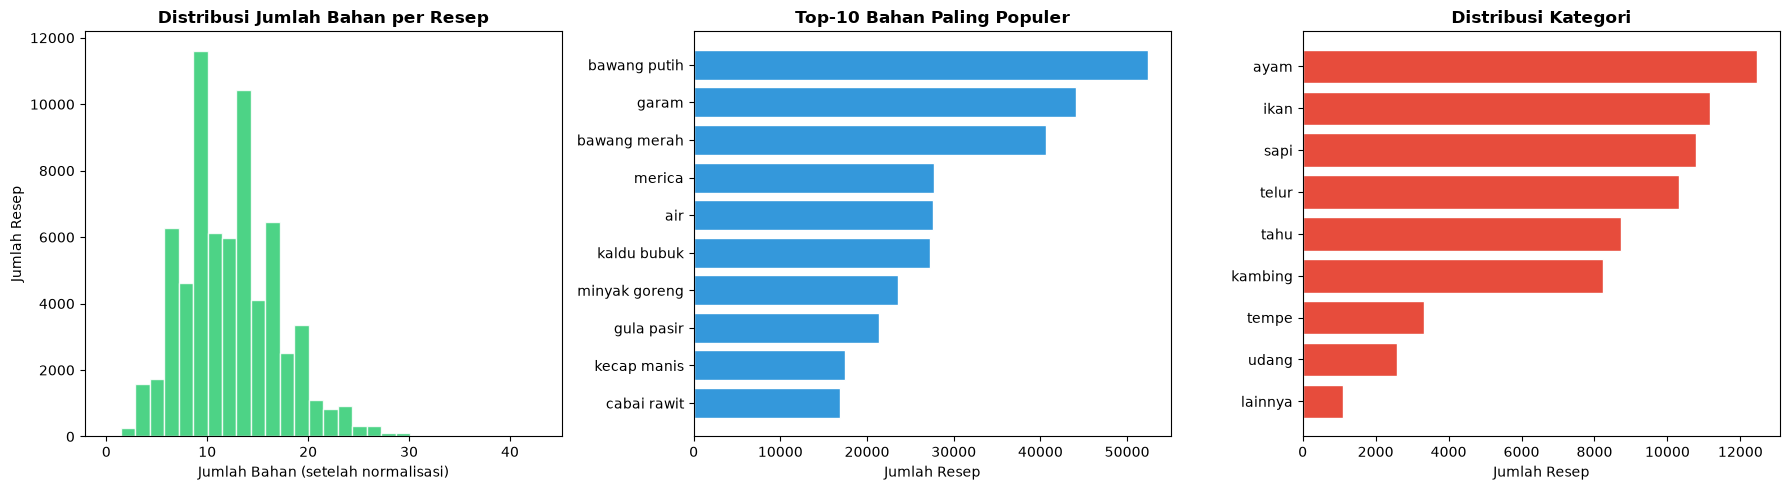

  [EDA] Grafik akan disimpan bersama evaluasi pada Cell 12.
[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 6: Corpus Preprocessing Execution & EXPLORATORY DATA ANALYSIS (EDA)
# ═══════════════════════════════════════════════════════════════════════════════

print("[PREPROCESS] Menjalankan NLP pipeline pada seluruh korpus ...")

all_sets = []
core_sets = []
ir_token_sets = []
ir_texts = []

raw_lists = df_all["ingredients_raw_list"].tolist()
for ingr_raw in tqdm(raw_lists, total=len(raw_lists), desc="Parsing bahan"):
    result = PARSER.extract_ingredients_from_recipe(ingr_raw)
    all_sets.append(result["ingredients_all_set"])
    core_sets.append(result["ingredients_core_set"])
    ir_token_sets.append(result["ingredients_ir_tokens"])
    ir_texts.append(result["ingredients_ir_text"])

df_all["ingredients_all_set"] = all_sets
df_all["ingredients_core_set"] = core_sets
df_all["ingredients_ir_tokens"] = ir_token_sets
df_all["ingredients_ir_text"] = ir_texts
PARSER.set_known_ingredients({ingredient for ingredients in all_sets for ingredient in ingredients})

# Also create title IR text
df_all["title_ir_text"] = df_all["title_clean"].apply(
    lambda t: re.sub(r'[^a-z\s]', '', t.lower()).strip() if isinstance(t, str) else ""
)

df_all.attrs["normalization_version"] = PARSER.NORMALIZATION_VERSION

print(f"\n  [STATS] Preprocessing selesai untuk {len(df_all)} resep.")

# ── Quick EDA ────────────────────────────────────────────────────────────────
print("\n" + "─" * 60)
print("  [EDA] EXPLORATORY DATA ANALYSIS (EDA)")
print("─" * 60)

# Distribution of ingredient counts
ingr_counts = df_all["ingredients_all_set"].apply(len)
print(f"\n  Jumlah bahan per resep:")
print(f"    Mean   : {ingr_counts.mean():.1f}")
print(f"    Median : {ingr_counts.median():.1f}")
print(f"    Min    : {ingr_counts.min()}")
print(f"    Max    : {ingr_counts.max()}")

# Top-20 most popular ingredients
all_ingr_counter = Counter()
for s in df_all["ingredients_all_set"]:
    all_ingr_counter.update(s)

print(f"\n  Top-20 Bahan Paling Populer:")
for i, (ingr, cnt) in enumerate(all_ingr_counter.most_common(20), 1):
    print(f"    {i:>2}. {ingr:<25s} : {cnt:>5} resep")

# Category distribution
print(f"\n  Distribusi Kategori:")
for cat, cnt in df_all["main_category"].value_counts().items():
    print(f"    {cat:<12s}: {cnt:>5}")

# Source distribution
print(f"\n  Distribusi Sumber:")
for src, cnt in df_all["source"].value_counts().items():
    print(f"    {src:<20s}: {cnt:>5}")

# Example: raw vs IR representation
print(f"\n  Contoh Representasi Raw vs IR:")
sample = df_all.iloc[0]
print(f"    Judul    : {sample['title_clean']}")
print(f"    Raw[0:3] : {sample['ingredients_raw_list'][:3]}")
print(f"    IR text  : {sample['ingredients_ir_text'][:120]}...")

# ── Visualisasi EDA ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi jumlah bahan
axes[0].hist(ingr_counts, bins=30, color="#2ecc71", edgecolor="white", alpha=0.85)
axes[0].set_title("Distribusi Jumlah Bahan per Resep", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jumlah Bahan (setelah normalisasi)")
axes[0].set_ylabel("Jumlah Resep")

# 2. Top-10 bahan
top10 = all_ingr_counter.most_common(10)
axes[1].barh([x[0] for x in top10][::-1], [x[1] for x in top10][::-1], color="#3498db", edgecolor="white")
axes[1].set_title("Top-10 Bahan Paling Populer", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Resep")

# 3. Kategori
cat_counts = df_all["main_category"].value_counts()
axes[2].barh(cat_counts.index[::-1], cat_counts.values[::-1], color="#e74c3c", edgecolor="white")
axes[2].set_title("Distribusi Kategori", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Jumlah Resep")

plt.tight_layout()
fig_eda = fig
plt.show()
print("  [EDA] Grafik akan disimpan bersama evaluasi pada Cell 12.")
print("[OK] Cell 6 selesai: preprocessing korpus dan analisis EDA selesai.")

## Dasar teori dan implementasi model

Notasi: $Q$ dan $D$ adalah himpunan bahan inti query dan dokumen setelah parser; $I=|Q\cap D|$. Untuk model teks, $t$ adalah token bahan komposit, $N$ jumlah dokumen, dan $df_t$ jumlah dokumen yang memuat $t$.

**Set-Overlap/Jaccard**

$
J(Q,D)=\frac{|Q\cap D|}{|Q\cup D|}.
$

Implementasi memakai kehadiran biner bahan inti, bukan frekuensi kata mentah. Union nol menghasilkan skor nol.

**TF-IDF dan cosine**

$
idf_t=\log\frac{1+N}{1+df_t}+1,\quad
w_{t,d}=tf_{t,d}\,idf_t,\quad
\cos(q,d)=\frac{q\cdot d}{\|q\|\|d\|}.
$

Ini mengikuti smoothing IDF dan normalisasi L2 default `TfidfVectorizer`. Kanal bahan memakai seluruh bahan kanonik; kanal judul memakai token kata judul. Skor gabungan adalah $0.70\,\cos_{\text{bahan}}+0.30\,\cos_{\text{judul}}$, hanya jika cosine bahan positif. Judul saja tidak membuat dokumen lolos.

**BM25**

$
IDF(t)=\log\left(1+\frac{N-df_t+0.5}{df_t+0.5}\right),
\qquad
BM25(q,d)=\sum_{t\in q}IDF(t)\,
\frac{tf_{t,d}(k_1+1)}
{tf_{t,d}+k_1(1-b+b\,|d|/\overline{|d|})}.
$

Parameter awal $k_1=1.2$, $b=0.4$. Panjang dokumen adalah jumlah token bahan komposit. Karena daftar bahan direpresentasikan sebagai set, token bahan dalam satu dokumen umumnya muncul satu kali. Ini penerapan BM25 pada kehadiran bahan, bukan pada frekuensi kata dalam seluruh teks resep. Implementasi menambahkan epsilon kecil pada penyebut rata-rata panjang.

**SisaRasa Hybrid**

Model menggabungkan BM25 dan TF-IDF yang dinormalisasi min-max per query dengan sinyal bahan:

$
C=\frac{I}{\max(|D|,\,2\ \text{jika }|Q|\ge2\text{, selain itu }1)+\epsilon},
\quad U=\frac{I}{|Q|+\epsilon},
\quad M=\frac{\max(0,|D|-I-2)}{|D|+3}.
$

Protein alignment $A$ bernilai 1 jika protein query dan dokumen beririsan; -0.5 jika query memiliki protein dan dokumen memiliki protein lain tanpa irisan; selain itu 0.

Hybrid dan pseudo-qrels memakai `MAIN_PROTEIN_INGREDIENTS` yang sama. `Telur`, `putih telur`, dan `kuning telur` diakui sebagai protein, tetapi hanya nama kanonik yang sama dianggap beririsan. Klasifikasi protein tidak mengizinkan substitusi antarbagian telur.

$
s=0.10\,\widehat{BM25}+0.05\,\widehat{TFIDF}
+0.20\,C+0.20\,U+0.35\,J-0.10\,M+0.25\,A.
$

Skor dikalikan 0.25 jika irisan kurang dari dua untuk query dengan minimal dua bahan inti, atau kurang dari satu untuk query satu bahan. Dokumen tanpa irisan diberi nol; hasil yang dikembalikan harus memiliki skor positif. Skor Hybrid tidak dibatasi 0 sampai 1 dan bukan probabilitas.

Bobot tersebut adalah konfigurasi heuristik yang sedang diuji, bukan nilai optimum yang telah dibuktikan. Ablation menolkan `w_prot` atau `w5` saja; bobot lain tidak dinormalisasi ulang.

| Model | Informasi yang digunakan |
|---|---|
| Set-Overlap | Bahan inti |
| TF-IDF Cosine | Seluruh bahan kanonik dan judul |
| BM25 | Seluruh bahan kanonik |
| Hybrid | Skor dua model teks, bahan inti, dan kelompok protein |

Dengan perbedaan field tersebut, hasil membandingkan empat konfigurasi sistem. Perbandingan ini tidak mengisolasi pengaruh algoritma saja. Implementasi detail berada di Cell 7; referensi teori tercantum di akhir notebook.


In [6]:
# ==============================================================================
# CELL 7: Pemodelan Information Retrieval (Set-Overlap, TF-IDF, BM25, SisaRasa Hybrid)
# ==============================================================================

from abc import ABC, abstractmethod
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import numpy as np


def _identity_token_func(x):
    """Fungsi identitas tingkat modul agar CountVectorizer dapat diserialisasi via pickle."""
    return x


class BaseRetriever(ABC):
    name: str = "Base"

    @abstractmethod
    def index(self, corpus_df: pd.DataFrame):
        pass

    @abstractmethod
    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        """Return list of (doc_id, score) sorted by score desc."""
        pass


# -- Model 1: Set-Overlap / Jaccard Baseline -----------------------------------

class SetOverlapRetriever(BaseRetriever):
    name = "Set-Overlap"

    def __init__(self, parser: IndonesianIngredientParser):
        self.parser = parser
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_lengths = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_lengths = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        q_vec = self.vectorizer.transform([list(q_core)])
        intersections = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()
        q_len = len(q_core)
        unions = self.doc_lengths + q_len - intersections

        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersections / unions, 0.0)

        top_indices = np.argsort(jaccard)[::-1][:top_k]
        return [(self.doc_ids[i], float(jaccard[i])) for i in top_indices if jaccard[i] > 0]


# -- Model 2: TF-IDF + Cosine Similarity Baseline -----------------------------

class TfidfCosineRetriever(BaseRetriever):
    name = "TF-IDF Cosine"

    def __init__(self, parser: IndonesianIngredientParser, w_ingr: float = 0.70, w_title: float = 0.30):
        self.parser = parser
        self.w_ingr = w_ingr
        self.w_title = w_title
        self.doc_ids: List[str] = []
        self.vectorizer_ingr = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.vectorizer_title = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", lowercase=False)
        self.tfidf_ingr = None
        self.tfidf_title = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        ingr_texts = corpus_df["ingredients_ir_text"].fillna("").tolist()
        title_texts = corpus_df["title_ir_text"].fillna("").tolist()
        self.tfidf_ingr = self.vectorizer_ingr.fit_transform(ingr_texts)
        self.tfidf_title = self.vectorizer_title.fit_transform(title_texts)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        scores = self.get_scores_array(query_str)
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip():
            return np.zeros(len(self.doc_ids))
        q_vec_ingr = self.vectorizer_ingr.transform([q_ir_text])
        sim_ingr = cosine_similarity(q_vec_ingr, self.tfidf_ingr).flatten()
        q_vec_title = self.vectorizer_title.transform([q_ir_text.replace("_", " ")])
        sim_title = cosine_similarity(q_vec_title, self.tfidf_title).flatten()
        return np.where(sim_ingr > 0, self.w_ingr * sim_ingr + self.w_title * sim_title, 0.0)


# -- Model 3: Okapi BM25 (Vectorized Sparse Matrix) ---------------------------

class BM25Retriever(BaseRetriever):
    name = "BM25"

    def __init__(self, parser: IndonesianIngredientParser, k1: float = 1.2, b: float = 0.4):
        self.parser = parser
        self.k1 = k1
        self.b = b
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.bm25_matrix: Optional[csr_matrix] = None

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        texts = corpus_df["ingredients_ir_text"].fillna("").tolist()

        self.vectorizer = CountVectorizer(
            token_pattern=r"(?u)\b\w+\b",
            lowercase=False
        )
        tf_matrix = self.vectorizer.fit_transform(texts)
        N, V = tf_matrix.shape

        doc_len = np.array(tf_matrix.sum(axis=1)).flatten()
        avgdl = float(doc_len.mean()) if N > 0 else 1.0

        # Document frequency df
        df = np.bincount(tf_matrix.indices, minlength=V)

        # Okapi BM25 IDF dengan smoothing +1.0
        idf = np.log((N - df + 0.5) / (df + 0.5) + 1.0)

        # Precompute bobot BM25 sparse matrix
        row_indices = np.repeat(np.arange(N), np.diff(tf_matrix.indptr))
        tf_vals = tf_matrix.data
        len_norm = 1.0 - self.b + self.b * (doc_len / (avgdl + 1e-9))
        denom = tf_vals + self.k1 * len_norm[row_indices]
        bm25_data = (tf_vals * (self.k1 + 1.0) / denom) * idf[tf_matrix.indices]

        self.bm25_matrix = csr_matrix((bm25_data, tf_matrix.indices, tf_matrix.indptr), shape=tf_matrix.shape)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        scores = self.get_scores_array(query_str)
        if scores.size == 0 or np.all(scores == 0):
            return []
        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]

    def get_scores_array(self, query_str: str) -> np.ndarray:
        """Return full score array untuk model hybrid via perkalian matriks sparse."""
        q_parsed = self.parser.parse_query(query_str)
        q_ir_text = q_parsed["ingredients_ir_text"]
        if not q_ir_text.strip() or self.bm25_matrix is None:
            return np.zeros(len(self.doc_ids))

        q_vec = self.vectorizer.transform([q_ir_text])
        if q_vec.nnz == 0:
            return np.zeros(len(self.doc_ids))

        scores = np.array(self.bm25_matrix.dot(q_vec.T).toarray()).ravel()
        return scores


# -- Model 4: SisaRasa Hybrid Culinary Ranking (Proposed Method) ---------------

# Exact canonical ingredients; egg parts remain separate retrieval entities.
MAIN_PROTEIN_INGREDIENTS = frozenset({
    "ayam", "daging sapi", "daging kambing", "ikan", "udang", "cumi",
    "telur", "putih telur", "kuning telur", "tahu", "tempe",
})


class SisaRasaHybridRetriever(BaseRetriever):
    name = "SisaRasa Hybrid"

    MAIN_PROTEINS = MAIN_PROTEIN_INGREDIENTS

    def __init__(self, parser: IndonesianIngredientParser,
                 bm25_retriever: BM25Retriever,
                 tfidf_retriever: TfidfCosineRetriever,
                 w1: float = 0.10, w2: float = 0.05, w3: float = 0.20,
                 w4: float = 0.20, w_jaccard: float = 0.35,
                 w5: float = 0.10, w_prot: float = 0.25):
        self.parser = parser
        self.bm25_retriever = bm25_retriever
        self.tfidf_retriever = tfidf_retriever
        self.w1 = w1
        self.w2 = w2
        self.w3 = w3
        self.w4 = w4
        self.w_jaccard = w_jaccard
        self.w5 = w5
        self.w_prot = w_prot
        self.doc_ids: List[str] = []
        self.vectorizer: Optional[CountVectorizer] = None
        self.doc_ingr_matrix = None
        self.doc_core_len = None
        self.protein_vectorizer: Optional[CountVectorizer] = None
        self.doc_protein_matrix = None
        self.doc_has_protein = None
        self.epsilon = 1e-9

    def index(self, corpus_df: pd.DataFrame):
        self.doc_ids = corpus_df["doc_id"].tolist()
        core_lists = [list(s) for s in corpus_df["ingredients_core_set"]]

        # 1. Matriks biner sparse seluruh bahan inti
        self.vectorizer = CountVectorizer(
            binary=True,
            tokenizer=_identity_token_func,
            preprocessor=_identity_token_func,
            lowercase=False,
            token_pattern=None
        )
        self.doc_ingr_matrix = self.vectorizer.fit_transform(core_lists)
        self.doc_core_len = np.array(self.doc_ingr_matrix.sum(axis=1)).flatten()

        # 2. Matriks biner sparse khusus Protein Utama
        doc_proteins = [[p for p in s if p in self.MAIN_PROTEINS] for s in corpus_df["ingredients_core_set"]]
        self.doc_has_protein = np.array([bool(proteins) for proteins in doc_proteins])
        self.protein_vectorizer = None
        self.doc_protein_matrix = None
        if self.doc_has_protein.any():
            self.protein_vectorizer = CountVectorizer(
                binary=True,
                tokenizer=_identity_token_func,
                preprocessor=_identity_token_func,
                lowercase=False,
                token_pattern=None
            )
            self.doc_protein_matrix = self.protein_vectorizer.fit_transform(doc_proteins)

    def _min_max_normalize(self, arr: np.ndarray) -> np.ndarray:
        mn, mx = arr.min(), arr.max()
        if mx - mn < 1e-12:
            return np.zeros_like(arr)
        return (arr - mn) / (mx - mn)

    def retrieve(self, query_str: str, top_k: int = 10) -> List[Tuple[str, float]]:
        q_parsed = self.parser.parse_query(query_str)
        q_core = q_parsed["ingredients_core_set"]
        if not q_core:
            return []

        n = len(self.doc_ids)

        # 1. Skor probabilistik leksikal BM25 (ternormalisasi)
        bm25_raw = self.bm25_retriever.get_scores_array(query_str)
        bm25_norm = self._min_max_normalize(bm25_raw)

        # 2. Skor kecocokan vektor TF-IDF (ternormalisasi)
        tfidf_raw = self.tfidf_retriever.get_scores_array(query_str)
        tfidf_norm = self._min_max_normalize(tfidf_raw)

        # 3. Vektorisasi Set Operations via Perkalian Matriks Sparse
        q_vec = self.vectorizer.transform([list(q_core)])
        intersection = np.array(self.doc_ingr_matrix.dot(q_vec.T).toarray()).flatten()

        q_core_len = len(q_core)
        # Smoothing pada penyebut core_coverage untuk meredam resep terlalu pendek (doc_core_len < 2)
        denom_len = np.maximum(self.doc_core_len, 2.0 if q_core_len >= 2 else 1.0)
        core_coverage = intersection / (denom_len + self.epsilon)
        query_util = intersection / (q_core_len + self.epsilon)

        unions = self.doc_core_len + q_core_len - intersection
        with np.errstate(divide='ignore', invalid='ignore'):
            jaccard = np.where(unions > 0, intersection / unions, 0.0)

        missing = np.maximum(0, self.doc_core_len - intersection - 2)
        missing_penalty = missing / (self.doc_core_len + 3)

        # 4. Main Protein Alignment
        q_proteins = q_core & self.MAIN_PROTEINS
        protein_alignment = np.zeros(n)
        if q_proteins and self.protein_vectorizer is not None:
            q_prot_vec = self.protein_vectorizer.transform([list(q_proteins)])
            protein_inter = np.array(self.doc_protein_matrix.dot(q_prot_vec.T).toarray()).flatten()
            protein_alignment[protein_inter > 0] = 1.0
            protein_alignment[(protein_inter == 0) & self.doc_has_protein] = -0.5

        # 5. Masking Penalti jika bahan cocok < 2 saat query memiliki >= 2 bahan inti
        min_match_mask = (intersection >= 2) if q_core_len >= 2 else (intersection >= 1)

        # 6. Formula Skor Hybrid Terkalibrasi
        scores = (self.w1 * bm25_norm
                  + self.w2 * tfidf_norm
                  + self.w3 * core_coverage
                  + self.w4 * query_util
                  + self.w_jaccard * jaccard
                  - self.w5 * missing_penalty
                  + self.w_prot * protein_alignment)
        scores = np.where(min_match_mask, scores, scores * 0.25)
        scores = np.where(intersection > 0, scores, 0.0)

        top_indices = np.argsort(scores)[::-1][:top_k]
        return [(self.doc_ids[i], float(scores[i])) for i in top_indices if scores[i] > 0]


def _check_v4_retrievers():
    parser = IndonesianIngredientParser()
    records = [
        ("fried", "bawang goreng ayam", ["bawang goreng", "ayam"]),
        ("shallot", "bawang merah tahu", ["bawang merah", "tahu"]),
        ("garlic", "bawang putih tempe", ["bawang putih", "tempe"]),
        ("garlic_typo", "bawang putih tempe", ["bawang purih", "tempe"]),
        ("title_only", "ayam tahu tempe", ["tahu", "tempe"]),
        ("egg", "telur", ["telur"]),
    ]
    corpus = pd.DataFrame([
        {"doc_id": doc_id, "title_ir_text": title, **parser.extract_ingredients_from_recipe(ingredients)}
        for doc_id, title, ingredients in records
    ])
    parser.set_known_ingredients({"bwang greng", "bawang purih"})
    set_model = SetOverlapRetriever(parser)
    tfidf = TfidfCosineRetriever(parser)
    bm25 = BM25Retriever(parser)
    hybrid = SisaRasaHybridRetriever(parser, bm25, tfidf)
    for model in (set_model, tfidf, bm25, hybrid):
        model.index(corpus)
        typo_ids = {doc_id for doc_id, _ in model.retrieve("bwang greng", top_k=10)}
        assert "fried" in typo_ids and not typo_ids.intersection({"shallot", "garlic", "garlic_typo"})
        clean_ids = [doc_id for doc_id, _ in model.retrieve("bawang putih", top_k=10)]
        typo_ids = [doc_id for doc_id, _ in model.retrieve("bawang purih", top_k=10)]
        assert clean_ids == typo_ids and {"garlic", "garlic_typo"} <= set(clean_ids)
        assert "title_only" not in {doc_id for doc_id, _ in model.retrieve("ayam", top_k=10)}
    no_protein = corpus.iloc[:2].copy()
    no_protein["ingredients_core_set"] = [{"bawang goreng"}, {"bawang merah"}]
    hybrid.index(no_protein)
    assert hybrid.protein_vectorizer is None


_check_v4_retrievers()
print("[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.")


[OK] Cell 7 selesai: 4 model temu kembali informasi berhasil diimplementasikan.


In [7]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 8: Indexing Korpus & Pengukuran Resource (Waktu & Penggunaan Memori)
# ═══════════════════════════════════════════════════════════════════════════════

import sys

def measure_size_mb(obj) -> float:
    """Rough memory estimate in MB."""
    try:
        return sys.getsizeof(pickle.dumps(obj)) / (1024 * 1024)
    except Exception:
        return 0.0


print("[INDEX] Membangun indeks 4 model retrieval ...\n")

# Instantiate models
model_setoverlap = SetOverlapRetriever(PARSER)
model_tfidf = TfidfCosineRetriever(PARSER)
model_bm25 = BM25Retriever(PARSER, k1=1.2, b=0.4)
model_hybrid = SisaRasaHybridRetriever(PARSER, model_bm25, model_tfidf)

models = {
    "Set-Overlap": model_setoverlap,
    "TF-IDF Cosine": model_tfidf,
    "BM25": model_bm25,
    "SisaRasa Hybrid": model_hybrid,
}

index_stats = []
for name, model in models.items():
    t0 = time.perf_counter()
    model.index(df_all)
    t1 = time.perf_counter()
    mem = measure_size_mb(model)
    index_stats.append({"Model": name, "Index Time (s)": round(t1 - t0, 3), "Size (MB)": round(mem, 2)})
    print(f"  [OK] {name:<20s}: {t1-t0:.3f}s, ~{mem:.1f} MB")

df_index_stats = pd.DataFrame(index_stats)
print(f"\n{df_index_stats.to_string(index=False)}")

# Quick sanity check
test_query = "ayam, bawang merah, bawang putih, kecap manis"
print(f"\n  [QUERY] SANITY CHECK QUERY: '{test_query}'")
for name, model in models.items():
    results = model.retrieve(test_query, top_k=3)
    if results:
        top_title = df_all.loc[df_all["doc_id"] == results[0][0], "title_clean"].iloc[0]
        print(f"    {name:<20s} → #{1}: {top_title} (skor: {results[0][1]:.4f})")
    else:
        print(f"    {name:<20s} → (no results)")

print("[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.")

[INDEX] Membangun indeks 4 model retrieval ...



  [OK] Set-Overlap         : 0.482s, ~10.9 MB


  [OK] TF-IDF Cosine       : 0.906s, ~17.1 MB


  [OK] BM25                : 0.678s, ~13.3 MB


  [OK] SisaRasa Hybrid     : 0.650s, ~40.0 MB

          Model  Index Time (s)  Size (MB)
    Set-Overlap           0.482      10.92
  TF-IDF Cosine           0.906      17.14
           BM25           0.678      13.31
SisaRasa Hybrid           0.650      39.97

  [QUERY] SANITY CHECK QUERY: 'ayam, bawang merah, bawang putih, kecap manis'
    Set-Overlap          → #1: Suwir Ayam Kampung Kecap (skor: 1.0000)
    TF-IDF Cosine        → #1: Ayam Kecap (skor: 0.6590)
    BM25                 → #1: Semur Ayam Bumbu Merah (skor: 4.6782)
    SisaRasa Hybrid      → #1: Suwir Ayam Kampung Kecap (skor: 1.1496)
[OK] Cell 8 selesai: seluruh indeks model temu kembali berhasil dibangun.


## Protokol evaluasi dan ancaman validitas

**Proxy recommendation.** Reference query yang bersih menghasilkan pseudo-qrels terhadap seluruh korpus. Retriever menerima query asli, termasuk noise untuk skenario D. Dengan $C_r=I/|D|$ dan $U_r=I/|Q|$, rubric `proxy_v3` memberi grade:

| Grade | Aturan |
|---|---|
| 3 | Protein cocok jika disyaratkan; $C_r\ge0.65$; $U_r\ge0.60$ |
| 2 | Protein cocok jika disyaratkan; $I\ge2$; $C_r\ge0.45$; $U_r\ge0.50$ |
| 1 | $I\ge2$; $C_r\ge0.30$, setelah aturan di atas tidak terpenuhi |
| 0 | Sisanya; pasangan dengan core kosong juga bernilai nol |

Grade nol tidak disimpan dalam sparse qrels, tetapi nol hanya berlaku untuk ID di dalam assessment universe. ID di luar universe ditolak. Ambang relevansi biner adalah grade >= 2.

Perubahan `proxy_v2` ke `proxy_v3` menambahkan putih dan kuning telur pada kosakata protein bersama dengan Hybrid; ambang grade tidak berubah. Dokumen yang tidak mengandung protein yang diminta tidak lagi memperoleh grade 2 atau 3 hanya karena dua bahan sayurnya cocok. Ini koreksi metode eksploratif setelah test diperiksa, bukan peningkatan relevansi yang terukur secara independen.

Rubric dan Hybrid berbagi sinyal. Grade 0 tidak membuktikan resep tidak berguna bagi manusia. Analisis ini mengukur agreement terhadap rubric; tidak ada human ground truth. Ambang rubric belum divalidasi independen atau diuji sensitivitasnya. Qrels tidak diubah antar model maupun varian ablation.

**Query dan split.** Skenario A berisi 2–3 bahan inti, B 4–6, C 7–10, dan D 3–7 dengan takaran/alias terkontrol. Jika rentang tidak terpenuhi, generator mencatatnya. Kosakata terbatas pada nama kanonik dalam kamus parser; bahan valid di luar kamus belum terwakili. Keluarga berdasarkan himpunan bahan reference yang identik ditempatkan pada split yang sama, termasuk lintas dua benchmark. Ini tidak menjamin semua intent yang mirip telah dipisahkan.

48 query lama dipertahankan sebagai retrospektif. Query baru berasal dari sampel korpus dengan seed 42 dan target pembagian 75/25 per strata keluarga. Hasil yang sudah dibaca tidak menjadi untouched holdout hanya karena notebook dijalankan ulang. Untuk penelitian konfirmatori berikutnya, bekukan metode dan parameter sebelum mengumpulkan keluarga query baru.

**Pemulihan resep sumber.** Satu target sumber dideklarasikan untuk tiap query; Hit@k dan MRR@10 mengukur keberhasilannya ditemukan. Resep lain tidak diberi penilaian relevansi umum. Query berupa subset bahan dapat cocok dengan banyak resep. Sel riset menghitung banyaknya dokumen yang memuat semua bahan query untuk menunjukkan ambiguitas ini, tanpa mengubah qrels.

**Metrik.** P@k memakai denominator tetap $k$, termasuk ketika hasil kurang dari $k$. R@k menggunakan seluruh dokumen dengan grade >= 2 dalam assessment universe. AP@10 memakai jumlah precision pada rank relevan dibagi $\min(10,R_q)$; MAP@10 adalah rata-rata AP query. Konvensi ini dinyatakan eksplisit dan tidak disamakan begitu saja dengan semua implementasi AP lain. MRR@10 mengambil kebalikan rank relevan pertama sampai rank 10. nDCG memakai gain $2^{grade}-1$, diskon $\log_2(rank+1)$, dan ideal dari seluruh qrels.

Query dengan denominator relevansi atau IDCG nol diberi skor nol dalam rata-rata semua query. Rata-rata eligible dilaporkan terpisah dengan jumlah query eligible. Grade 1 dapat berkontribusi pada nDCG meskipun tidak relevan secara biner. Jangan memilih rata-rata yang paling menguntungkan suatu model.

**Batas inferensi.** Jumlah query kecil; angka rata-rata dan tabel menang/seri/kalah bersifat deskriptif. Tidak ada uji signifikansi. Latency dari satu panggilan tanpa warm-up bukan benchmark performa yang stabil. Model dipengaruhi parser dan kosakata yang sama, sehingga kegagalan normalisasi bersama dapat memengaruhi ranking sekaligus penilaian otomatis.


In [8]:
# ==============================================================================
# CELL 9: Generator Stratified Benchmark Queries (Skenario A-D) & Automated Qrels
# ==============================================================================

class BenchmarkQueryGenerator:
    """Pembangkit query evaluasi stratified berdasarkan 4 skenario."""

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser, seed: int = 42):
        self.corpus = corpus_df
        self.parser = parser
        self.rng = np.random.RandomState(seed)
        self.benchmark_vocabulary = {term for term in parser.SYNONYM_MAP.values()
                                     if parser.parse_ingredient_line(term) == term
                                     and not parser.is_pantry_staple(term)}

    def _sample_ingredients_from_corpus(self, n_ingredients: int, category: Optional[str] = None) -> str:
        """Sample bahan dari resep nyata di korpus."""
        if category:
            pool = self.corpus[self.corpus["main_category"] == category]
            if pool.empty:
                pool = self.corpus
        else:
            pool = self.corpus

        idx = self.rng.randint(0, len(pool))
        recipe = pool.iloc[idx]
        core = sorted(set(recipe["ingredients_core_set"]) & self.benchmark_vocabulary)
        if len(core) < n_ingredients:
            selected = core
        else:
            self.rng.shuffle(core)
            selected = core[:n_ingredients]
        return ", ".join(selected)

    def generate_scenario_a(self, n: int = 12) -> List[Dict]:
        """Skenario A: Sisa Kulkas Minimalis (2-3 bahan inti)."""
        handcrafted = [
            "telur, tahu, kecap manis",
            "tempe, cabai rawit, bawang putih",
            "ayam, bawang merah, garam",
            "tahu, bayam, bawang putih",
            "telur, wortel, bawang merah",
            "udang, bawang putih, cabai",
            "tempe, kecap manis, cabai rawit",
            "telur, kangkung",
            "tahu, cabai merah, tomat",
            "ikan, kunyit, serai",
            "daging sapi, bawang bombay, merica",
            "ayam, jahe, bawang putih",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"A{i+1:02d}", "scenario": "A", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(2, 4))
            queries.append({"query_id": f"A{len(queries)+1:02d}", "scenario": "A", "query_text": q})
        return queries

    def generate_scenario_b(self, n: int = 12) -> List[Dict]:
        """Skenario B: Masak Harian Standar (4-6 bahan inti)."""
        handcrafted = [
            "ayam, bawang merah, bawang putih, kecap manis, merica, kentang",
            "tempe, cabai merah, bawang merah, bawang putih, tomat, kecap manis",
            "udang, bawang putih, mentimun, cabai rawit, serai, santan",
            "telur, wortel, kubis, bawang putih, kecap manis, saus tiram",
            "tahu, jamur, wortel, bawang putih, saus tiram, daun bawang",
            "daging sapi, bawang bombay, wortel, kentang, tomat, seledri",
            "ikan, kunyit, cabai merah, bawang merah, tomat, serai",
            "ayam, santan, serai, daun jeruk, lengkuas, cabai",
            "tempe, buncis, bawang merah, bawang putih, cabai hijau, terasi",
            "telur, bayam, wortel, bawang putih, bawang merah, jagung",
            "tahu, udang, tauge, kecap manis, bawang putih, saus tiram",
            "daging sapi, kentang, wortel, bawang bombay, tomat, seledri",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"B{i+1:02d}", "scenario": "B", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(4, 7))
            queries.append({"query_id": f"B{len(queries)+1:02d}", "scenario": "B", "query_text": q})
        return queries

    def generate_scenario_c(self, n: int = 12) -> List[Dict]:
        """Skenario C: Kombinasi Bahan Lengkap (7-10 bahan inti)."""
        handcrafted = [
            "ayam, santan, serai, lengkuas, daun jeruk, kunyit, cabai merah, bawang merah, bawang putih, kemiri",
            "daging sapi, santan, serai, lengkuas, kunyit, jahe, cabai merah, bawang merah, bawang putih, kelapa",
            "ikan, kunyit, cabai merah, bawang merah, bawang putih, tomat, serai, daun kunyit, kemiri, asam jawa",
            "ayam, kentang, wortel, bawang bombay, bawang putih, tomat, seledri, daun salam, merica, pala",
            "udang, santan, cabai merah, bawang merah, bawang putih, kunyit, serai, lengkuas, daun jeruk",
            "tempe, tahu, cabai merah, bawang merah, bawang putih, tomat, terasi, kecap manis, daun jeruk, serai",
            "daging kambing, santan, serai, lengkuas, jahe, kunyit, cabai, ketumbar, jintan, kayu manis",
            "ayam, bawang merah, bawang putih, jahe, kunyit, ketumbar, kemiri, santan, serai, daun salam",
            "ikan, bawang merah, bawang putih, cabai merah, cabai rawit, tomat, terasi, serai, lengkuas, kunyit",
            "telur, santan, bawang merah, bawang putih, cabai, kunyit, daun jeruk, serai, lengkuas",
            "daging sapi, bawang merah, bawang putih, cabai, jahe, serai, kecap manis, lengkuas, daun salam, merica",
            "udang, cabai merah, bawang merah, bawang putih, tomat, terasi, lengkuas, serai, daun jeruk, kunyit",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"C{i+1:02d}", "scenario": "C", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(7, 11))
            queries.append({"query_id": f"C{len(queries)+1:02d}", "scenario": "C", "query_text": q})
        return queries

    def generate_scenario_d(self, n: int = 12) -> List[Dict]:
        """Skenario D: Noisy / Colloquial User Input."""
        handcrafted = [
            "2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
            "telor 3 btr, terigu 200gr, mentega, gula pasir, vanili",
            "1/2 kg daging sapi, 2 bh kentang, bw merah, bw putih, kecap bango",
            "tempe 1 papan, lombok rawit, bamer 5 siung, baput 3 siung, santen, gula jawa",
            "udang kupas 250gr, 3 siung baput, cabe ijo, saori, minyak sayur",
            "3 potong tahu putih, telor 2 butir, terigu, bawang pth, cabe rawit",
            "1 ekor ikan nila, kunir, laos, sereh, daun salam, cabe merah besar",
            "dada ayam fillet 500g, bw bombai, saus tomat, kecap, merica bubuk",
            "toge 1 ikat, tahu 2 buah, bamer, baput, kecap, cabe rawit",
            "4 butir telor, sledri, daun prei, royco, minyak, garam secukupnya",
            "kambing 1 kg, santen 500 ml, laos, sereh, jinten, kayu manis, pekak",
            "ikan tongkol 3 ptg, asem jawa, cabe, bamer, tomat, terasi, gula merah",
        ]
        queries = []
        for i, q in enumerate(handcrafted[:n]):
            queries.append({"query_id": f"D{i+1:02d}", "scenario": "D", "query_text": q})
        while len(queries) < n:
            q = self._sample_ingredients_from_corpus(self.rng.randint(3, 8))
            queries.append({"query_id": f"D{len(queries)+1:02d}", "scenario": "D", "query_text": q})
        return queries

    def generate_all(self, n_per_scenario: int = 12) -> List[Dict]:
        all_queries = []
        all_queries.extend(self.generate_scenario_a(n_per_scenario))
        all_queries.extend(self.generate_scenario_b(n_per_scenario))
        all_queries.extend(self.generate_scenario_c(n_per_scenario))
        all_queries.extend(self.generate_scenario_d(n_per_scenario))
        return all_queries


# -- Reproducible pseudo-qrels protocol ----------------------------------------

EVALUATION_PROTOCOL = {
    "seed": 42,
    "proxy_qrel_version": "proxy_v3",
    "protein_ingredients": sorted(MAIN_PROTEIN_INGREDIENTS),
    "protein_matching": "exact canonical overlap; whole egg, egg white and yolk are distinct",
    "binary_relevance_threshold": 2,
    "zero_denominator_policy": "score zero for all-query macro; eligible-only mean is null when no query is eligible",
    "aggregation": "macro means for all queries and eligible queries within each split and scenario; binary eligibility requires grade >= 2, nDCG eligibility requires IDCG > 0",
    "split_ratio": {"dev": 0.75, "test": 0.25},
    "split_unit": "canonical reference ingredient family",
    "split_limit": "exact family grouping only; inspected synthetic queries are not an untouched holdout",
    "query_vocabulary": "non-staple canonical synonym-map terms only; unlisted valid ingredients are excluded",
    "proxy_assessment_universe": "all df_all doc_id values",
    "proxy_qrel_input": "clean reference ingredients; retrieval receives the original query",
    "noisy_scenario": "synthetic quantities and selected culinary aliases, not typo correction",
    "known_item_label": "pemulihan resep sumber berdasarkan bahan",
    "known_item_relevance": "measure recovery of the declared source recipe only; other recipes are not judged irrelevant",
    "known_item_limit": "sampled ingredient subsets may match many recipes and need not identify a unique target",
    "model_feature_limit": "TF-IDF also uses titles; model differences are not algorithm-only",
    "latency_limit": "one retrieval call per query without warm-up; descriptive only",
    "coverage_formula": "shared_core / document_core_count when both core sets are nonempty",
    "query_utility_formula": "shared_core / reference_query_core_count when both core sets are nonempty",
    "metric_definitions": {
        "P@k": "relevant returned in top k / k",
        "R@k": "relevant returned in top k / all relevant in proxy assessment universe",
        "AP@10": "sum of precision at relevant ranks in top 10 / min(10, total relevant)",
        "nDCG@k": "gain 2**grade - 1 with log2(rank + 1) discount; ideal from all qrels",
        "RR@10": "reciprocal rank of first grade >= 2 within top 10, else zero",
    },
    "grade_rules": {
        "3": "protein match when query has protein; core coverage >= 0.65; query utility >= 0.60",
        "2": "protein match when applicable; >= 2 shared core ingredients; core coverage >= 0.45; query utility >= 0.50",
        "1": ">= 2 shared core ingredients and core coverage >= 0.30",
        "0": "all remaining pairs; omitted from sparse qrels inside the declared corpus universe",
    },
    "parser_dependency": "IndonesianIngredientParser.parse_query core ingredient output",
    "hybrid_feature_overlap": ["core coverage", "query utility", "protein alignment"],
    "limitations": (
        "Heuristic ingredient rubric overlaps Hybrid core coverage, query utility, "
        "and protein alignment; proxy scores measure rubric agreement, not human relevance. "
        "Corpus-derived synthetic queries do not establish real-user performance."
    ),
}

def canonical_query_family(query_text: str, parser: IndonesianIngredientParser) -> str:
    """Stable family key from a tuple of sorted parsed core ingredients."""
    core = tuple(sorted(parser.parse_query(query_text)["ingredients_core_set"]))
    return json.dumps(core, ensure_ascii=False, separators=(",", ":"))


def split_query_families(queries: List[Dict], seed: int = 42,
                         forced_dev_families: Set[str] = None) -> Tuple[List[Dict], Dict[str, str]]:
    """Assign whole ingredient families to deterministic scenario-stratified splits."""
    family_scenarios = {}
    for query in queries:
        family_scenarios.setdefault(query["family_id"], set()).add(query["scenario"])

    strata = {}
    for family_id, scenarios in family_scenarios.items():
        strata.setdefault(tuple(sorted(scenarios)), []).append(family_id)

    rng = np.random.RandomState(seed)
    forced_dev_families = set(forced_dev_families or ())
    assignments = {}
    for stratum in sorted(strata):
        all_family_ids = sorted(strata[stratum])
        family_ids = [family_id for family_id in all_family_ids if family_id not in forced_dev_families]
        assignments.update({family_id: "dev" for family_id in all_family_ids if family_id in forced_dev_families})
        shuffled = list(rng.permutation(family_ids))
        test_count = int(round(len(family_ids) * 0.25)) if len(family_ids) > 1 else 0
        if len(family_ids) > 1:
            test_count = max(1, min(len(family_ids) - 1, test_count))
        test_families = set(shuffled[:test_count])
        assignments.update({
            family_id: ("test" if family_id in test_families else "dev")
            for family_id in family_ids
        })
    
    split_queries = [{**query, "split": assignments[query["family_id"]]} for query in queries]
    return split_queries, assignments


def generate_sampled_queries(generator: BenchmarkQueryGenerator, n_per_scenario: int = 12) -> List[Dict]:
    """Sample stable reference ingredients and add controlled noise only to D."""
    bounds = {"A": (2, 4), "B": (4, 7), "C": (7, 11), "D": (3, 8)}
    aliases = {
        "bawang merah": "bamer", "bawang putih": "baput", "cabai": "cabe",
        "telur": "telor", "santan": "santen", "serai": "sereh",
    }
    queries = []
    for scenario, (low, high) in bounds.items():
        for index in range(n_per_scenario):
            requested_count = int(generator.rng.randint(low, high))
            fallback = None
            for _ in range(50):
                reference = generator._sample_ingredients_from_corpus(requested_count)
                ingredients = reference.split(", ") if reference else []
                expected_core = set(ingredients)
                if not expected_core or generator.parser.parse_query(reference)["ingredients_core_set"] != expected_core:
                    continue
                if fallback is None:
                    fallback = (reference, ingredients, expected_core)
                if low <= len(expected_core) < high:
                    break
            else:
                if fallback is None:
                    raise ValueError(f"Cannot sample a stable reference query for scenario {scenario}")
                reference, ingredients, expected_core = fallback
            query_text = reference
            noise_types = []
            if scenario == "D":
                query_text = ", ".join(
                    f"{position} buah {aliases.get(ingredient, ingredient)}"
                    for position, ingredient in enumerate(ingredients, start=1)
                )
                noise_types = ["quantity"]
                if any(ingredient in aliases for ingredient in ingredients):
                    noise_types.append("culinary_alias")
            observed_core = set(generator.parser.parse_query(query_text)["ingredients_core_set"])
            queries.append({
                "query_id": f"{scenario}N{index + 1:02d}",
                "scenario": scenario,
                "query_text": query_text,
                "reference_query_text": reference,
                "expected_core_ingredients": sorted(expected_core),
                "observed_core_ingredients": sorted(observed_core),
                "normalization_exact_match": observed_core == expected_core,
                "requested_ingredient_count": requested_count,
                "scenario_range_valid": low <= len(expected_core) < high,
                "noise_types": noise_types,
                "source": "corpus_sampled_noisy" if noise_types else "corpus_sampled",
            })
    return queries


class QrelGenerator:
    """Sparse pseudo-qrels graded by the explicit proxy_v3 rubric."""

    MAIN_PROTEIN_KEYWORDS = MAIN_PROTEIN_INGREDIENTS
    RUBRIC_VERSION = "proxy_v3"

    def __init__(self, corpus_df: pd.DataFrame, parser: IndonesianIngredientParser):
        self.corpus = corpus_df
        self.parser = parser
        doc_ids = corpus_df["doc_id"].tolist()
        if len(doc_ids) != len(set(doc_ids)):
            raise ValueError("Assessment corpus contains duplicate document IDs")
        self.assessment_doc_ids = sorted(doc_ids)
        self._assessment_doc_id_set = set(doc_ids)
        self._doc_core_sets = [set(values) for values in corpus_df["ingredients_core_set"].tolist()]
        self._doc_proteins = [values & self.MAIN_PROTEIN_KEYWORDS for values in self._doc_core_sets]

    def validate_assessment_ids(self, doc_ids: List[str]) -> None:
        unknown = set(doc_ids) - self._assessment_doc_id_set
        if unknown:
            raise ValueError(f"Retrieved document IDs outside assessment universe: {sorted(unknown)}")

    def grade_query(self, query_text: str) -> Dict[str, int]:
        """Parse once, grade the full corpus, and return sorted nonzero judgments."""
        q_core = self.parser.parse_query(query_text)["ingredients_core_set"]
        q_proteins = q_core & self.MAIN_PROTEIN_KEYWORDS
        grades = {}
        for doc_id, d_core, d_proteins in zip(
            self.corpus["doc_id"].tolist(), self._doc_core_sets, self._doc_proteins
        ):
            intersection = q_core & d_core
            inter_len = len(intersection)
            grade = 0
            if q_core and d_core:
                core_coverage = inter_len / len(d_core)
                query_util = inter_len / len(q_core)
                protein_match = bool(q_proteins & d_proteins) if q_proteins else True
                if protein_match and core_coverage >= 0.65 and query_util >= 0.60:
                    grade = 3
                elif protein_match and core_coverage >= 0.45 and inter_len >= 2 and query_util >= 0.50:
                    grade = 2
                elif inter_len >= 2 and core_coverage >= 0.30:
                    grade = 1
            if grade:
                grades[doc_id] = grade
        return dict(sorted(grades.items()))

    def grade_known_item(self, target_doc_id: str, target_family_ids: Set[str]) -> Dict[str, int]:
        """Mark declared source targets, not general recipe relevance."""
        if target_doc_id not in self._assessment_doc_id_set:
            raise ValueError(f"Unknown known-item target: {target_doc_id}")
        if target_doc_id not in target_family_ids or not target_family_ids <= self._assessment_doc_id_set:
            raise ValueError("Known-item family must contain target and only corpus document IDs")
        return {doc_id: 2 for doc_id in sorted(target_family_ids)}


def _check_proxy_v3():
    class FixtureParser:
        def parse_query(self, query_text):
            return {"ingredients_core_set": set(query_text.split(",")) if query_text else set()}

    corpus = pd.DataFrame([
        {"doc_id": "boundary", "ingredients_core_set": {"a", "b", "x"}},
        {"doc_id": "empty", "ingredients_core_set": set()},
    ])
    generator = QrelGenerator(corpus, FixtureParser())
    actual = generator.grade_query("a,b,c,d")
    assert actual == {"boundary": 2}, f"Boundary grade: {actual}"
    assert generator.grade_query("") == {}
    assert generator.RUBRIC_VERSION == "proxy_v3"


def _check_benchmark_vocabulary():
    parser = IndonesianIngredientParser()
    corpus = pd.DataFrame([{"ingredients_core_set": {"ayam", "bawang putih", "tomat", "menumis", "dipanggang di teflon"}}])
    generator = BenchmarkQueryGenerator(corpus, parser, seed=42)
    sampled = set(generator._sample_ingredients_from_corpus(5).split(", "))
    assert sampled == {"ayam", "bawang putih", "tomat"}, sampled


def _check_v4_document_retrieval():
    parser = IndonesianIngredientParser()
    recipes = [
        ("dirty", ["3 siiung bawang putih", "1 btg serai digeprek", "2 lb daun salam"]),
        ("canonical", ["bawang putih", "serai", "daun salam"]),
        ("other", ["bawang merah", "jahe"]),
        ("protein", ["ayam", "tahu"]),
    ]
    corpus = pd.DataFrame([
        {"doc_id": key, "title_ir_text": "resep", **parser.extract_ingredients_from_recipe(raw)}
        for key, raw in recipes
    ])
    overlap = SetOverlapRetriever(parser)
    tfidf = TfidfCosineRetriever(parser)
    bm25 = BM25Retriever(parser)
    hybrid = SisaRasaHybridRetriever(parser, bm25, tfidf)
    for model in (overlap, tfidf, bm25, hybrid):
        model.index(corpus)
        assert {key for key, _ in model.retrieve("bawang putih, serai, daun salam")} == {"dirty", "canonical"}
    assert QrelGenerator(corpus, parser).grade_query("bawang putih, serai, daun salam") == {
        "canonical": 3, "dirty": 3,
    }


def _check_v4_identity_retrieval():
    parser = IndonesianIngredientParser()
    recipes = [
        ("white", ["1 buah putih telur"]),
        ("yolk", ["kuning telur"]),
        ("whole", ["telur"]),
        ("butter", ["mentega"]),
        ("margarine", ["margarin"]),
        ("coconut_sugar", ["1/2 sdm gula kelapa diserut"]),
        ("white_sugar", ["gula pasir"]),
        ("acid", ["air asam jawa"]),
        ("water", ["air"]),
        ("sauce", ["1 pouch (77gr) kecap manis Indofood (tambah atau kurangi)"]),
        ("other", ["ayam", "tahu"]),
    ]
    corpus = pd.DataFrame([
        {"doc_id": key, "title_ir_text": "resep", **parser.extract_ingredients_from_recipe(raw)}
        for key, raw in recipes
    ])
    overlap = SetOverlapRetriever(parser)
    tfidf = TfidfCosineRetriever(parser)
    bm25 = BM25Retriever(parser)
    hybrid = SisaRasaHybridRetriever(parser, bm25, tfidf)
    retrievers = [overlap, tfidf, bm25, hybrid]
    for model in retrievers:
        model.index(corpus)
    cases = [
        ("putih telur", "white"), ("kuning telur", "yolk"), ("telur", "whole"),
        ("mentega", "butter"), ("margarin", "margarine"),
        ("gula kelapa", "coconut_sugar"), ("gula pasir", "white_sugar"),
        ("air asam jawa", "acid"), ("air", "water"), ("kecap manis", "sauce"),
    ]
    judge = QrelGenerator(corpus, parser)
    for query, expected_id in cases:
        for model in retrievers:
            actual = {key for key, _ in model.retrieve(query)}
            assert actual == {expected_id}, (type(model).__name__, query, actual)
        assert judge.grade_query(query) == {expected_id: 3}, query


_check_v4_identity_retrieval()
_check_v4_document_retrieval()
_check_proxy_v3()
_check_benchmark_vocabulary()


# -- Preserve historical queries as retrospective data -------------------------
print("[EVAL] Menjaga 48 kueri lama sebagai data retrospektif ...")
legacy_query_gen = BenchmarkQueryGenerator(df_all, PARSER, seed=EVALUATION_PROTOCOL["seed"])
legacy_proxy_queries = legacy_query_gen.generate_all(n_per_scenario=12)
for query in legacy_proxy_queries:
    query["family_id"] = canonical_query_family(query["query_text"], PARSER)
    query["split"] = "retrospective_dev"
    query["evaluation_status"] = "legacy_descriptive"

# -- Generate fresh proxy and known-item query families ------------------------
print("[EVAL] Membangkitkan query evaluasi baru ...")
fresh_query_gen = BenchmarkQueryGenerator(df_all, PARSER, seed=EVALUATION_PROTOCOL["seed"])
proxy_queries = generate_sampled_queries(fresh_query_gen, n_per_scenario=12)
for query in proxy_queries:
    query["family_id"] = canonical_query_family(query["reference_query_text"], PARSER)
known_item_candidates = sorted(
    (tuple(sorted(row.ingredients_core_set & fresh_query_gen.benchmark_vocabulary)), row.doc_id)
    for row in df_all[["doc_id", "ingredients_core_set"]].itertuples(index=False)
    if len(row.ingredients_core_set & fresh_query_gen.benchmark_vocabulary) >= 2
)
known_item_rng = np.random.RandomState(EVALUATION_PROTOCOL["seed"])
known_item_queries = []
for candidate_index in known_item_rng.permutation(len(known_item_candidates)):
    core, target_doc_id = known_item_candidates[candidate_index]
    stable_core = [ingredient for ingredient in core
                   if PARSER.parse_query(ingredient)["ingredients_core_set"] == {ingredient}]
    if len(stable_core) < 2:
        continue
    subset = sorted(known_item_rng.choice(stable_core, size=min(3, len(stable_core)), replace=False).tolist())
    query_text = ", ".join(subset)
    if PARSER.parse_query(query_text)["ingredients_core_set"] != set(subset):
        continue
    family_id = canonical_query_family(query_text, PARSER)
    known_item_queries.append({
        "query_id": f"KI{len(known_item_queries) + 1:03d}",
        "family_id": family_id,
        "target_family_key": f"{target_doc_id}:{family_id}",
        "scenario": "known_item",
        "query_text": query_text,
        "reference_query_text": query_text,
        "expected_core_ingredients": subset,
        "observed_core_ingredients": subset,
        "normalization_exact_match": True,
        "target_doc_id": target_doc_id,
        "target_family_ids": [target_doc_id],
        "source": "corpus_target",
    })
    if len(known_item_queries) == 48:
        break
combined_queries, combined_family_splits = split_query_families(
    proxy_queries + known_item_queries,
    seed=EVALUATION_PROTOCOL["seed"],
    forced_dev_families={query["family_id"] for query in legacy_proxy_queries},
)
proxy_queries = combined_queries[:len(proxy_queries)]
known_item_queries = combined_queries[len(proxy_queries):]
proxy_splits = [
    {"query_id": query["query_id"], "family_id": query["family_id"],
     "split": query["split"], "scenario": query["scenario"], "target_doc_id": None}
    for query in proxy_queries
]
known_item_splits = [
    {"query_id": query["query_id"], "family_id": query["family_id"],
     "split": query["split"], "scenario": query["scenario"],
     "target_doc_id": query["target_doc_id"]}
    for query in known_item_queries
]

assert len(legacy_proxy_queries) == 48
assert all(query["split"] == "retrospective_dev" for query in legacy_proxy_queries)
assert {q["family_id"] for q in proxy_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in proxy_queries if q["split"] == "test"
)
assert {q["family_id"] for q in known_item_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in known_item_queries if q["split"] == "test"
)
assert {q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "dev"}.isdisjoint(
    q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "test"
)
assert {q["family_id"] for q in legacy_proxy_queries}.isdisjoint(
    q["family_id"] for q in proxy_queries + known_item_queries if q["split"] == "test"
)
assert {query["scenario"] for query in proxy_queries} == {"A", "B", "C", "D"}
assert all(set(query["expected_core_ingredients"]) <= fresh_query_gen.benchmark_vocabulary
           for query in proxy_queries + known_item_queries)
assert all(query["query_text"] != query["reference_query_text"] and query["noise_types"]
           for query in proxy_queries if query["scenario"] == "D")
assert all(query["target_family_ids"] == [query["target_doc_id"]] for query in known_item_queries)
print(f"  Legacy retrospective queries: {len(legacy_proxy_queries)}")
print(f"  Fresh proxy queries: {len(proxy_queries)}")
print(f"  Query pemulihan resep sumber berdasarkan bahan: {len(known_item_queries)}")
noisy_queries = [query for query in proxy_queries if query["scenario"] == "D"]
print(f"  D normalization exact matches: {sum(query['normalization_exact_match'] for query in noisy_queries)}/{len(noisy_queries)} (synthetic quantity/alias only)")
invalid_ranges = [query["query_id"] for query in proxy_queries if not query["scenario_range_valid"]]
if invalid_ranges:
    print(f"  [WARN] Scenario ingredient-count range not met: {invalid_ranges}")

# -- Build distinct full-corpus proxy qrels and known-item target qrels --------
qrel_gen = QrelGenerator(df_all, PARSER)
assert qrel_gen.RUBRIC_VERSION == EVALUATION_PROTOCOL["proxy_qrel_version"]
proxy_assessment_doc_ids = qrel_gen.assessment_doc_ids
proxy_qrels = {
    query["query_id"]: qrel_gen.grade_query(query["reference_query_text"])
    for query in proxy_queries
}
known_item_qrels = {
    query["query_id"]: qrel_gen.grade_known_item(
        query["target_doc_id"], set(query["target_family_ids"])
    )
    for query in known_item_queries
}
assert all(set(qrels) <= set(proxy_assessment_doc_ids) for qrels in proxy_qrels.values())
assert all(query["family_id"] == canonical_query_family(query["reference_query_text"], PARSER)
           for query in proxy_queries)
assert proxy_qrels[noisy_queries[0]["query_id"]] == qrel_gen.grade_query(noisy_queries[0]["reference_query_text"])
assert all(known_item_qrels[query["query_id"]] == {query["target_doc_id"]: 2}
           for query in known_item_queries)
assert set(proxy_qrels).isdisjoint(known_item_qrels)
print(f"[OK] Sparse full-corpus proxy qrels: {len(proxy_qrels)} queries")
print(f"[OK] Pemulihan resep sumber berdasarkan bahan: {len(known_item_qrels)} query")
benchmark_normalization_version = df_all.attrs.get("normalization_version")

benchmark_rubric_version = QrelGenerator.RUBRIC_VERSION


[EVAL] Menjaga 48 kueri lama sebagai data retrospektif ...
[EVAL] Membangkitkan query evaluasi baru ...


  Legacy retrospective queries: 48
  Fresh proxy queries: 48
  Query pemulihan resep sumber berdasarkan bahan: 48
  D normalization exact matches: 12/12 (synthetic quantity/alias only)


[OK] Sparse full-corpus proxy qrels: 48 queries
[OK] Pemulihan resep sumber berdasarkan bahan: 48 query


[EVAL] Mengukur agreement pseudo-qrels dan pemulihan resep sumber berdasarkan bahan ...
  Evaluating Set-Overlap ...


  Evaluating TF-IDF Cosine ...


  Evaluating BM25 ...


  Evaluating SisaRasa Hybrid ...


[OK] Agreement proxy dan pemulihan resep sumber dievaluasi terpisah.

proxy_v3: agreement semua query dan query eligible (test split)
Eligible: grade >= 2 untuk metrik biner; IDCG > 0 untuk nDCG.
                    P@5     R@5    F1@5  nDCG@5    P@10    R@10   F1@10  nDCG@10  MAP@10  MRR@10  Latency (ms)  query_count  zero_relevant_queries  zero_idcg_queries  P@5 (eligible)  R@5 (eligible)  F1@5 (eligible)  nDCG@5 (eligible)  P@10 (eligible)  R@10 (eligible)  F1@10 (eligible)  nDCG@10 (eligible)  MAP@10 (eligible)  MRR@10 (eligible)  binary_eligible_queries  ndcg_eligible_queries
Model                                                                                                                                                                                                                                                                                                                                                                                                  
Set-Overlap      0.7

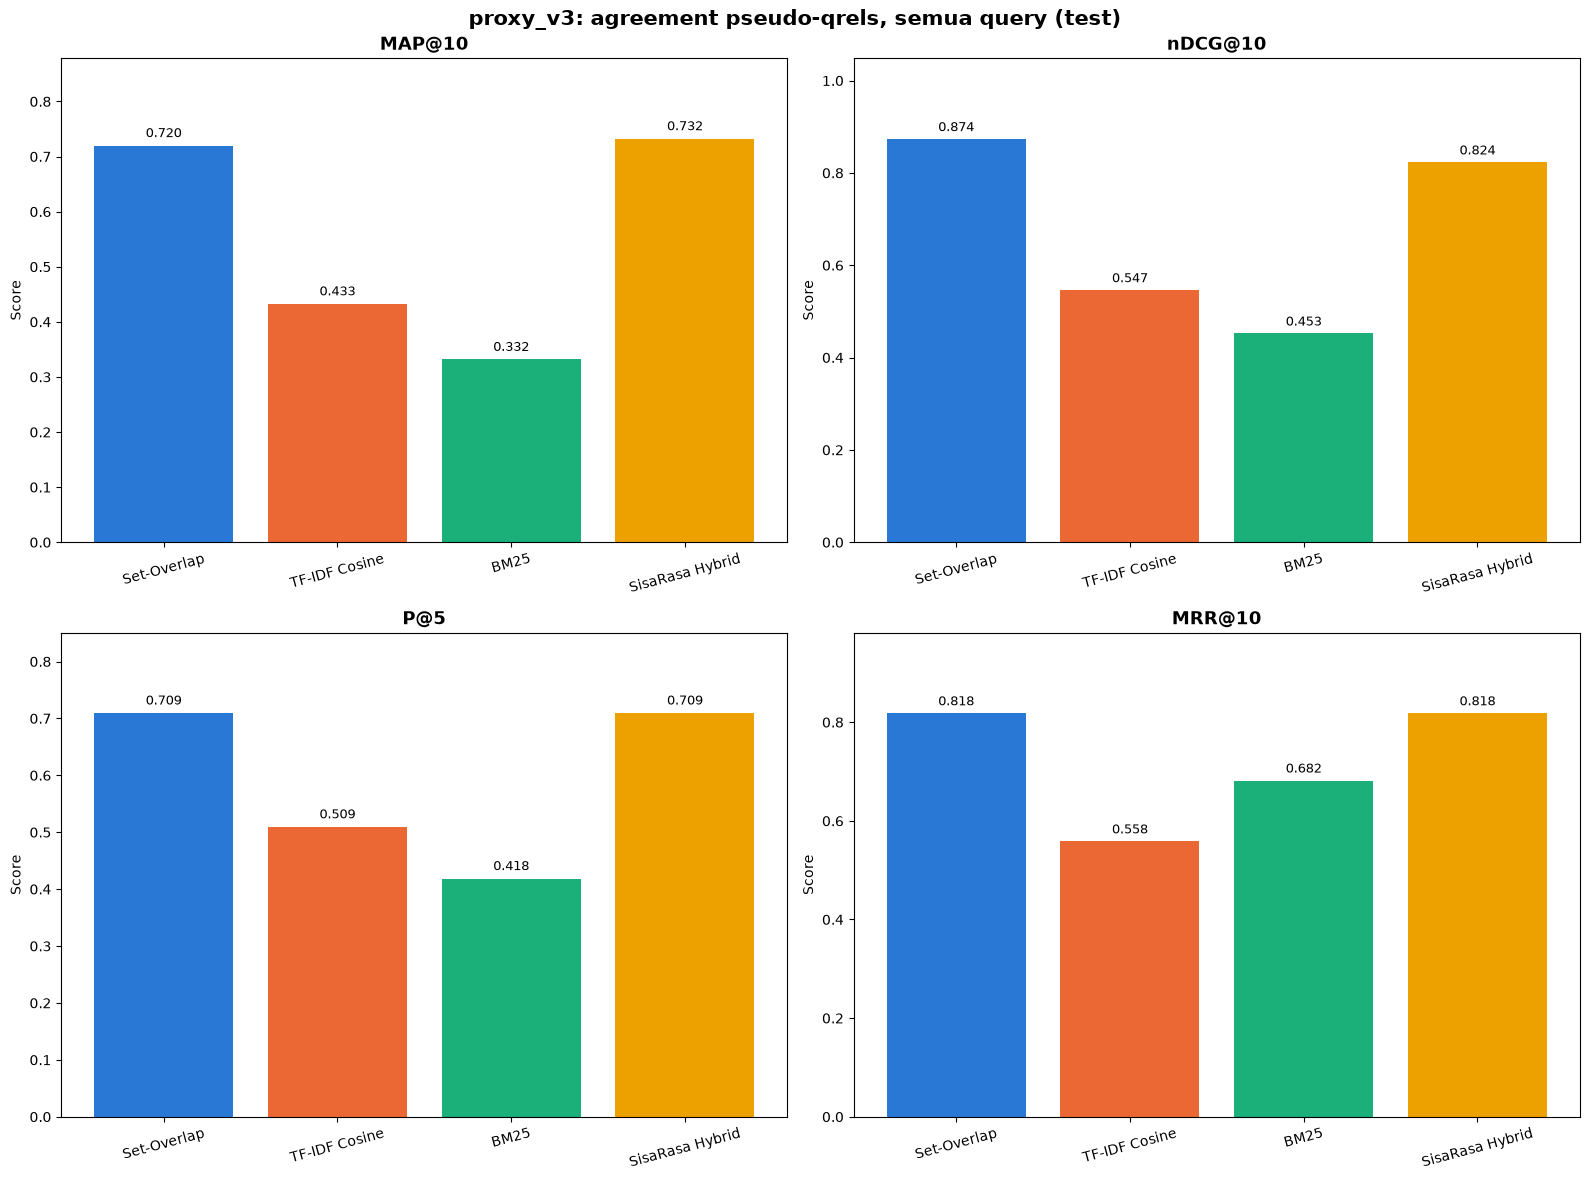

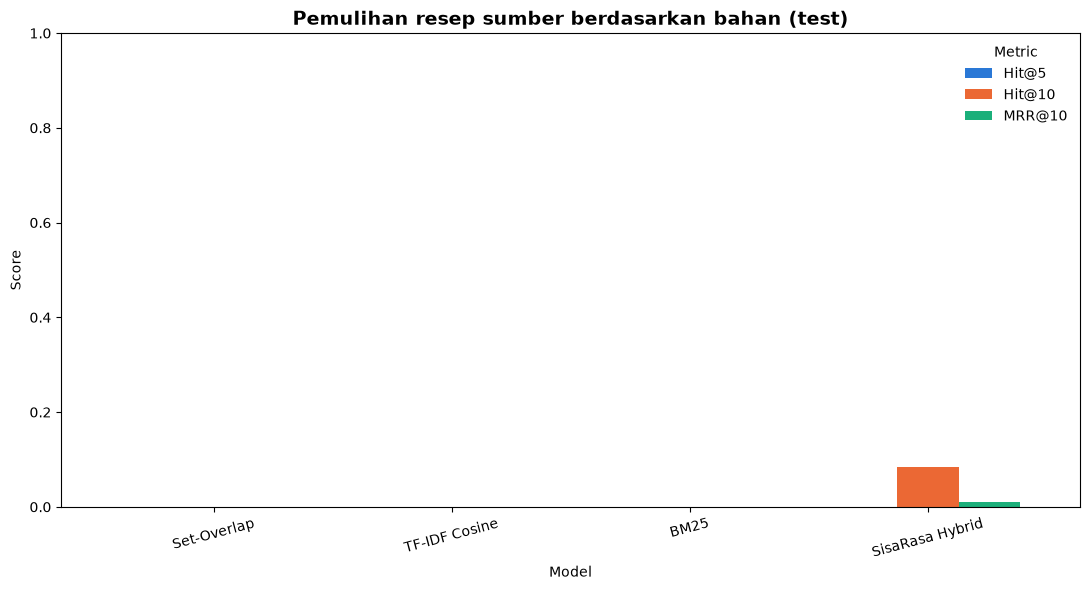

In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10: Evaluasi proxy dan known-item (MRR@10)
# ═══════════════════════════════════════════════════════════════════════════════

import math
from collections import defaultdict


class IRMetricsEvaluator:
    """Evaluate pseudo-qrels agreement or source-recipe recovery, not human relevance."""

    BINARY_THRESHOLD = 2
    EVALUATOR_VERSION = "pseudo_ir_metrics_v5"

    @staticmethod
    def precision_at_k(retrieved_grades: List[int], k: int, threshold: int = 2) -> float:
        if k <= 0:
            raise ValueError("k must be positive")
        return sum(grade >= threshold for grade in retrieved_grades[:k]) / k

    @staticmethod
    def recall_at_k(retrieved_grades: List[int], k: int, total_relevant: int,
                    threshold: int = 2) -> float:
        if total_relevant <= 0:
            return 0.0
        return sum(grade >= threshold for grade in retrieved_grades[:k]) / total_relevant

    @staticmethod
    def f1_at_k(precision: float, recall: float) -> float:
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)

    @staticmethod
    def average_precision_at_k(retrieved_grades: List[int], k: int, total_relevant: int,
                               threshold: int = 2) -> float:
        if k <= 0:
            raise ValueError("k must be positive")
        denominator = min(k, total_relevant)
        if denominator <= 0:
            return 0.0
        num_relevant = 0
        precision_sum = 0.0
        for rank, grade in enumerate(retrieved_grades[:k], start=1):
            if grade >= threshold:
                num_relevant += 1
                precision_sum += num_relevant / rank
        return precision_sum / denominator

    @staticmethod
    def reciprocal_rank(retrieved_grades: List[int], threshold: int = 2) -> float:
        for rank, grade in enumerate(retrieved_grades[:10], start=1):
            if grade >= threshold:
                return 1.0 / rank
        return 0.0

    @staticmethod
    def hit_at_k(retrieved_grades: List[int], k: int, threshold: int = 2) -> float:
        return float(any(grade >= threshold for grade in retrieved_grades[:k]))

    @staticmethod
    def dcg_at_k(retrieved_grades: List[int], k: int) -> float:
        return sum((2**grade - 1) / math.log2(rank + 1)
                   for rank, grade in enumerate(retrieved_grades[:k], start=1))

    @classmethod
    def ndcg_at_k(cls, retrieved_grades: List[int], k: int, all_grades: List[int]) -> float:
        idcg = cls.dcg_at_k(sorted(all_grades, reverse=True), k)
        if idcg == 0:
            return 0.0
        return cls.dcg_at_k(retrieved_grades, k) / idcg

    def evaluate_model(self, model, queries: List[Dict], qrels: Dict[str, Dict[str, int]],
                       assessment_doc_ids: List[str], evaluation_type: str,
                       k_values: List[int] = None) -> Tuple[Dict, Dict, List[Dict]]:
        """Return overall-by-split, scenario-by-split and per-query records."""
        if not queries:
            raise ValueError("queries must be nonempty")
        query_ids = [query["query_id"] for query in queries]
        if any(not isinstance(qid, str) or not qid for qid in query_ids) or len(query_ids) != len(set(query_ids)):
            raise ValueError("query IDs must be nonempty unique strings")
        if evaluation_type not in {"proxy", "known_item"}:
            raise ValueError("evaluation_type must be 'proxy' or 'known_item'")
        if not assessment_doc_ids or len(assessment_doc_ids) != len(set(assessment_doc_ids)):
            raise ValueError("assessment_doc_ids must be a nonempty unique document universe")
        k_values = [5, 10] if k_values is None else sorted(set(k_values))
        if not k_values or any(k <= 0 for k in k_values):
            raise ValueError("k_values must contain positive cutoffs")
        max_k = max(10, max(k_values))
        allowed_ids = set(assessment_doc_ids)
        records = []
        for query in queries:
            qid = query["query_id"]
            if qid not in qrels:
                raise ValueError(f"Missing qrels for query: {qid}")
            qrels_for_query = qrels[qid]
            if any(isinstance(grade, (bool, np.bool_)) or not isinstance(grade, (int, np.integer))
                   or grade not in (0, 1, 2, 3) for grade in qrels_for_query.values()):
                raise ValueError("Qrels grades must be integers between 0 and 3")
            unknown_qrels = set(qrels_for_query) - allowed_ids
            if unknown_qrels:
                raise ValueError(f"Qrels outside assessment universe: {sorted(unknown_qrels)}")
            t0 = time.perf_counter()
            retrieved = model.retrieve(query["query_text"], top_k=max_k)
            latency_ms = (time.perf_counter() - t0) * 1000
            retrieved_ids = [doc_id for doc_id, _ in retrieved]
            if len(retrieved_ids) != len(set(retrieved_ids)):
                raise ValueError("Retriever returned duplicate document IDs")
            unknown_retrieved = set(retrieved_ids) - allowed_ids
            if unknown_retrieved:
                raise ValueError(f"Retrieved IDs outside assessment universe: {sorted(unknown_retrieved)}")
            retrieved_grades = [qrels_for_query.get(doc_id, 0) for doc_id in retrieved_ids]
            total_relevant = sum(grade >= self.BINARY_THRESHOLD for grade in qrels_for_query.values())
            metrics = {}
            if evaluation_type == "proxy":
                for k in k_values:
                    precision = self.precision_at_k(retrieved_grades, k)
                    recall = self.recall_at_k(retrieved_grades, k, total_relevant)
                    metrics[f"P@{k}"] = precision
                    metrics[f"R@{k}"] = recall
                    metrics[f"F1@{k}"] = self.f1_at_k(precision, recall)
                    metrics[f"nDCG@{k}"] = self.ndcg_at_k(
                        retrieved_grades, k, list(qrels_for_query.values())
                    )
                metrics["AP@10"] = self.average_precision_at_k(retrieved_grades, 10, total_relevant)
                metrics["RR@10"] = self.reciprocal_rank(retrieved_grades)
                zero_relevant = total_relevant == 0
                zero_idcg = not any(grade > 0 for grade in qrels_for_query.values())
            else:
                for k in k_values:
                    metrics[f"Hit@{k}"] = self.hit_at_k(retrieved_grades, k)
                metrics["RR@10"] = self.reciprocal_rank(retrieved_grades)
                zero_relevant = total_relevant == 0
                zero_idcg = None
            metrics["Latency (ms)"] = latency_ms
            records.append({
                "query_id": qid,
                "family_id": query.get("family_id"),
                "split": query.get("split", "unspecified"),
                "scenario": query.get("scenario", "default"),
                "evaluation_type": evaluation_type,
                "target_doc_id": query.get("target_doc_id"),
                "query_text": query["query_text"],
                "reference_query_text": query.get("reference_query_text", query["query_text"]),
                "expected_core_ingredients": query.get("expected_core_ingredients"),
                "observed_core_ingredients": query.get("observed_core_ingredients"),
                "normalization_exact_match": query.get("normalization_exact_match"),
                "retrieved_doc_ids": retrieved_ids,
                "retrieved_ranks": list(range(1, len(retrieved_ids) + 1)),
                "retrieved_grades": retrieved_grades,
                "total_relevant": total_relevant,
                "zero_relevant": zero_relevant,
                "zero_idcg": zero_idcg,
                **metrics,
            })

        record_frame = pd.DataFrame(records)
        metric_cols = [
            name for name in record_frame.columns
            if name not in {"query_id", "family_id", "split", "scenario", "evaluation_type",
                            "target_doc_id", "query_text", "reference_query_text",
                            "expected_core_ingredients", "observed_core_ingredients",
                            "normalization_exact_match", "retrieved_doc_ids", "retrieved_ranks",
                            "retrieved_grades", "total_relevant", "zero_relevant", "zero_idcg"}
        ]
        def summarize(group):
            aggregate_names = {"AP@10": "MAP@10", "RR@10": "MRR@10"}
            aggregate = {
                **{aggregate_names.get(name, name): round(float(group[name].mean()), 4)
                   for name in metric_cols},
                "query_count": len(group),
                "zero_relevant_queries": int(group["zero_relevant"].sum()),
                "zero_idcg_queries": int(group["zero_idcg"].sum()) if evaluation_type == "proxy" else None,
            }
            if evaluation_type == "proxy":
                binary_eligible = group.loc[~group["zero_relevant"]]
                ndcg_eligible = group.loc[~group["zero_idcg"]]
                for name in metric_cols:
                    if name == "Latency (ms)":
                        continue
                    eligible = ndcg_eligible if name.startswith("nDCG@") else binary_eligible
                    key = f"{aggregate_names.get(name, name)} (eligible)"
                    aggregate[key] = round(float(eligible[name].mean()), 4) if not eligible.empty else None
                aggregate["binary_eligible_queries"] = len(binary_eligible)
                aggregate["ndcg_eligible_queries"] = len(ndcg_eligible)
            return aggregate

        overall = {}
        scenario_results = {}
        for split, split_group in record_frame.groupby("split", sort=True):
            overall[split] = summarize(split_group)
            scenario_results[split] = {}
            for scenario, group in split_group.groupby("scenario", sort=True):
                scenario_results[split][scenario] = summarize(group)
        return overall, scenario_results, records

def _check_eligible_aggregation():
    class FixtureRetriever:
        def retrieve(self, query_text, top_k):
            return [("doc", 1.0)]

    queries = [
        {"query_id": "binary", "query_text": "binary", "split": "test", "scenario": "eligible"},
        {"query_id": "grade_one", "query_text": "grade_one", "split": "test", "scenario": "eligible"},
        {"query_id": "empty", "query_text": "empty", "split": "test", "scenario": "empty"},
    ]
    qrels = {"binary": {"doc": 2}, "grade_one": {"doc": 1}, "empty": {}}
    overall, scenarios, records = IRMetricsEvaluator().evaluate_model(
        FixtureRetriever(), queries, qrels, ["doc"], "proxy"
    )
    metrics = overall["test"]
    assert metrics["query_count"] == 3
    assert metrics["MAP@10"] == round(1 / 3, 4)
    assert metrics["nDCG@10"] == round(2 / 3, 4)
    assert metrics["binary_eligible_queries"] == 1
    assert metrics["ndcg_eligible_queries"] == 2
    assert metrics["MAP@10 (eligible)"] == 1.0
    assert metrics["nDCG@10 (eligible)"] == 1.0
    assert scenarios["test"]["empty"]["MAP@10 (eligible)"] is None
    assert scenarios["test"]["empty"]["nDCG@10 (eligible)"] is None
    grade_one = next(record for record in records if record["query_id"] == "grade_one")
    assert grade_one["zero_relevant"] and not grade_one["zero_idcg"]


_check_eligible_aggregation()
def _check_v4_evaluation_validation():
    class FixtureRetriever:
        def retrieve(self, query, top_k):
            return [("doc", 1.0)]

    query = {"query_id": "q", "query_text": "x", "split": "test", "scenario": "A"}
    evaluator = IRMetricsEvaluator()
    evaluator.evaluate_model(FixtureRetriever(), [query], {"q": {"doc": 2}}, ["doc"], "proxy")
    invalid_cases = [([query], {"q": {"doc": 4}}), ([query], {"q": {"doc": True}}),
                     ([query, query], {"q": {"doc": 2}})]
    for queries, qrels in invalid_cases:
        try:
            evaluator.evaluate_model(FixtureRetriever(), queries, qrels, ["doc"], "proxy")
        except ValueError:
            continue
        raise AssertionError("Invalid qrels or duplicate query IDs must be rejected")


_check_v4_evaluation_validation()
assert IRMetricsEvaluator.precision_at_k([2, 2], 5) == 0.4
assert IRMetricsEvaluator.average_precision_at_k([2, 2], 10, 12) == 0.2
assert IRMetricsEvaluator.reciprocal_rank([0] * 10 + [2]) == 0.0
assert IRMetricsEvaluator.ndcg_at_k([3, 2], 2, [3, 2]) == 1.0

# ── Run Evaluation ───────────────────────────────────────────────────────────
# ── Run Evaluation ------------------------------------------------------------
for benchmark_name, benchmark_queries in (("proxy", proxy_queries), ("known_item", known_item_queries)):
    if not any(query["split"] == "test" for query in benchmark_queries):
        raise ValueError(f"No test queries for {benchmark_name}; cannot report test metrics")
print("[EVAL] Mengukur agreement pseudo-qrels dan pemulihan resep sumber berdasarkan bahan ...")
evaluator = IRMetricsEvaluator()
k_values = [5, 10]

proxy_overall_results = {}
proxy_scenario_results = {}
proxy_per_query_records = {}
known_item_overall_results = {}
known_item_scenario_results = {}
known_item_per_query_records = {}

for model_name, model in models.items():
    print(f"  Evaluating {model_name} ...")
    proxy_overall, proxy_scenarios, proxy_records = evaluator.evaluate_model(
        model, proxy_queries, proxy_qrels, proxy_assessment_doc_ids, "proxy", k_values
    )
    known_overall, known_scenarios, known_records = evaluator.evaluate_model(
        model, known_item_queries, known_item_qrels, proxy_assessment_doc_ids,
        "known_item", k_values,
    )
    proxy_overall_results[model_name] = proxy_overall
    proxy_scenario_results[model_name] = proxy_scenarios
    proxy_per_query_records[model_name] = proxy_records
    known_item_overall_results[model_name] = known_overall
    known_item_scenario_results[model_name] = known_scenarios
    known_item_per_query_records[model_name] = known_records

assert all("MAP@10" in metrics and "MRR@10" in metrics
           for split_results in proxy_overall_results.values() for metrics in split_results.values())
assert all("RR@10" in record and "MRR@10" not in record
           for records in proxy_per_query_records.values() for record in records)
print("[OK] Agreement proxy dan pemulihan resep sumber dievaluasi terpisah.")

# -- Proxy recommendation: agreement with the proxy_v3 rubric ------------------
proxy_test_results = {
    model: results.get("test", {}) for model, results in proxy_overall_results.items()
}
proxy_test_frame = pd.DataFrame(proxy_test_results).T
proxy_test_frame.index.name = "Model"
print(f"\n{benchmark_rubric_version}: agreement semua query dan query eligible (test split)")
print("Eligible: grade >= 2 untuk metrik biner; IDCG > 0 untuk nDCG.")
print(proxy_test_frame.to_string())

# -- Source recipe recovery from ingredients ----------------------------------
known_test_results = {
    model: results.get("test", {}) for model, results in known_item_overall_results.items()
}
known_test_frame = pd.DataFrame(known_test_results).T
known_test_frame.index.name = "Model"
print("\nPemulihan resep sumber berdasarkan bahan: Hit@k dan MRR@10 (test split)")
print("Target sumber bukan satu-satunya resep yang mungkin relevan.")
print(known_test_frame.to_string())

# -- Per-query records retain split, family, ranks, grades and denominator flags.
proxy_per_query_df = pd.DataFrame([
    {"model": model_name, **record}
    for model_name, records in proxy_per_query_records.items() for record in records
]).sort_values(["model", "query_id"], kind="stable").reset_index(drop=True)
known_item_per_query_df = pd.DataFrame([
    {"model": model_name, **record}
    for model_name, records in known_item_per_query_records.items() for record in records
]).sort_values(["model", "query_id"], kind="stable").reset_index(drop=True)

def evaluate_spelling_pair(parser, retrievers, clean_query, typo_query, top_k=10):
    clean = parser.parse_query(clean_query)
    typo = parser.parse_query(typo_query)
    reference = clean["ingredients_core_set"]
    normalized_equal = bool(reference) and reference == typo["ingredients_core_set"]
    rows = []
    for model_name, model in retrievers.items():
        clean_ids = [doc_id for doc_id, _ in model.retrieve(clean_query, top_k=top_k)]
        typo_ids = [doc_id for doc_id, _ in model.retrieve(typo_query, top_k=top_k)]
        union = set(clean_ids) | set(typo_ids)
        rows.append({
            "model": model_name,
            "clean_query": clean_query,
            "typo_query": typo_query,
            "clean_core": json.dumps(sorted(reference), ensure_ascii=False),
            "typo_core": json.dumps(sorted(typo["ingredients_core_set"]), ensure_ascii=False),
            "corrections": json.dumps(typo.get("corrections", []), ensure_ascii=False),
            "normalized_equal": normalized_equal,
            "clean_ids": json.dumps(clean_ids, ensure_ascii=False),
            "typo_ids": json.dumps(typo_ids, ensure_ascii=False),
            "same_order": clean_ids == typo_ids if union else None,
            "top_k_jaccard": len(set(clean_ids) & set(typo_ids)) / len(union) if union else None,
        })
    return pd.DataFrame(rows)


def _check_v4_spelling_pair():
    class FixtureRetriever:
        def retrieve(self, query, top_k):
            return [("recipe", 1.0)]

    parser = IndonesianIngredientParser()
    results = evaluate_spelling_pair(parser, {"fixture": FixtureRetriever()}, "bawang goreng", "bwang greng")
    assert results.loc[0, "normalized_equal"]
    assert results.loc[0, "same_order"]
    assert results.loc[0, "top_k_jaccard"] == 1.0


_check_v4_spelling_pair()
spelling_results_df = evaluate_spelling_pair(PARSER, models, "bawang goreng", "bwang greng")
print("\nPemeriksaan satu pasangan ejaan sintetis, bukan evaluasi pengguna:")
print(spelling_results_df[["model", "normalized_equal", "same_order", "top_k_jaccard"]].to_string(index=False))

# -- Visualizations -------------------------------------------------------------
# One plot per evaluation objective; no combined scale implies cross-objective comparability.
proxy_metric_names = ["MAP@10", "nDCG@10", "P@5", "MRR@10"]
known_metric_names = ["Hit@5", "Hit@10", "MRR@10"]
model_names = list(models)
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

proxy_metrics = proxy_test_frame.reindex(columns=proxy_metric_names, fill_value=0)
fig_proxy, axes_proxy = plt.subplots(2, 2, figsize=(16, 12))
fig_proxy.suptitle(
    f"{benchmark_rubric_version}: agreement pseudo-qrels, semua query (test)",
    fontsize=15, fontweight="bold",
)
for ax, metric in zip(axes_proxy.flatten(), proxy_metric_names):
    values = [float(proxy_metrics.loc[name].get(metric, 0)) for name in model_names]
    bars = ax.bar(model_names, values, color=colors[:len(model_names)], linewidth=0)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, max(max(values, default=0) * 1.2, 0.1))
    ax.tick_params(axis="x", rotation=15)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{value:.3f}", ha="center", va="bottom", fontsize=9)
fig_proxy.tight_layout()
plt.show()

known_metrics = known_test_frame.reindex(columns=known_metric_names, fill_value=0)
fig_known, ax_known = plt.subplots(figsize=(11, 6))
known_metrics.plot(kind="bar", ax=ax_known, color=colors[:len(model_names)], width=0.78)
ax_known.set_title("Pemulihan resep sumber berdasarkan bahan (test)", fontsize=14, fontweight="bold")
ax_known.set_ylabel("Score")
ax_known.set_ylim(0, 1.0)
ax_known.set_xticklabels(model_names, rotation=15)
ax_known.legend(title="Metric", frameon=False)
fig_known.tight_layout()
plt.show()
evaluation_normalization_version = benchmark_normalization_version

evaluation_rubric_version = benchmark_rubric_version


## Eksperimen tambahan: ablation dan diagnostik ejaan

Sel definisi berikut diikuti pemeriksaan sintetis dan satu sel **EKSPERIMEN RISET UTS**. Pada kernel yang masih memiliki model serta hasil Cell 10, cukup jalankan semua sel riset baru secara berurutan. Operasinya menghitung tabel di memori; Cell 12 menyimpan run baru jika dipanggil.

**Ablation** menggunakan shallow copy model terindeks agar matriks tidak dibangun ulang. Hanya bobot komponen yang sedang diuji diubah pada salinan; indeks dan model utama tetap. Tiga varian memakai query, split, evaluator, dan qrels identik. Berkurang atau bertambahnya metrik tidak langsung membuktikan kualitas menurut pengguna karena rubric memiliki sinyal yang sama.

**Diagnostik ejaan** memakai 36 kasus tetap: alias terkurasi, penghapusan huruf, penggantian huruf, kandidat ambigu, pertukaran huruf, input terlalu pendek, input valid, dan kata tidak dikenal. Beberapa kasus disengaja berada di luar batas kemampuan sekarang. Jangan menghapus kasus yang gagal untuk memperbaiki rata-rata.

Target setiap kasus dinyatakan sebelum evaluasi. Contoh `susi` muncul dengan dua intent susu yang berbeda; keduanya menunjukkan ambiguitas, bukan dua sampel pengguna independen. Tabel juga melaporkan jumlah input dan target unik per jenis kasus.

- **Candidate offer recall:** proporsi kasus fuzzy dengan target tersedia yang menawarkan target benar. Alias otomatis dan kontrol tidak masuk denominator ini.
- **Normalisasi sebelum/sesudah oracle:** proporsi seluruh kasus typo dengan target tersedia yang menjadi bahan target secara tepat; sesudah oracle hanya memakai kandidat yang benar-benar ditawarkan.
- **False suggestion pada input valid:** proporsi kontrol valid yang mendapat saran perubahan.
- **Suggestion on unknown:** proporsi kontrol kata tidak dikenal yang mendapat saran. Ini ukuran perilaku pada kontrol yang dipilih, bukan seluruh kata asing.
- **No suggestion pada typo belum teratasi:** proporsi typo tersedia yang belum benar sebelum pilihan dan tidak mendapat saran.
- **Ranking consistency:** overlap top-10 dan kesamaan urutan terhadap hasil query target bersih. Ini bukan pengukuran relevansi independen. Referensi bersih tanpa hasil diberi nilai tidak tersedia, bukan overlap sempurna.

Kasus dengan target yang tidak terdapat dalam korpus tetap disimpan dan dihitung sebagai keterbatasan cakupan; kasus tersebut tidak masuk denominator keberhasilan target tersedia. Manifest ini merupakan diagnostic set buatan yang sudah diketahui, bukan untouched test atau data pengguna nyata.


In [10]:
# Ablation satu komponen; indeks dan bobot model utama tidak diubah.
def run_hybrid_ablation(model, queries, qrels, assessment_doc_ids, k_values=None):
    import copy

    if not model.doc_ids:
        raise ValueError("Ablation requires an indexed Hybrid model")
    evaluator = IRMetricsEvaluator()
    summaries, records = [], []
    for variant, disabled_weight in (
        ("full", None), ("without_protein", "w_prot"),
        ("without_missing_penalty", "w5"),
    ):
        candidate = copy.copy(model)
        if disabled_weight:
            setattr(candidate, disabled_weight, 0.0)
        overall, _, per_query = evaluator.evaluate_model(
            candidate, queries, qrels, assessment_doc_ids, "proxy", k_values
        )
        summaries.extend({"variant": variant, "split": split, **metrics}
                         for split, metrics in overall.items())
        records.extend({"variant": variant, **record} for record in per_query)
    return pd.DataFrame(summaries), pd.DataFrame(records)


In [11]:
def evaluate_typo_cases(parser, retrievers, cases, available_ingredients, top_k=10):
    """Evaluate fixed single-ingredient cases; accept only an offered expected candidate."""
    if not cases or not retrievers:
        raise ValueError("Benchmark cases and retrievers must be nonempty")
    if isinstance(top_k, bool) or not isinstance(top_k, int) or top_k <= 0:
        raise ValueError("top_k must be a positive integer")
    case_ids = [case.get("case_id") for case in cases]
    if any(not isinstance(key, str) or not key for key in case_ids) or len(set(case_ids)) != len(case_ids):
        raise ValueError("Benchmark case IDs must be nonempty unique strings")
    kinds = {"deletion", "substitution", "transposition", "ambiguous", "short",
             "curated_alias", "valid", "unknown"}
    for case in cases:
        kind, query, expected = case.get("kind"), case.get("query_text"), case.get("expected_ingredient")
        if kind not in kinds or not isinstance(query, str) or not query.strip():
            raise ValueError("Invalid benchmark case kind or query")
        if kind == "unknown":
            if expected is not None:
                raise ValueError("Unknown controls must not declare an expected ingredient")
        elif not isinstance(expected, str) or not expected.strip():
            raise ValueError("Labeled cases must declare an expected ingredient")
        if expected is not None and parser.parse_ingredient_line(expected) != expected:
            raise ValueError("Expected ingredients must be canonical names")

    details, retrieval = [], []
    for case in cases:
        query, expected = case["query_text"], case["expected_ingredient"]
        before = parser.parse_query(query)
        candidates = sorted({name for item in before["suggestions"] for name in item["candidates"]})
        available = expected is not None and expected in available_ingredients
        choices = {item["original"]: expected for item in before["suggestions"]
                   if available and expected in item["candidates"]}
        after = parser.parse_query(query, ingredient_choices=choices)
        details.append({
            **case, "target_available": available,
            "has_suggestion": bool(before["suggestions"]),
            "candidate_count": len(candidates),
            "candidates": json.dumps(candidates, ensure_ascii=False),
            "candidate_offered": expected in candidates,
            "oracle_choices": json.dumps(choices, ensure_ascii=False),
            "oracle_selection_applied": bool(choices),
            "resolved_before": before["resolved_query"],
            "resolved_after": after["resolved_query"],
            "normalized_before": before["ingredients_all_set"] == {expected} if expected else None,
            "normalized_after": after["ingredients_all_set"] == {expected} if expected else None,
        })
        for model_name, model in retrievers.items():
            query_texts = [before["resolved_query"], after["resolved_query"]]
            if expected:
                query_texts.append(expected)
            ranked = {
                text: [doc_id for doc_id, _ in model.retrieve(text, top_k=top_k)]
                for text in dict.fromkeys(query_texts)
            }
            clean_ids = ranked[expected] if expected else []
            record = {
                "model": model_name, "case_id": case["case_id"], "kind": case["kind"],
                "target_available": available, "oracle_selection_applied": bool(choices),
                "reference_has_results": bool(clean_ids),
                "reference_query": expected, "original_query": query,
                "resolved_before": before["resolved_query"], "resolved_after": after["resolved_query"],
                "clean_doc_ids": json.dumps(clean_ids),
            }
            for suffix, text in (("before", before["resolved_query"]), ("after", after["resolved_query"])):
                result_ids = ranked[text]
                union = set(clean_ids) | set(result_ids)
                record[f"doc_ids_{suffix}"] = json.dumps(result_ids)
                record[f"same_order_{suffix}"] = result_ids == clean_ids if clean_ids else None
                record[f"top_k_jaccard_{suffix}"] = (
                    len(set(clean_ids) & set(result_ids)) / len(union) if clean_ids else None
                )
            retrieval.append(record)
    return pd.DataFrame(details), pd.DataFrame(retrieval)


def summarize_typo_cases(details):
    """Expose each denominator; unavailable targets do not inflate typo accuracy."""
    typo = ~details["kind"].isin(["valid", "unknown"]) & details["target_available"]
    fuzzy = typo & ~details["kind"].eq("curated_alias")
    unresolved = typo & ~details["normalized_before"].eq(True)
    definitions = [
        ("candidate_offer_recall", fuzzy, details["candidate_offered"]),
        ("normalization_before", typo, details["normalized_before"].eq(True)),
        ("normalization_after_oracle", typo, details["normalized_after"].eq(True)),
        ("false_suggestion_valid", details["kind"].eq("valid"), details["has_suggestion"]),
        ("suggestion_on_unknown", details["kind"].eq("unknown"), details["has_suggestion"]),
        ("no_suggestion_unresolved", unresolved, ~details["has_suggestion"]),
    ]
    rows = []
    for metric, eligible, successful in definitions:
        denominator = int(eligible.sum())
        numerator = int((eligible & successful).sum())
        rows.append({"metric": metric, "numerator": numerator, "denominator": denominator,
                     "rate": numerator / denominator if denominator else None})
    return pd.DataFrame(rows)


In [12]:
def paired_query_comparison(frame, left, right, metric, split="test"):
    """Descriptive matched-query differences; no significance or causal claim."""
    selected = frame[frame["split"].eq(split) & frame["model"].isin([left, right])]
    if selected.empty or selected.duplicated(["model", "query_id"]).any():
        raise ValueError("Paired comparison requires unique nonempty model-query records")
    left_rows = selected[selected["model"].eq(left)].set_index("query_id")
    right_rows = selected[selected["model"].eq(right)].set_index("query_id")
    if left_rows.empty or set(left_rows.index) != set(right_rows.index):
        raise ValueError("Paired comparison requires the same query IDs for both models")
    right_rows = right_rows.reindex(left_rows.index)
    if (left_rows["family_id"].isna().any()
            or not left_rows["family_id"].equals(right_rows["family_id"])):
        raise ValueError("Paired comparison requires matching query families")
    values = np.column_stack((left_rows[metric].to_numpy(dtype=float),
                              right_rows[metric].to_numpy(dtype=float)))
    if not np.isfinite(values).all():
        raise ValueError("Paired scores must be finite")
    differences = values[:, 0] - values[:, 1]
    return {
        "left": left, "right": right, "metric": metric, "split": split,
        "query_count": len(differences), "family_count": left_rows["family_id"].nunique(),
        "wins": int((differences > 1e-10).sum()),
        "ties": int((np.abs(differences) <= 1e-10).sum()),
        "losses": int((differences < -1e-10).sum()),
        "mean_delta": float(differences.mean()),
    }


In [13]:
# Pemeriksaan regresi eksperimen riset; fixture kecil tanpa jaringan atau ekspor.
def _research_fixture():
    parser = IndonesianIngredientParser()
    recipes = [
        ("protein", ["ayam", "tempe", "tahu"]),
        ("shallot", ["bawang merah"]),
        ("long", ["ayam", "wortel", "tomat", "kentang", "buncis", "kubis"]),
        ("carrot", ["wortel"]),
        ("tofu", ["tahu"]),
        ("oil", ["minyak goreng"]),
        ("dirty", ["minyk"]),
        ("milk", ["susu"]),
        ("liquid", ["susu cair"]),
        ("powder", ["susu bubuk"]),
        ("fried", ["bawang goreng"]),
    ]
    corpus = pd.DataFrame([
        {"doc_id": doc_id, "title_ir_text": " ".join(ingredients),
         **parser.extract_ingredients_from_recipe(ingredients)}
        for doc_id, ingredients in recipes
    ])
    parser.set_known_ingredients(set().union(*corpus["ingredients_all_set"]))
    overlap = SetOverlapRetriever(parser)
    tfidf = TfidfCosineRetriever(parser)
    bm25 = BM25Retriever(parser)
    hybrid = SisaRasaHybridRetriever(parser, bm25, tfidf, w1=0, w2=0)
    retrievers = {"Set-Overlap": overlap, "TF-IDF Cosine": tfidf,
                  "BM25": bm25, "SisaRasa Hybrid": hybrid}
    for model in retrievers.values():
        model.index(corpus)
    return parser, corpus, retrievers


def _check_research_ablation():
    _, corpus, retrievers = _research_fixture()
    hybrid = retrievers["SisaRasa Hybrid"]
    query = {"query_id": "q", "query_text": "ayam, bawang merah",
             "split": "test", "scenario": "fixture", "family_id": "f"}
    original_weights = (hybrid.w_prot, hybrid.w5)
    original_ids = hybrid.retrieve(query["query_text"], top_k=1)
    summary, records = run_hybrid_ablation(
        hybrid, [query], {"q": {"protein": 3}}, corpus["doc_id"].tolist()
    )
    tops = {row["variant"]: row["retrieved_doc_ids"][0] for row in records.to_dict("records")}
    assert tops["full"] == "protein"
    assert tops["without_protein"] == "shallot"
    assert (hybrid.w_prot, hybrid.w5) == original_weights
    assert hybrid.retrieve(query["query_text"], top_k=1) == original_ids
    assert len(summary) == 3 and set(records["query_id"]) == {"q"}

    hybrid.w_prot, hybrid.w5 = 0, 1.5
    query = {**query, "query_text": "ayam, wortel"}
    _, records = run_hybrid_ablation(
        hybrid, [query], {"q": {"long": 3}}, corpus["doc_id"].tolist()
    )
    tops = {row["variant"]: row["retrieved_doc_ids"][0] for row in records.to_dict("records")}
    assert tops["full"] == "carrot"
    assert tops["without_missing_penalty"] == "long"
    assert hybrid.w5 == 1.5 and hybrid.w_prot == 0


def _check_research_typo_benchmark():
    parser, corpus, retrievers = _research_fixture()
    cases = [
        {"case_id": "a", "kind": "deletion", "query_text": "thu", "expected_ingredient": "tahu"},
        {"case_id": "b", "kind": "ambiguous", "query_text": "susi", "expected_ingredient": "susu cair"},
        {"case_id": "c", "kind": "transposition", "query_text": "thau", "expected_ingredient": "tahu"},
        {"case_id": "d", "kind": "valid", "query_text": "tahu", "expected_ingredient": "tahu"},
        {"case_id": "e", "kind": "unknown", "query_text": "xyzq", "expected_ingredient": None},
        {"case_id": "f", "kind": "curated_alias", "query_text": "bwang greng", "expected_ingredient": "bawang goreng"},
        {"case_id": "g", "kind": "deletion", "query_text": "udng", "expected_ingredient": "udang"},
        {"case_id": "h", "kind": "deletion", "query_text": "minyk", "expected_ingredient": "minyak goreng"},
    ]
    available = set().union(*corpus["ingredients_all_set"])
    details, retrieval = evaluate_typo_cases(parser, retrievers, cases, available)
    by_id = details.set_index("case_id")
    assert by_id.loc["a", "candidate_offered"]
    assert by_id.loc["a", "resolved_before"] == "thu"
    assert by_id.loc["a", "resolved_after"] == "tahu"
    assert by_id.loc["b", "candidate_count"] >= 2
    assert by_id.loc["b", "resolved_after"] == "susu cair"
    assert not by_id.loc["c", "normalized_after"]
    assert not by_id.loc["g", "target_available"]
    assert by_id.loc["h", "candidate_offered"]  # Raw corpus typo is not a valid-name veto.
    assert not by_id.loc["d", "has_suggestion"] and not by_id.loc["e", "has_suggestion"]
    rates = summarize_typo_cases(details).set_index("metric")
    assert rates.loc["candidate_offer_recall", "denominator"] == 4
    assert rates.loc["candidate_offer_recall", "rate"] == 0.75
    assert rates.loc["normalization_before", "rate"] == 0.2
    assert rates.loc["normalization_after_oracle", "rate"] == 0.8
    assert rates.loc["false_suggestion_valid", "rate"] == 0.0
    assert rates.loc["suggestion_on_unknown", "rate"] == 0.0
    assert len(retrieval) == 32
    selected = retrieval[retrieval["case_id"].isin(["a", "b", "h"])]
    assert selected["same_order_after"].all()
    assert (selected["top_k_jaccard_after"] == 1.0).all()
    assert (selected["top_k_jaccard_before"] == 0.0).all()
    for invalid_cases in ([], cases + [cases[0]],
                          [{**cases[0], "expected_ingredient": None}],
                          [{**cases[0], "kind": "unrecognized"}]):
        try:
            evaluate_typo_cases(parser, retrievers, invalid_cases, available)
        except ValueError:
            continue
        raise AssertionError("Invalid benchmark manifest must be rejected")
    try:
        evaluate_typo_cases(parser, retrievers, cases, available, top_k=0)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid cutoff must be rejected")


def _check_research_pairing():
    frame = pd.DataFrame([
        {"model": model, "query_id": query, "family_id": family,
         "split": "test", "AP@10": score}
        for model, scores in [("left", [0.8, 0.5, 0.2]), ("right", [0.6, 0.5, 0.4])]
        for query, family, score in zip(["q1", "q2", "q3"], ["f1", "f1", "f2"], scores)
    ])
    result = paired_query_comparison(frame, "left", "right", "AP@10")
    assert result["wins"] == result["ties"] == result["losses"] == 1
    assert abs(result["mean_delta"]) < 1e-12
    assert result["query_count"] == 3 and result["family_count"] == 2
    for invalid in (frame.iloc[:-1], pd.concat([frame, frame.iloc[:1]])):
        try:
            paired_query_comparison(invalid, "left", "right", "AP@10")
        except ValueError:
            continue
        raise AssertionError("Pairing must reject missing or duplicate query records")

def _check_v4_egg_protein_scoring():
    parser = IndonesianIngredientParser()
    recipes = [("white", "putih telur"), ("yolk", "kuning telur"),
               ("whole", "telur"), ("tofu", "tahu"), ("vegetables", None)]
    corpus = pd.DataFrame([
        {"doc_id": doc_id, "title_ir_text": "resep",
         **parser.extract_ingredients_from_recipe(
             ([protein] if protein else []) + ["wortel", "tomat"])}
        for doc_id, protein in recipes
    ])
    bm25, tfidf = BM25Retriever(parser), TfidfCosineRetriever(parser)
    hybrid = SisaRasaHybridRetriever(parser, bm25, tfidf, w1=0, w2=0)
    for model in (bm25, tfidf, hybrid):
        model.index(corpus)
    for ingredient, matching_id in (("putih telur", "white"), ("kuning telur", "yolk"),
                                    ("telur", "whole"), ("tahu", "tofu")):
        query = f"{ingredient}, wortel, tomat"
        full = dict(hybrid.retrieve(query))
        hybrid.w_prot = 0
        ablated = dict(hybrid.retrieve(query))
        hybrid.w_prot = 0.25
        for doc_id, _ in recipes:
            expected = 0.0 if doc_id == "vegetables" else (0.25 if doc_id == matching_id else -0.125)
            contribution = full.get(doc_id, 0.0) - ablated.get(doc_id, 0.0)
            assert np.isclose(contribution, expected), (ingredient, doc_id, contribution, expected)
    full = hybrid.retrieve("wortel, tomat")
    hybrid.w_prot = 0
    assert hybrid.retrieve("wortel, tomat") == full


def _check_v4_egg_protein_qrels():
    parser = IndonesianIngredientParser()
    recipes = [("white", "putih telur"), ("yolk", "kuning telur"),
               ("whole", "telur"), ("vegetables", None)]
    corpus = pd.DataFrame([
        {"doc_id": doc_id, **parser.extract_ingredients_from_recipe(
            ([protein] if protein else []) + ["wortel", "tomat"])}
        for doc_id, protein in recipes
    ])
    judge = QrelGenerator(corpus, parser)
    for ingredient, matching_id in (("putih telur", "white"), ("kuning telur", "yolk"),
                                    ("telur", "whole")):
        grades = judge.grade_query(f"{ingredient}, wortel, tomat")
        assert grades[matching_id] == 3, (ingredient, grades)
        assert grades["vegetables"] == 1, (ingredient, grades)
        for other_id in {"white", "yolk", "whole"} - {matching_id}:
            assert grades[other_id] == 1, (ingredient, other_id, grades)
    assert judge.grade_query("wortel, tomat") == {
        "white": 3, "yolk": 3, "whole": 3, "vegetables": 3,
    }


_check_v4_egg_protein_scoring()
_check_v4_egg_protein_qrels()


In [14]:
# EKSPERIMEN RISET UTS: jalankan setelah Cell 10 dan seluruh definisi riset di atas.
# Semua operasi di sel ini berjalan di memori; ekspor tetap di Cell 12.
_check_research_ablation()
_check_research_typo_benchmark()
_check_research_pairing()
print("[OK] Tiga pemeriksaan regresi eksperimen riset lulus.")

RESEARCH_PROTOCOL = {
    "version": "sisarasa_v4_research_1",
    "normalization_version": evaluation_normalization_version,
    "proxy_qrel_version": evaluation_rubric_version,
    "analysis_status": "exploratory_after_inspecting_original_results",
    "primary_metric": "nDCG@10",
    "secondary_metrics": ["MAP@10", "P@5"],
    "hypothesis_policy": "no guaranteed winner; no significance claim from mean scores",
    "ablation": {"full": None, "without_protein": {"w_prot": 0.0},
                 "without_missing_penalty": {"w5": 0.0}},
    "ablation_policy": "one disabled component; other weights unchanged; no renormalization",
    "assessment_policy": f"same corpus, {evaluation_rubric_version} qrels, queries, and splits for every variant",
    "spelling_status": "handcrafted diagnostic examples, not a held-out user benchmark",
    "spelling_selection": "oracle selects the expected ingredient only when actually offered and available",
    "spelling_denominators": "candidate recall excludes curated aliases, valid controls, unknowns and unavailable targets; normalization rates include available typo targets; control rates use all respective controls",
    "spelling_retrieval_metric": "overlap and order against clean-query ranking, not independent relevance",
    "duplicate_intent_policy": "one input may have multiple milk targets; report unique input and target counts, not independent samples",
    "known_item_policy": "count ingredient-compatible recipes as ambiguity diagnostics; do not change source-target qrels",
    "remaining_limits": ["small inspected query set", "proxy rubric shares Hybrid features",
                         "no human relevance labels", "no fresh confirmatory holdout",
                         "no independent parser accuracy audit", "latency remains descriptive"],
}

ablation_summary_df, ablation_per_query_df = run_hybrid_ablation(
    model_hybrid, proxy_queries, proxy_qrels, proxy_assessment_doc_ids, k_values
)
print("\nAblation Hybrid: bobot tetap, satu komponen dinonaktifkan")
print(ablation_summary_df[
    ["variant", "split", "query_count", "MAP@10", "nDCG@10", "P@5"]
].to_string(index=False))
print("Selisih terhadap pseudo-qrels, bukan bukti kontribusi pada kepuasan pengguna.")

# Manifest diagnostik tetap; contoh dipilih manual, bukan log pengguna atau untouched test.
typo_cases = [
    {"case_id": "SP01", "kind": "curated_alias", "query_text": "bwang greng",
     "expected_ingredient": "bawang goreng"},
    {"case_id": "SP02", "kind": "curated_alias", "query_text": "bawang purih",
     "expected_ingredient": "bawang putih"},
    {"case_id": "SP03", "kind": "deletion", "query_text": "minyk",
     "expected_ingredient": "minyak goreng"},
    {"case_id": "SP04", "kind": "deletion", "query_text": "thu",
     "expected_ingredient": "tahu"},
    {"case_id": "SP05", "kind": "deletion", "query_text": "bwang merah",
     "expected_ingredient": "bawang merah"},
    {"case_id": "SP06", "kind": "deletion", "query_text": "bawang puth",
     "expected_ingredient": "bawang putih"},
    {"case_id": "SP07", "kind": "deletion", "query_text": "wortl",
     "expected_ingredient": "wortel"},
    {"case_id": "SP08", "kind": "deletion", "query_text": "tomt",
     "expected_ingredient": "tomat"},
    {"case_id": "SP09", "kind": "deletion", "query_text": "kntang",
     "expected_ingredient": "kentang"},
    {"case_id": "SP10", "kind": "deletion", "query_text": "teme",
     "expected_ingredient": "tempe"},
    {"case_id": "SP11", "kind": "deletion", "query_text": "aym",
     "expected_ingredient": "ayam"},
    {"case_id": "SP12", "kind": "deletion", "query_text": "cabi rawit",
     "expected_ingredient": "cabai rawit"},
    {"case_id": "SP13", "kind": "deletion", "query_text": "jagng",
     "expected_ingredient": "jagung"},
    {"case_id": "SP14", "kind": "deletion", "query_text": "santn",
     "expected_ingredient": "santan"},
    {"case_id": "SP15", "kind": "deletion", "query_text": "mentimn",
     "expected_ingredient": "mentimun"},
    {"case_id": "SP16", "kind": "deletion", "query_text": "kecp manis",
     "expected_ingredient": "kecap manis"},
    {"case_id": "SP17", "kind": "substitution", "query_text": "wirtel",
     "expected_ingredient": "wortel"},
    {"case_id": "SP18", "kind": "substitution", "query_text": "tomot",
     "expected_ingredient": "tomat"},
    {"case_id": "SP19", "kind": "substitution", "query_text": "kenteng",
     "expected_ingredient": "kentang"},
    {"case_id": "SP20", "kind": "substitution", "query_text": "santam",
     "expected_ingredient": "santan"},
    {"case_id": "SP21", "kind": "ambiguous", "query_text": "susi",
     "expected_ingredient": "susu cair"},
    {"case_id": "SP22", "kind": "ambiguous", "query_text": "susi",
     "expected_ingredient": "susu bubuk"},
    {"case_id": "SP23", "kind": "transposition", "query_text": "thau",
     "expected_ingredient": "tahu"},
    {"case_id": "SP24", "kind": "transposition", "query_text": "tmepe",
     "expected_ingredient": "tempe"},
    {"case_id": "SP25", "kind": "short", "query_text": "th",
     "expected_ingredient": "tahu"},
    {"case_id": "SP26", "kind": "short", "query_text": "mk",
     "expected_ingredient": "minyak goreng"},
    {"case_id": "SP27", "kind": "valid", "query_text": "tahu",
     "expected_ingredient": "tahu"},
    {"case_id": "SP28", "kind": "valid", "query_text": "susu cair",
     "expected_ingredient": "susu cair"},
    {"case_id": "SP29", "kind": "valid", "query_text": "susu bubuk",
     "expected_ingredient": "susu bubuk"},
    {"case_id": "SP30", "kind": "valid", "query_text": "bawang putih",
     "expected_ingredient": "bawang putih"},
    {"case_id": "SP31", "kind": "valid", "query_text": "ayam",
     "expected_ingredient": "ayam"},
    {"case_id": "SP32", "kind": "valid", "query_text": "ikan",
     "expected_ingredient": "ikan"},
    {"case_id": "SP33", "kind": "valid", "query_text": "bayam",
     "expected_ingredient": "bayam"},
    {"case_id": "SP34", "kind": "valid", "query_text": "minyak goreng",
     "expected_ingredient": "minyak goreng"},
    {"case_id": "SP35", "kind": "unknown", "query_text": "xyzq",
     "expected_ingredient": None},
    {"case_id": "SP36", "kind": "unknown", "query_text": "qwerty bahan",
     "expected_ingredient": None},
]

available_ingredients = set().union(*df_all["ingredients_all_set"])
typo_case_results_df, typo_retrieval_results_df = evaluate_typo_cases(
    PARSER, models, typo_cases, available_ingredients
)
typo_summary_df = summarize_typo_cases(typo_case_results_df)
typo_coverage_df = (typo_case_results_df.groupby("kind", sort=True)
                    .agg(case_count=("case_id", "size"),
                         unique_inputs=("query_text", "nunique"),
                         unique_targets=("expected_ingredient", "nunique"))
                    .reset_index())
typo_retrieval_summary_df = (
    typo_retrieval_results_df.groupby("model", sort=True)
    .agg(case_count=("case_id", "size"),
         reference_cases=("reference_has_results", "sum"),
         mean_overlap_before=("top_k_jaccard_before", "mean"),
         mean_overlap_after_oracle=("top_k_jaccard_after", "mean"))
    .reset_index()
)
print("\nSaran ejaan: hitungan dan denominator eksplisit")
print(typo_summary_df.to_string(index=False))
print(typo_coverage_df.to_string(index=False))
print("Target tidak tersedia dalam korpus:",
      int((typo_case_results_df["expected_ingredient"].notna()
           & ~typo_case_results_df["target_available"]).sum()))
print(typo_case_results_df[
    ["case_id", "kind", "query_text", "expected_ingredient", "target_available",
     "candidates", "resolved_before", "resolved_after", "normalized_after"]
].to_string(index=False))
print("\nKonsistensi hasil terhadap query bersih; pilihan benar disimulasikan")
print(typo_retrieval_summary_df.to_string(index=False))
print("Kasus tanpa hasil referensi bersih tidak masuk rata-rata overlap, bukan diberi nilai sempurna.")

paired_comparison_df = pd.DataFrame([
    paired_query_comparison(proxy_per_query_df, "SisaRasa Hybrid", baseline, metric, split)
    for split in sorted(proxy_per_query_df["split"].unique())
    for baseline in models if baseline != "SisaRasa Hybrid"
    for metric in ("AP@10", "nDCG@10")
])
print("\nPerbandingan berpasangan per query: positif berarti Hybrid lebih tinggi")
print(paired_comparison_df.to_string(index=False))
print("Hitungan query dapat melebihi keluarga; tabel ini bukan uji signifikansi.")

core_sets = df_all["ingredients_core_set"].tolist()
source_recovery_ambiguity_df = pd.DataFrame([
    {"query_id": query["query_id"], "query_text": query["query_text"],
     "reference_ingredient_count": len(query["expected_core_ingredients"]),
     "ingredient_compatible_documents": sum(
         set(query["expected_core_ingredients"]) <= set(core) for core in core_sets),
     "target_doc_id": query["target_doc_id"]}
    for query in known_item_queries if query["split"] == "test"
])
print("\nAmbiguitas query pemulihan sumber (test):")
print(source_recovery_ambiguity_df.to_string(index=False))
print("Banyak dokumen dengan semua bahan query membuat satu target sumber sulit diidentifikasi.")

parser_example_df = df_all[
    ["doc_id", "source", "title_clean", "ingredients_raw_list", "ingredients_all_set"]
].sample(n=min(5, len(df_all)), random_state=42).copy()
print("\nSampel tetap raw dan hasil parser, untuk inspeksi; belum dinilai kebenarannya:")
print(parser_example_df.to_string(index=False))
print("\n[OK] Eksperimen riset selesai dihitung; kesimpulan tetap eksploratif.")


[OK] Tiga pemeriksaan regresi eksperimen riset lulus.



Ablation Hybrid: bobot tetap, satu komponen dinonaktifkan
                variant split  query_count  MAP@10  nDCG@10    P@5
                   full   dev           37  0.8618   0.8578 0.9027
                   full  test           11  0.7323   0.8235 0.7091
        without_protein   dev           37  0.8217   0.8409 0.8757
        without_protein  test           11  0.7323   0.8235 0.7091
without_missing_penalty   dev           37  0.8324   0.8257 0.8703
without_missing_penalty  test           11  0.7011   0.7773 0.7091
Selisih terhadap pseudo-qrels, bukan bukti kontribusi pada kepuasan pengguna.



Saran ejaan: hitungan dan denominator eksplisit
                    metric  numerator  denominator     rate
    candidate_offer_recall         20           24 0.833333
      normalization_before          2           26 0.076923
normalization_after_oracle         22           26 0.846154
    false_suggestion_valid          0            8 0.000000
     suggestion_on_unknown          0            2 0.000000
  no_suggestion_unresolved          4           24 0.166667
         kind  case_count  unique_inputs  unique_targets
    ambiguous           2              1               2
curated_alias           2              2               2
     deletion          14             14              14
        short           2              2               2
 substitution           4              4               4
transposition           2              2               2
      unknown           2              2               0
        valid           8              8               8
Target tidak terse


Ambiguitas query pemulihan sumber (test):
query_id                          query_text  reference_ingredient_count  ingredient_compatible_documents target_doc_id
   KI007 ayam, tepung tapioka, tepung terigu                           3                              365     SR_001876
   KI010   bawang merah, cabai hijau, terong                           3                               34     SR_029497
   KI013      daun jeruk, gula merah, santan                           3                              537     SR_056457
   KI016    ayam, bawang merah, bawang putih                           3                             4391     SR_023719
   KI018    bawang merah, bawang putih, tahu                           3                             4687     SR_008898
   KI021                     margarin, telur                           2                              654     SR_022375
   KI023           bawang putih, tahu, tauge                           3                              580     SR_0128

## Pembahasan dan cara menarik kesimpulan

Baca tabel hasil pada run yang sama, dengan urutan berikut.

1. **RQ1:** bandingkan nDCG@10, MAP@10, dan P@5 pada split yang sama, lalu periksa tabel menang/seri/kalah. Selisih rata-rata kecil yang berasal dari sedikit query tidak cukup untuk menyatakan model unggul secara umum. Perhatikan hasil dev dan test, jumlah keluarga, serta query tanpa relevansi biner.
2. **RQ2:** bandingkan tiga varian ablation. Jika varian tanpa komponen justru lebih tinggi, tulis bahwa komponen tersebut belum membantu pada benchmark ini. Jika sama, bukti manfaatnya belum terlihat. Jangan mengubah bobot berdasarkan test untuk memperoleh pemenang yang diinginkan.
3. **RQ3:** bedakan kemampuan membangkitkan kandidat dari keberhasilan setelah pilihan benar. Laporkan kegagalan input pendek dan pertukaran huruf, saran pada kontrol, target tidak tersedia, serta jumlah kasus yang mempunyai hasil query bersih.
4. **Pemulihan sumber:** periksa tabel ambiguitas. Gagal mendapatkan satu sumber dari query yang cocok dengan ribuan resep tidak sama dengan gagal memberi resep yang dapat dipakai.
5. **Kualitas data:** lihat contoh raw dan hasil parser. Sampel lima resep belum cukup untuk menghitung akurasi parser. Nama bahan majemuk, alternatif, dan pemetaan terlalu umum dapat menimbulkan kesalahan bersama pada retrieval dan qrels.

Format kesimpulan yang dapat dipertanggungjawabkan: “Pada konfigurasi korpus dan diagnostic set ini, model X memiliki nilai metrik Y; komponen Z memberi perubahan sebesar hasil tabel. Temuan masih terbatas pada pseudo-qrels, query sintetis, dan parameter yang dipakai.” Isi nilai dari output aktual, termasuk jika Hybrid kalah atau seri.

Batas riset yang masih terbuka: relevansi manusia tidak diukur; analisis sensitivitas rubric belum dilakukan; test sudah diperiksa; cakupan typo dan kosakata terbatas; generalisasi pengguna dan manfaat produk belum dibuktikan. Eksperimen ini tidak mengukur penurunan limbah makanan, kecukupan gizi, alergi, atau kepuasan pengguna.

Untuk studi lanjutan, bekukan metode, kumpulkan keluarga query yang belum dilihat, dan evaluasi dengan prosedur yang ditentukan lebih dahulu. Tidak ada klaim bahwa seed lain atau run ulang otomatis menghasilkan holdout independen.


In [15]:
# ==============================================================================
# CELL 11: Demo Interaktif Pencarian Resep (search_sisarasa)
# ==============================================================================

def _retrieve_filtered(retriever, query, top_k, category, corpus):
    candidates = retriever.retrieve(query, top_k=len(corpus) if category else top_k)
    if not category:
        return candidates
    matching_ids = set(corpus.loc[corpus["main_category"].str.lower() == category.lower(), "doc_id"])
    return [(doc_id, score) for doc_id, score in candidates if doc_id in matching_ids][:top_k]


def _check_v4_category_filter():
    class FixtureRetriever:
        def retrieve(self, query, top_k):
            return [("a", 1.0), ("b", 0.9), ("c", 0.8), ("target", 0.7)][:top_k]

    corpus = pd.DataFrame({"doc_id": ["a", "b", "c", "target"],
                           "main_category": ["other", "other", "other", "wanted"]})
    assert _retrieve_filtered(FixtureRetriever(), "ayam", 1, "wanted", corpus) == [("target", 0.7)]


_check_v4_category_filter()


def search_sisarasa(user_ingredients: str, top_k: int = 5,
                    model_name: str = "hybrid",
                    category_filter: Optional[str] = None,
                    ingredient_choices: Optional[Dict[str, str]] = None) -> pd.DataFrame:
    """
    Fungsi pencarian interaktif SisaRasa berbasis bahan makanan sisa.

    Parameters
    ----------
    user_ingredients : str
        Daftar bahan yang dimiliki pengguna, dipisahkan koma.
    top_k : int
        Jumlah rekomendasi resep teratas yang dikembalikan.
    model_name : str
        Pilihan model: 'hybrid', 'bm25', 'tfidf', 'setoverlap'
    category_filter : str, optional
        Filter kategori utama (e.g., 'ayam', 'ikan', 'sapi', 'telur').
    ingredient_choices : dict, optional
        Pilihan eksplisit dari tulisan asli ke salah satu bahan yang disarankan.

    Returns
    -------
    pd.DataFrame berisi hasil pencarian terstruktur.
    """
    model_map = {
        "setoverlap": model_setoverlap,
        "set-overlap": model_setoverlap,
        "set_overlap": model_setoverlap,
        "tfidf": model_tfidf,
        "tf-idf": model_tfidf,
        "bm25": model_bm25,
        "hybrid": model_hybrid,
        "sisarasa": model_hybrid,
    }

    retriever = model_map.get(model_name.lower(), model_hybrid)

    if not isinstance(user_ingredients, str):
        raise ValueError("Query must be a string")
    if not user_ingredients.strip():
        print("[WARN] Query kosong. Masukkan daftar bahan yang dimiliki.")
        return pd.DataFrame()

    q_parsed = PARSER.parse_query(user_ingredients, ingredient_choices=ingredient_choices)
    query_metadata = {
        "original_query": user_ingredients,
        "resolved_query": q_parsed["resolved_query"],
        "suggestions": q_parsed["suggestions"],
        "corrections": q_parsed["corrections"],
    }
    q_core = q_parsed["ingredients_core_set"]
    q_all = q_parsed["ingredients_all_set"]

    print("=" * 76)
    print(f"  SISARASA RETRIEVAL ENGINE | Model: {retriever.name.upper()}")
    print(f"  User Query Raw : {user_ingredients}")
    print(f"  Query dipakai  : {q_parsed['resolved_query']}")
    print(f"  Parsed Entities: {', '.join(sorted(q_all))}")
    print(f"  Core Entities  : {', '.join(sorted(q_core))}")
    for correction in q_parsed["corrections"]:
        print(f"  Koreksi ejaan : {correction['original']} -> {correction['resolved']}")
    for suggestion in q_parsed["suggestions"]:
        options = " atau ".join(f'"{candidate}"' for candidate in suggestion["candidates"])
        print(f"  Mungkin maksud kamu {options} untuk {suggestion['original']!r}?")
    if q_parsed["suggestions"]:
        print("  Pilih saran dengan ingredient_choices; saran yang belum dipilih tidak diterapkan.")
    if category_filter:
        print(f"  Category Filter: {category_filter.upper()}")
    print("=" * 76)

    results = _retrieve_filtered(retriever, q_parsed["resolved_query"], top_k, category_filter, df_all)

    if not results:
        print("\n  [NOT FOUND] Tidak ada resep yang memenuhi kriteria pencarian.")
        output = pd.DataFrame()
        output.attrs.update(query_metadata)
        return output

    output_rows = []
    rank = 0
    for doc_id, score in results:
        row = df_all.loc[df_all["doc_id"] == doc_id].iloc[0]

        rank += 1
        if rank > top_k:
            break

        d_core = set(row["ingredients_core_set"])
        d_all = set(row["ingredients_all_set"])

        matched = q_core & d_core
        missing_core = d_core - q_core
        pantry = d_all & PARSER.PANTRY_STAPLES

        match_pct = len(matched) / len(d_core) * 100 if d_core else 0.0

        output_rows.append({
            "Rank": rank,
            "doc_id": doc_id,
            "Title": row["title_clean"],
            "Category": row["main_category"],
            "Score": round(score, 4),
            "Match%": round(match_pct, 1),
            "Matched": ", ".join(sorted(matched)) if matched else "-",
            "Missing Core": ", ".join(sorted(missing_core)) if missing_core else "-",
            "Pantry": ", ".join(sorted(pantry)) if pantry else "-",
        })

        # Clean ASCII Card Layout
        print(f"\n+-[ RANK #{rank} ]" + "-" * 58)
        print(f"| Judul Resep   : {row['title_clean']}")
        print(f"| Kategori      : {row['main_category'].upper()}  |  ID: {doc_id}")
        print(f"| Skor Relevansi: {score:.4f}  |  Tingkat Kecocokan: {match_pct:.1f}%")
        print(f"| Bahan Cocok   : {', '.join(sorted(matched)) if matched else '(tidak ada)'}")
        print(f"| Perlu Dibeli  : {', '.join(sorted(missing_core)) if missing_core else '(lengkap: tidak butuh bahan inti tambahan)'}")
        print(f"| Bumbu Dapur   : {', '.join(sorted(pantry)) if pantry else '(tidak ada)'}")
        print("|")
        raw_ingr = row["ingredients_raw_list"]
        if raw_ingr:
            print("| Komposisi Resep Asli:")
            for bi, b in enumerate(raw_ingr[:7], 1):
                print(f"|   [{bi}] {b}")
            if len(raw_ingr) > 7:
                print(f"|   ... ({len(raw_ingr) - 7} bahan lainnya)")
        steps = row["steps_raw_list"]
        if steps:
            print("|")
            print("| Panduan Memasak:")
            for si, s in enumerate(steps[:3], 1):
                snippet = s[:90] + ('...' if len(s) > 90 else '')
                print(f"|   Step {si}. {snippet}")
            if len(steps) > 3:
                print(f"|   ... (total {len(steps)} tahapan memasak)")
        if row.get("url"):
            print(f"| Sumber Tautan : {row['url']}")
        print("+" + "-" * 74)

    print("=" * 76 + "\n")
    output = pd.DataFrame(output_rows)
    output.attrs.update(query_metadata)
    return output


# -- Demonstrasi Pencarian -----------------------------------------------------

def _check_v4_suggestion_search():
    import contextlib
    import io

    with contextlib.redirect_stdout(io.StringIO()):
        suggested = search_sisarasa("thu", top_k=1, model_name="setoverlap")
        chosen = search_sisarasa("thu", top_k=1, model_name="setoverlap",
                                 ingredient_choices={"thu": "tahu"})
        milk = search_sisarasa("susi", top_k=1, model_name="setoverlap",
                               ingredient_choices={"susi": "susu cair"})
    assert suggested.attrs["resolved_query"] == "thu"
    assert suggested.attrs["suggestions"][0]["candidates"] == ["tahu"]
    assert chosen.attrs["resolved_query"] == "tahu"
    assert chosen.attrs["suggestions"] == []
    assert not chosen.empty and chosen.iloc[0]["Matched"] == "tahu"
    assert milk.attrs["resolved_query"] == "susu cair"
    assert not milk.empty and milk.iloc[0]["Matched"] == "susu cair"


_check_v4_suggestion_search()


print("[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)")
df_demo1 = search_sisarasa("ayam, bawang merah, bawang putih, kecap manis, cabai rawit", top_k=5, model_name="hybrid")

print("\n[DEMO 2] Pencarian Input Informal / Noisy (Skenario D)")
df_demo2 = search_sisarasa("2 potong ayam kampung, 5 siung bamer, 3 baput, cabe rawit, santen kara, daun jeruk",
                            top_k=3, model_name="hybrid")

print("\n[DEMO 3] Pencarian Sisa Kulkas Minimalis (Skenario A)")
df_demo3 = search_sisarasa("telur, tahu, kecap manis", top_k=3, model_name="hybrid")

print("[OK] Cell 11 selesai: demonstrasi pencarian resep interaktif berhasil dieksekusi.")


[DEMO 1] Pencarian Bahan Sisa Standar (Skenario B)
  SISARASA RETRIEVAL ENGINE | Model: SISARASA HYBRID
  User Query Raw : ayam, bawang merah, bawang putih, kecap manis, cabai rawit
  Query dipakai  : ayam, bawang merah, bawang putih, kecap manis, cabai rawit
  Parsed Entities: ayam, bawang merah, bawang putih, cabai rawit, kecap manis
  Core Entities  : ayam, bawang merah, bawang putih, cabai rawit, kecap manis

+-[ RANK #1 ]----------------------------------------------------------
| Judul Resep   : Ayam Kecap Hajatan
| Kategori      : AYAM  |  ID: SR_064026
| Skor Relevansi: 1.1458  |  Tingkat Kecocokan: 100.0%
| Bahan Cocok   : ayam, bawang merah, bawang putih, cabai rawit, kecap manis
| Perlu Dibeli  : (lengkap: tidak butuh bahan inti tambahan)
| Bumbu Dapur   : garam, gula pasir, kaldu bubuk, merica
|
| Komposisi Resep Asli:
|   [1] 500 gr ayam (rebus, lalu goreng setengah kering)
|   [2] 5 sdm Kecap Manis Indofood 77g
|   [3] 1 sdt garam
|   [4] 1/2 sdt gula
|   [5] 1 sdt penyed

## Referensi

1. Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. [Buku daring](https://nlp.stanford.edu/IR-book/). Bab 3 membahas toleransi kesalahan ejaan; Bab 6 model vektor dan TF-IDF; Bab 8 evaluasi; Bab 11 retrieval probabilistik dan BM25.
2. Robertson, S., & Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*. Foundations and Trends in Information Retrieval, 3(4), 333–389. [DOI: 10.1561/1500000019](https://doi.org/10.1561/1500000019).
3. scikit-learn. [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) dan [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html). Dokumentasi implementasi untuk smoothing IDF, normalisasi, tokenisasi, dan kehadiran biner; versi paket aktual mengikuti lingkungan run.
4. Sumber korpus: [canggih/indonesian-food-recipes](https://www.kaggle.com/datasets/canggih/indonesian-food-recipes) dan [junwatu/indonesian-recipes](https://huggingface.co/datasets/junwatu/indonesian-recipes). Sumber data bukan sumber validasi relevansi manusia.

Rumus Hybrid, pemilihan bobot, rubric `proxy_v3`, dan manifest diagnostik merupakan rancangan lokal SisaRasa. Referensi di atas mendasari konsep IR, bukan bukti bahwa rancangan lokal sudah tervalidasi.


In [16]:
# -- Evaluation-only, run-specific export --------------------------------------
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
from typing import Dict

import pandas as pd


def _stable_hash(value: str) -> str:
    return hashlib.sha256(value.encode("utf-8")).hexdigest()


def _json_default(value):
    if isinstance(value, (set, frozenset, tuple)):
        return sorted(value)
    if hasattr(value, "item"):
        return value.item()
    raise TypeError(f"Unsupported JSON value: {type(value).__name__}")


def corpus_fingerprint(corpus: pd.DataFrame) -> str:
    records = [json.dumps(row, ensure_ascii=False, sort_keys=True, default=_json_default)
               for row in corpus.to_dict(orient="records")]
    return _stable_hash("\n".join(records))


def export_corpus_and_indices(destination, corpus, retrievers) -> None:
    """Export corpus and indices only when explicitly called with a new directory."""
    import pickle
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    frame = corpus.copy()
    for column in ["ingredients_all_set", "ingredients_core_set", "ingredients_ir_tokens"]:
        frame[column] = frame[column].apply(
            lambda value: sorted(value) if isinstance(value, (set, frozenset)) else value
        )
    frame.to_parquet(destination / "sisarasa_corpus_clean.parquet", index=False)
    columns = ["doc_id", "source", "title_clean", "main_category", "ingredients_ir_text", "loves", "url"]
    frame[columns].to_csv(destination / "sisarasa_corpus_clean.csv", index=False, encoding="utf-8-sig")
    for name, model in retrievers.items():
        safe_name = name.lower().replace(" ", "_").replace("-", "_")
        with (destination / f"index_{safe_name}.pkl").open("xb") as output:
            pickle.dump(model, output)


def write_evaluation_run(destination, payloads: Dict[str, object]) -> None:
    """Validate paths and serialize payloads before creating a new run directory."""
    destination = Path(destination)
    if destination.exists():
        raise FileExistsError(f"Refusing to overwrite existing evaluation run: {destination}")
    serialized = {}
    for relative_path, payload in payloads.items():
        relative = Path(relative_path)
        if relative.is_absolute() or ".." in relative.parts or relative.drive or not relative.parts:
            raise ValueError(f"Export path escapes evaluation run: {relative_path}")
        if relative.parts[0].casefold() == "_success":
            raise ValueError("_SUCCESS is reserved for completed evaluation runs")
        if relative in serialized or any(
            relative in existing.parents or existing in relative.parents for existing in serialized
        ):
            raise ValueError(f"Conflicting export path: {relative_path}")
        if isinstance(payload, pd.DataFrame):
            content = payload.to_csv(index=False)
        else:
            content = json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True,
                                 default=_json_default) + "\n"
        serialized[relative] = content
    destination.mkdir(parents=True, exist_ok=False)
    for relative, content in sorted(serialized.items(), key=lambda item: str(item[0])):
        path = destination / relative
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open("x", encoding="utf-8", newline="") as output:
            output.write(content)


def validate_normalization_run(parser, corpus, retrievers, result_versions, rubric_versions):
    """Reject stale parser, protein vocabulary or rubric results before export."""
    rubric = QrelGenerator.RUBRIC_VERSION
    if (len(rubric_versions) != 3 or any(value != rubric for value in rubric_versions)
            or EVALUATION_PROTOCOL["proxy_qrel_version"] != rubric
            or EVALUATION_PROTOCOL["protein_ingredients"] != sorted(MAIN_PROTEIN_INGREDIENTS)
            or QrelGenerator.MAIN_PROTEIN_KEYWORDS != MAIN_PROTEIN_INGREDIENTS):
        raise ValueError("Rubric/daftar protein hasil sudah usang. Jalankan ulang Cell 7 sampai sel riset sebelum ekspor.")
    version = getattr(parser, "NORMALIZATION_VERSION", None)
    if (not version or len(result_versions) != 3
            or corpus.attrs.get("normalization_version") != version
            or any(value != version for value in result_versions)):
        raise ValueError("Normalisasi korpus/hasil sudah usang. Jalankan ulang Cell 5 sampai sel riset sebelum ekspor.")
    if not retrievers or any(
        getattr(model, "parser", None) is not parser
        or getattr(model, "MAIN_PROTEINS", MAIN_PROTEIN_INGREDIENTS) != MAIN_PROTEIN_INGREDIENTS
        for model in retrievers.values()
    ):
        raise ValueError("Indeks memakai parser atau daftar protein lama. Jalankan ulang Cell 8 sampai sel riset sebelum ekspor.")
    return version


def _check_v4_normalization_provenance():
    parser = IndonesianIngredientParser()
    version = getattr(parser, "NORMALIZATION_VERSION", "test-current")
    corpus = pd.DataFrame({"doc_id": ["doc"]})
    corpus.attrs["normalization_version"] = version
    retrievers = {"set": SetOverlapRetriever(parser)}
    assert validate_normalization_run(parser, corpus, retrievers, [version] * 3, [QrelGenerator.RUBRIC_VERSION] * 3) == version
    for stale_versions in ([None, version, version], [version, "old", version],
                           [version, version, "old"], []):
        try:
            validate_normalization_run(parser, corpus, retrievers, stale_versions, [QrelGenerator.RUBRIC_VERSION] * 3)
        except ValueError:
            continue
        raise AssertionError("Stale benchmark, evaluation or research provenance must be rejected")
    corpus.attrs["normalization_version"] = "old"
    try:
        validate_normalization_run(parser, corpus, retrievers, [version] * 3, [QrelGenerator.RUBRIC_VERSION] * 3)
    except ValueError:
        pass
    else:
        raise AssertionError("Stale corpus provenance must be rejected")
    corpus.attrs["normalization_version"] = version
    try:
        validate_normalization_run(parser, corpus, {"set": SetOverlapRetriever(IndonesianIngredientParser())},
                                   [version] * 3, [QrelGenerator.RUBRIC_VERSION] * 3)
    except ValueError:
        pass
    else:
        raise AssertionError("Models from a previous parser instance must be rejected")



def _check_v4_protein_provenance():
    parser = IndonesianIngredientParser()
    version = parser.NORMALIZATION_VERSION
    corpus = pd.DataFrame({"doc_id": ["doc"]})
    corpus.attrs["normalization_version"] = version
    retrievers = {"set": SetOverlapRetriever(parser)}
    rubric = QrelGenerator.RUBRIC_VERSION
    for stale in ([None, rubric, rubric], [rubric, "old", rubric], [rubric, rubric, "old"], []):
        try:
            validate_normalization_run(parser, corpus, retrievers, [version] * 3, stale)
        except ValueError:
            continue
        raise AssertionError("Old benchmark/evaluation/research rubric must be rejected")
    stale_model = SisaRasaHybridRetriever(parser, BM25Retriever(parser), TfidfCosineRetriever(parser))
    stale_model.MAIN_PROTEINS = frozenset({"telur"})
    try:
        validate_normalization_run(parser, corpus, {"hybrid": stale_model}, [version] * 3, [rubric] * 3)
    except ValueError:
        pass
    else:
        raise AssertionError("Hybrid built with an old protein vocabulary must be rejected")
    previous = EVALUATION_PROTOCOL["proxy_qrel_version"]
    EVALUATION_PROTOCOL["proxy_qrel_version"] = "outdated"
    try:
        try:
            validate_normalization_run(parser, corpus, retrievers, [version] * 3, [QrelGenerator.RUBRIC_VERSION] * 3)
        except ValueError:
            pass
        else:
            raise AssertionError("Export must reject a protocol that disagrees with the active rubric")
    finally:
        EVALUATION_PROTOCOL["proxy_qrel_version"] = previous


_check_v4_normalization_provenance()
_check_v4_protein_provenance()
normalization_version = validate_normalization_run(
    PARSER, df_all, models,
    [globals().get("benchmark_normalization_version"),
     globals().get("evaluation_normalization_version"),
     globals().get("RESEARCH_PROTOCOL", {}).get("normalization_version")],
    [globals().get("benchmark_rubric_version"),
     globals().get("evaluation_rubric_version"),
     globals().get("RESEARCH_PROTOCOL", {}).get("proxy_qrel_version")],
)

run_timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
run_id = f"pseudo-eval-{run_timestamp}-{_stable_hash(str(EVALUATION_PROTOCOL['seed']) + str(len(df_all)) + json.dumps(proxy_queries, ensure_ascii=False, sort_keys=True, default=_json_default))[:8]}"
evaluation_root = ENV.ARTIFACT_DIR / "evaluation_runs"
evaluation_destination = evaluation_root / run_id
corpus_hash = corpus_fingerprint(df_all)
proxy_query_hash = _stable_hash(json.dumps(proxy_queries, ensure_ascii=False, sort_keys=True, default=_json_default))
known_query_hash = _stable_hash(json.dumps(known_item_queries, ensure_ascii=False, sort_keys=True, default=_json_default))

run_metadata = {
    "run_id": run_id,
    "completion_marker": "_SUCCESS",
    "created_utc": run_timestamp,
    "corpus_hash_sha256_full_records": corpus_hash,
    "proxy_query_manifest_hash_sha256": proxy_query_hash,
    "known_item_query_manifest_hash_sha256": known_query_hash,
    "query_generator_version": "sisarasa_v4_queries_1",
    "query_processing_version": "sisarasa_v4_suggestions_1",
    "normalization_version": normalization_version,
    "research_protocol": RESEARCH_PROTOCOL,
    "spelling_case_manifest_hash_sha256": _stable_hash(json.dumps(typo_cases, ensure_ascii=False, sort_keys=True)),
    "rubric": EVALUATION_PROTOCOL,
    "evaluator_version": evaluator.EVALUATOR_VERSION,
    "seed": EVALUATION_PROTOCOL["seed"],
    "cutoffs": k_values,
    "assessment_doc_count": len(proxy_assessment_doc_ids),
    "models": {
        name: {"class": type(model).__name__,
               **({"protein_ingredients": sorted(model.MAIN_PROTEINS)} if hasattr(model, "MAIN_PROTEINS") else {}),
               "parameters": {
            key: value for key, value in vars(model).items()
            if (key.startswith("w") or key in {"k1", "b", "epsilon"}) and isinstance(value, (int, float, str, bool))
        }}
        for name, model in models.items()
    },
}

export_payloads = {
    "metadata.json": run_metadata,
    "proxy/query_manifest.json": proxy_queries,
    "proxy/split_manifest.json": proxy_splits,
    "proxy/qrels.json": proxy_qrels,
    "proxy/assessment_doc_ids.json": proxy_assessment_doc_ids,
    "proxy/per_query_results.csv": proxy_per_query_df,
    "proxy/overall_results.json": proxy_overall_results,
    "proxy/scenario_results.json": proxy_scenario_results,
    "spelling/pair_results.csv": spelling_results_df,
    "spelling/case_manifest.json": typo_cases,
    "spelling/case_results.csv": typo_case_results_df,
    "spelling/diagnostic_metrics.csv": typo_summary_df,
    "spelling/coverage_by_kind.csv": typo_coverage_df,
    "spelling/retrieval_results.csv": typo_retrieval_results_df,
    "spelling/retrieval_summary.csv": typo_retrieval_summary_df,
    "research/ablation_summary.csv": ablation_summary_df,
    "research/ablation_per_query.csv": ablation_per_query_df,
    "research/paired_query_comparisons.csv": paired_comparison_df,
    "research/source_recovery_ambiguity.csv": source_recovery_ambiguity_df,
    "research/parser_examples.csv": parser_example_df,
    "known_item/query_manifest.json": known_item_queries,
    "known_item/split_manifest.json": known_item_splits,
    "known_item/qrels.json": known_item_qrels,
    "known_item/per_query_results.csv": known_item_per_query_df,
    "known_item/overall_results.json": known_item_overall_results,
    "known_item/scenario_results.json": known_item_scenario_results,
}
write_evaluation_run(evaluation_destination, export_payloads)
fig_eda.savefig(evaluation_destination / "eda_overview.png", dpi=150, bbox_inches="tight")
fig_proxy.savefig(evaluation_destination / "proxy_comparison.png", dpi=150, bbox_inches="tight")
fig_known.savefig(evaluation_destination / "known_item_comparison.png", dpi=150, bbox_inches="tight")
(evaluation_destination / "_SUCCESS").touch(exist_ok=False)
print(f"[SAVED] Evaluation-only run: {evaluation_destination}")

# Existing corpus/index exports remain independent of evaluation-run exports.
# Historical benchmark_results.csv, benchmark_queries.json, and qrels.json are not overwritten.


[SAVED] Evaluation-only run: D:\Kuliah\Semester 5\STKI\sisarasa\artifacts\evaluation_runs\pseudo-eval-20261103T134735Z-c9d10740
